In [714]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as mticker
import numpy as np
from pathlib import Path

### Merging evaluation systems results

In [715]:
# Repository root: the first folder with settings.gradle.kts, from the working directory up
repo_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "settings.gradle.kts").exists())

# None: the results of the current runs (results/); "paper": the archive of the paper (results/paper/); "rebuttal":
# the archive of the rebuttal (results/rebuttal/: the data of the paper and the runs of the rebuttal, as in the
# repository STGraph-evaluation)
archive = "rebuttal"
statistics_path = os.path.join(repo_root, "results", archive) if archive else os.path.join(repo_root, "results")

query_statistics_output_file  = os.path.join(statistics_path, "query_statistics.csv")
ingestion_statistics_output_file = os.path.join(statistics_path, "ingestion_statistics.csv")

figures_path = os.path.join(repo_root, "evaluation", "figures", archive or "current")
os.makedirs(figures_path, exist_ok=True)

# numMachines of the single-machine ingestion runs: -1 in the archives (as in the paper), 1 in the current runs
single_machine = -1 if archive else 1

In [716]:
ingestion_statistics = pd.DataFrame()
query_statistics = pd.DataFrame()
for evaluated_system in os.listdir(statistics_path):
    # The archives (results/paper, results/rebuttal) are not results of the current runs
    if os.path.isdir(os.path.join(statistics_path, evaluated_system)) and evaluated_system not in ("paper", "rebuttal"):
        ingestion_file = os.path.join(statistics_path, evaluated_system, "ingestion_time","ingestion_statistics.csv")
        # Python evaluation (query_evaluation/statistics.csv) or Kotlin mains (query_time/query_statistics.csv)
        query_files = [os.path.join(statistics_path, evaluated_system, "query_evaluation","statistics.csv"),
                       os.path.join(statistics_path, evaluated_system, "query_time","query_statistics.csv")]
        query_file = next((f for f in query_files if os.path.exists(f)), None)

        if os.path.exists(ingestion_file):
            ingestion_statistics = pd.concat([ingestion_statistics, pd.read_csv(ingestion_file)], ignore_index=True)
        if query_file is not None:
            query_statistics = pd.concat([query_statistics, pd.read_csv(query_file)], ignore_index=True)

ingestion_statistics["datasetSize"] = ingestion_statistics["datasetSize"].apply(lambda x: str.capitalize(x))
# Timestamps in seconds (Python evaluation, old STGraph runs) or in milliseconds (Kotlin mains)
timestamp_to_ms = np.where(ingestion_statistics["startTimestamp"] > 1e11, 1, 1000)
ingestion_statistics["elapsedTime"] = (ingestion_statistics["endTimestamp"] - ingestion_statistics["startTimestamp"]) * timestamp_to_ms
query_statistics["datasetSize"] = query_statistics["datasetSize"].apply(lambda x: str.capitalize(x))

ingestion_statistics.to_csv(ingestion_statistics_output_file, index=False)
query_statistics.to_csv(query_statistics_output_file, index=False)

# query_statistics

Utils

In [717]:
query_names = {
    "EnvironmentCoverage": "Q1",
    "EnvironmentAggregate": "Q2",
    "MaintenanceOwners": "Q3",
    "EnvironmentAlert": "Q4",
    "EnvironmentOutlier": "Q4",
    "AgentOutlier": "Q5",
    "AgentHistory": "Q6"
}

colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
patterns = ['solid', '...', '///', '/', '|', '-', '+', 'x', 'o', 'O', '.', '*']              # hatch patterns for consistency

## Generating figures

In [718]:
import matplotlib as mpl
font = 16
colors = [ 'skyblue', 'salmon', 'lightgreen', 'orange', 'violet', 'lightsteelblue', 'gold', 'crimson', 'darkgreen', 'navy', 'saddlebrown', 'teal', 'dimgray']
patterns = ['/', '\\', 'x', 'o', '.', '*']
dataset_order = ["Small", "Medium", "Large"] #, "Extralarge"]
legend_settings = {
    "borderpad": 0.2,          # padding inside legend box
    "labelspacing": 0.2,       # vertical space between entries
    "handlelength": 1.0,       # length of legend line
    "handletextpad": 0.3,      # space between line and text
    "borderaxespad":0.2,      # space between legend and axes
    "columnspacing":0.5,       # space between columns (if multiple columns)
    "frameon":False,
    "bbox_to_anchor":(0.5, 1.1),
    "fontsize":font,
    "loc":"upper center",
}
CLIP_VALUE = 1e6 # Valore di clipping per gestire i fuori scala (es. AeonG)
fig_x = 3
fig_y = 2.5
mpl.rcParams['font.family'] = 'Times New Roman'
tableau10 = [
    "#4E79A7",  # blue
    "#F28E2B",  # orange
    "#E15759",  # red
    "#76B7B2",  # teal
    "#59A14F",  # green
    "#EDC948",  # yellow
    "#B07AA1",  # purple
    "#FF9DA7",  # pink
    "#9C755F",  # brown
    "#BAB0AC"   # gray
]
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=tableau10)

def sci_format(x):
    if pd.isna(x):
        return "--"
    if not np.isfinite(x):
        return r"$\infty$"

    if x < 0:  # esecuzioni fallite, registrate come -1
        return "--"

    if x == 0:
        return "$0$"

    exponent = int(np.floor(np.log10(x)))
    mantissa = x / (10**exponent)
    return f"${mantissa:.1f} \\cdot 10^{{{exponent}}}$"

def print_latex(grouped, pivot=["dataset", "Size"], columns="Model", scinotation=True):
    grouped["datasetSize"] = pd.Categorical(grouped["datasetSize"], categories=dataset_order, ordered=True)
    latex_df = grouped \
            .rename(columns={"datasetSize": "Size", "model": "Model", "elapsedTime": "Elapsed Time (s)", "queryid": "ID"})
    latex_df["Size"] = latex_df["Size"].cat.rename_categories({"Small": "S", "Medium": "M", "Large": "L"})
    if columns is not None:
        latex_df = latex_df.pivot(index=pivot, columns=columns, values="Elapsed Time (s)")
    else:
        latex_df = latex_df.set_index(pivot)
    if scinotation:
        latex_df = latex_df.map(sci_format)
    print(latex_df.to_latex(index=True, float_format="%.1f", escape=False).replace("NaN", "--"))

def clean_df(df, numMachines=None, threads=None):
    df.replace({"1692200": "Small", "16922000": "Medium", "9223372036854775807": "Large", "Full": "Large", "full": "Large", "PGAge": "AGTS", "pgage": "AGTS", "stgraph": "STGraph"}, inplace=True) # "Large": "Medium", "Big": "Large",
    if numMachines is not None: df = df[df["numMachines"] == numMachines]
    if threads is not None: df = df[df["threads"] == threads]
    if "tsElapsedTime" in df.columns:
        df["elapsedTime"] = pd.to_numeric(df["tsElapsedTime"], errors="coerce") / 1000
    elif "elapsedTime" in df.columns:
        df["elapsedTime"] = pd.to_numeric(df["elapsedTime"], errors="coerce") / 1000
    # -------------------------
    # Dataset size filter
    # -------------------------
    size_order = ["Small", "Medium", "Large", "Extralarge"]
    df = df[df["datasetSize"].isin(size_order)].copy()
    df["datasetSize"] = (
        df["datasetSize"]
        .astype("category")
        .cat.set_categories(size_order, ordered=True)
    )
    if "graphElapsedTime" in df.columns and "tsElapsedTime" in df.columns:
        df["graphElapsedTime"] = df["graphElapsedTime"] / 1000  # Convert ms to seconds
        df["tsElapsedTime"] = df["tsElapsedTime"] / 1000  # Convert ms to seconds
    return df


## 1. Grafici del paper

I grafici e le tabelle del paper sui soli sistemi del paper (`stgraph`, `Neo4J`, `PGAge`, `AeonG`, `HyGraph`, i nomi dei loro file): i run del rebuttal hanno nomi propri (es. `STGraph_onepart`, `Graphix`, `Neo4j_3CPU_12GB_Index`) e restano fuori. Dopo i grafici del paper tornano tutti i dati.

In [719]:
# Solo le esecuzioni dei sistemi del paper; tutti i dati in all_query_statistics e all_ingestion_statistics
paper_models = ["stgraph", "Neo4J", "neo4j", "PGAge", "pgage", "AeonG", "HyGraph"]
all_query_statistics, all_ingestion_statistics = query_statistics, ingestion_statistics
query_statistics = all_query_statistics[all_query_statistics["model"].isin(paper_models)].copy()
ingestion_statistics = all_ingestion_statistics[all_ingestion_statistics["model"].isin(paper_models)].copy()
print(f"Grafici del paper: {len(query_statistics)} righe di query su {len(all_query_statistics)}, "
      f"{len(ingestion_statistics)} di ingestion su {len(all_ingestion_statistics)}")

Grafici del paper: 7942 righe di query su 12756, 112 di ingestion su 162


Ingestion statistics

\begin{tabular}{lllllll}
\toprule
 & Model & AGTS & AeonG & HyGraph & Neo4J & STGraph \\
dataset & Size &  &  &  &  &  \\
\midrule
\multirow[t]{3}{*}{mimic-iv} & S & -- & $0$ & -- & -- & $9.1 \cdot 10^{0}$ \\
 & M & -- & $0$ & -- & -- & $8.4 \cdot 10^{1}$ \\
 & L & -- & -- & -- & -- & $4.0 \cdot 10^{2}$ \\
\cline{1-7}
\multirow[t]{3}{*}{smartbench} & S & $8.4 \cdot 10^{1}$ & $0$ & -- & $4.3 \cdot 10^{4}$ & $1.3 \cdot 10^{1}$ \\
 & M & $6.2 \cdot 10^{2}$ & $0$ & -- & -- & $5.3 \cdot 10^{1}$ \\
 & L & $1.2 \cdot 10^{5}$ & -- & -- & -- & $1.7 \cdot 10^{3}$ \\
\cline{1-7}
\bottomrule
\end{tabular}



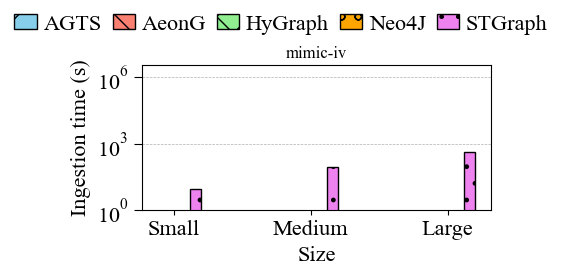

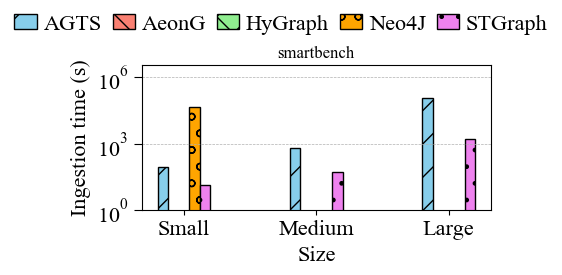

In [720]:
def print_ingestion_statistics(ingestion_statistics: pd.DataFrame):
    """
    Print ingestion statistics bar plot (log scale, clipped values, scalable patterns),
    con padding minimo sopra il limite di clipping.
    """
    import matplotlib.patches as mpatches

    df = clean_df(ingestion_statistics.copy(deep=True), threads=1, numMachines=single_machine)
    
    # df = df[~((df["model"] == "Neo4J") & (df["datasetSize"] == "Medium"))]
    grouped = df.groupby(["dataset", "datasetSize", "model"], observed=True)["elapsedTime"].mean().reset_index()
    print_latex(grouped)
    all_models = sorted(grouped["model"].unique())
    all_datasets = sorted(grouped["dataset"].unique())
    num_models = len(all_models)
    bar_width = min(0.4 / num_models, 0.09)
    x = np.arange(len(dataset_order))

    for _, dataset in enumerate(all_datasets):
        fig, ax = plt.subplots(figsize=(fig_x * 1.5, fig_y))
        for i, model in enumerate(all_models):
            offset = (i - (num_models - 1) / 2) * bar_width
            for j, ds in enumerate(dataset_order):
                subset = grouped[(grouped["datasetSize"] == ds) & (grouped["model"] == model) & (grouped["dataset"] == dataset)]
                if subset.empty:
                    continue
                if model != "STGraph" and dataset == "smartbench":  # Sottrai il tempo di processing CSV solo per i modelli diversi da STGraph su SmartBench
                    # csvTime = ((df[(df["model"] == "STGraph") & (df["datasetSize"] == ds)]["endTimestamp"] - df[(df["model"] == "STGraph") & (df["datasetSize"] == ds)]["startTimestamp"]) / 1000 - df[(df["model"] == "STGraph") & (df["datasetSize"] == ds)]["elapsedTime"]).mean()
                    csvTime = 0
                    # print(f"Average CSV processing time (s): {csvTime:.2f}")
                    #if model == "HyGraph" and dataset == "smartbench" and ds == "Medium":
                    #    value = 13.13 * 2
                    #else:
                    # print(f"STGraph elapsed time (s): {subset['elapsedTime'].values[0]:.2f}, CSV processing time (s): {csvTime:.2f}")
                    value = subset["elapsedTime"].values[0] - csvTime  # Sottrai il tempo di processing CSV
                else:
                    csvTime = 0
                    value = subset["elapsedTime"].values[0]
                # print(f"Model: {model}, Dataset: {ds}, Elapsed Time (s): {value + csvTime}, Elapsed Time - CSV (s): {value}")
                display_value = min(value, CLIP_VALUE)
                ax.bar(x[j] + offset, display_value, width=bar_width, color=colors[i % len(colors)], edgecolor='black', hatch=patterns[i % len(patterns)], label=model if j == 0 else None)
                if value >= CLIP_VALUE:
                    ax.text(x[j] + offset, CLIP_VALUE, f"X", va='center', ha='center', fontsize=font - 2, rotation=0, c="red")
                    # ax.text(x[j] + offset, CLIP_VALUE * 1.1, f"FAIL", va='bottom', ha='center', fontsize=font - 2, rotation=45, bbox=dict(facecolor='white', edgecolor='black', linewidth=0.5, alpha=0.9, pad=1.5))
                    # ax.text(x[j] + offset, CLIP_VALUE * 1.1, f"{value:.2e}", va='bottom', ha='center', fontsize=font - 2, rotation=45, bbox=dict(facecolor='white', edgecolor='black', linewidth=0.5, alpha=0.9, pad=1.5))
        ax.set_xticks(x)
        ax.set_xticklabels(dataset_order, fontsize=font)
        ax.set_xlabel("Size", fontsize=font)
        ax.set_yscale("log")
        ax.set_ylim(1, CLIP_VALUE * 3.5)
        ax.tick_params(axis='y', which='both', length=6, labelsize=font)
        ax.yaxis.grid(True, linestyle='--', linewidth=0.5, which='major')
        ax.set_ylabel("Ingestion time (s)", fontsize=font)
        handles = [
            mpatches.Patch(facecolor=colors[i % len(colors)], hatch=patterns[i % len(patterns)], edgecolor='black', label=model)
            for i, model in enumerate(all_models)
        ]
        fig.legend(handles=handles, ncol=len(all_models), **legend_settings)
        plt.title(f"{dataset}")
        plt.tight_layout()
        plt.savefig(os.path.join(figures_path, f"ingestion_statistics_{dataset}.pdf"), bbox_inches='tight')
        plt.show()

print_ingestion_statistics(ingestion_statistics)


In [721]:
def speed_up(df, group_cols = ["dataset", "datasetSize", "queryid"], column="model", baseline="STGraph", denominator=True):
    avg_times = (
        df.groupby(group_cols + [column], dropna=False, observed=True)["elapsedTime"]
        .mean()
        .reset_index()
        .rename(columns={"elapsedTime": "avgElapsedTime"})
    )
    def trimmed_mean(s):
        s = s.dropna().sort_values()
        if len(s) <= 2:
            return s.mean()
        boundary = 2 if len(s) > 4 else 1
        return s.iloc[boundary:-boundary].mean()   # drop min and max
    stgraph = (
        avg_times[avg_times[column] == baseline]
        [group_cols + ["avgElapsedTime"]]
        .rename(columns={"avgElapsedTime": baseline})
    )
    others = (
        avg_times[avg_times[column] != baseline]
        .rename(columns={
            column: "otherModel",
            "avgElapsedTime": "otherModelElapsedTime"
        })
    )
    result = others.merge(stgraph, on=group_cols, how="inner")
    result["speedup"] = (
        # result["otherModelElapsedTime"]
        # (result["otherModelElapsedTime"] - result["STGraph"]) / result["STGraph"]
        (result["otherModelElapsedTime"] / result[baseline]) if denominator else (result[baseline] / result["otherModelElapsedTime"])
        # result["STGraph"]
    )
    pivoted = (
        result.pivot_table(
            index=group_cols + [baseline],
            columns="otherModel",
            values="speedup", observed=True
        )
        .reset_index()
    )
    pivoted.columns.name = None
    pivoted = pivoted.groupby(["dataset", "datasetSize"], observed=True)[sorted([x for x in df[column].unique() if x != baseline])].agg(trimmed_mean).reset_index()
    return print_latex(pivoted, pivot=["dataset", "Size"], columns=None, scinotation=False)

speed_up(clean_df(ingestion_statistics.copy(deep=True), threads=1, numMachines=single_machine),  group_cols = ["dataset", "datasetSize"], column="model", baseline="STGraph", denominator=True)

\begin{tabular}{llrrrr}
\toprule
 &  & AGTS & AeonG & HyGraph & Neo4J \\
dataset & Size &  &  &  &  \\
\midrule
\multirow[t]{3}{*}{mimic-iv} & S & -- & 0.0 & -0.0 & -- \\
 & M & -- & 0.0 & -0.0 & -- \\
 & L & -- & -0.0 & -0.0 & -- \\
\cline{1-6}
\multirow[t]{3}{*}{smartbench} & S & 6.7 & 0.0 & -0.0 & 3447.9 \\
 & M & 11.6 & 0.0 & -0.0 & -0.0 \\
 & L & 70.9 & -0.0 & -0.0 & -0.0 \\
\cline{1-6}
\bottomrule
\end{tabular}



In [722]:
def clean_df_stats(
    df,
    numMachines=None,
    threads=None,
    groupby_cols=None,
    queryMode=None,
    queryid=["Q1", "Q2", "Q3", "Q4", "Q5", "Q6"],
    queryid_exact_match=False,
    model=None
):
    # -------------------------
    # Base cleaning
    # -------------------------
    df["numMachines"] = df["numMachines"].replace(-1, 1)
    df["numMachines"] = df["numMachines"].fillna(1).astype(int)
    df = clean_df(df, threads=threads, numMachines=numMachines)
    df["queryMode"] = df["queryMode"].fillna("OPTIMIZED")
    if queryMode is not None:
        df = df[df["queryMode"] == queryMode]
    if model is not None:
        df = df[df["model"] == model]
    # -------------------------
    # Query ID normalization
    # -------------------------
    df["queryid"] = df["queryid"].fillna(df["queryName"])
    df["queryid"] = df["queryid"].apply(lambda x: str(x).replace("Neo4J", "").replace("PGAge", ""))
    df["queryid"] = df["queryid"].apply(lambda x: query_names.get(x, x))
    if queryid is not None:
        if queryid_exact_match:
            df = df[df["queryid"].isin(queryid)]
        else:
            df = df[df["queryid"].apply(lambda x: len([y for y in queryid if y in x]) > 0 )]
    # -------------------------
    # Query selectivity filter
    # -------------------------
    df["querySelectivity"] = df["querySelectivity"].fillna("increased")
    df = df[(df["querySelectivity"].isna()) | (df["querySelectivity"] == "increased")]
    # -------------------------
    # Remove specific cases
    # -------------------------
    models_to_filter = ["AeonG", "HyGraph", "Neo4J"]
    df["model"] = df["model"].apply(lambda x: x.replace("neo4j", "Neo4J").replace("stgraph", "STGraph").replace("PGAge", "AGTS"))
    df = df[~(
        df["queryName"].isin(["EnvironmentOutlier", "EnvironmentAlert"]) &
        df["model"].isin(models_to_filter)
    )]
    # -------------------------
    # Numeric safety
    # -------------------------
    df["elapsedTime"] = pd.to_numeric(df["elapsedTime"].fillna(-1), errors="coerce")
    df["cardinality"] = pd.to_numeric(df["cardinality"].fillna(-1), errors="coerce")
    # df = df.dropna(subset=["elapsedTime", "cardinality"])
    # -------------------------
    # Group + aggregate (dynamic)
    # -------------------------
    if groupby_cols is not None:
        df_grouped = (
            df
            .groupby(groupby_cols, as_index=False, observed=True)
            .agg({
                "elapsedTime": "mean",
                "cardinality": "mean"
            })
            .sort_values(groupby_cols)
        )
    else:
        df_grouped = df
    return df_grouped


In [723]:
speed_up(clean_df_stats(query_statistics.copy(deep=True), threads=1, numMachines=1, queryMode="OPTIMIZED", queryid=["Q1", "Q2", "Q3", "Q4", "Q5", "Q6", "Q7"], queryid_exact_match=True), denominator=True)


\begin{tabular}{llrrrr}
\toprule
 &  & AGTS & AeonG & HyGraph & Neo4J \\
dataset & Size &  &  &  &  \\
\midrule
\multirow[t]{3}{*}{mimic} & S & 2.2 & 5.7 & 9445.5 & 2.6 \\
 & M & 22.3 & 35.3 & 14205.1 & 1.7 \\
 & L & 260.0 & -- & -- & 1.7 \\
\cline{1-6}
\multirow[t]{3}{*}{smartbench} & S & 4.3 & 39.7 & 41.7 & 1.8 \\
 & M & 7.7 & 37.9 & 40.7 & 2.1 \\
 & L & 4.8 & -- & -- & 4.8 \\
\cline{1-6}
\bottomrule
\end{tabular}



Query statistics - <b>different</b> selectivity across dataset size

\begin{tabular}{llllllll}
\toprule
 &  & Model & AGTS & AeonG & HyGraph & Neo4J & STGraph \\
dataset & Size & ID &  &  &  &  &  \\
\midrule
\multirow[t]{9}{*}{mimic} & \multirow[t]{3}{*}{S} & Q1 & $1.1 \cdot 10^{0}$ & $2.3 \cdot 10^{0}$ & $4.1 \cdot 10^{3}$ & $1.4 \cdot 10^{0}$ & $1.3 \cdot 10^{0}$ \\
 &  & Q2 & $8.7 \cdot 10^{-1}$ & $2.3 \cdot 10^{0}$ & $3.7 \cdot 10^{3}$ & $1.0 \cdot 10^{0}$ & $4.0 \cdot 10^{-1}$ \\
 &  & Q3 & $6.8 \cdot 10^{-1}$ & $2.2 \cdot 10^{0}$ & $4.1 \cdot 10^{3}$ & $1.3 \cdot 10^{0}$ & $3.0 \cdot 10^{-1}$ \\
\cline{2-8}
 & \multirow[t]{3}{*}{M} & Q1 & $5.6 \cdot 10^{1}$ & $9.3 \cdot 10^{1}$ & $4.1 \cdot 10^{4}$ & $9.6 \cdot 10^{0}$ & $7.9 \cdot 10^{0}$ \\
 &  & Q2 & $5.8 \cdot 10^{1}$ & $9.3 \cdot 10^{1}$ & $3.7 \cdot 10^{4}$ & $4.6 \cdot 10^{0}$ & $2.6 \cdot 10^{0}$ \\
 &  & Q3 & $6.6 \cdot 10^{1}$ & $9.2 \cdot 10^{1}$ & $4.1 \cdot 10^{4}$ & $9.2 \cdot 10^{0}$ & $1.8 \cdot 10^{0}$ \\
\cline{2-8}
 & \multirow[t]{3}{*}{L} & Q1 & $5.6 \cdot 10^{3}$ & -- & -- & 

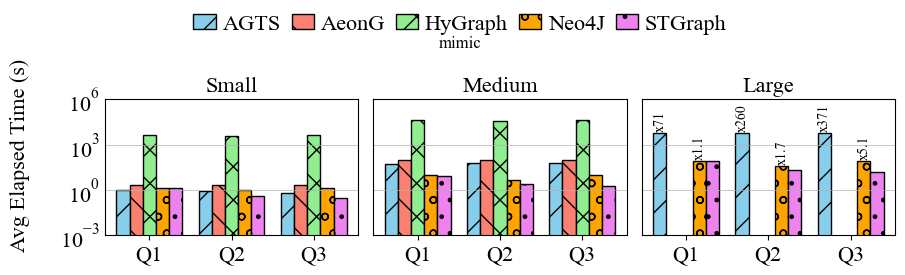

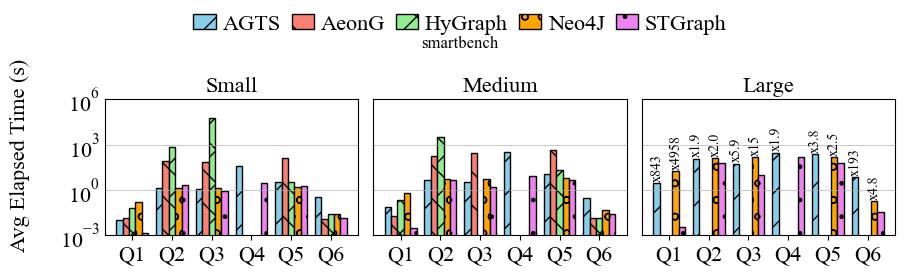

In [724]:
def print_query_statistics(query_df: pd.DataFrame):
    print_latex(query_df.dropna(subset=["elapsedTime"]).groupby(["dataset", "datasetSize", "queryid", "model"], observed=True)["elapsedTime"].mean().reset_index(), pivot=["dataset", "Size", "ID"])
    all_models = sorted(query_df["model"].unique())
    num_models = len(all_models)
    bar_width = min(0.8 / num_models, 0.18)
    for dataset in sorted(query_df["dataset"].unique()):
        fig, axes = plt.subplots(1, len(dataset_order), figsize=(fig_x * len(dataset_order), fig_y), sharey=True)
        if len(dataset_order) == 1: axes = [axes]
        for ax, ds in zip(axes, dataset_order):
            df_filtered = query_df[(query_df["dataset"] == dataset) & (query_df["datasetSize"] == ds)]
            grouped = df_filtered.groupby(["queryid", "model"], observed=True)["elapsedTime"].mean().reset_index()
            query_ids = sorted(grouped["queryid"].unique())
            x = np.arange(len(query_ids))

            for i, model in enumerate(all_models):
                values = [
                    grouped[
                        (grouped["queryid"] == q) &
                        (grouped["model"] == model)
                    ]["elapsedTime"].values[0]
                    if not grouped[
                        (grouped["queryid"] == q) &
                        (grouped["model"] == model)
                    ].empty
                    else np.nan
                    for q in query_ids
                ]

                offset = (i - (num_models - 1) / 2) * bar_width

                ax.bar(
                    x + offset,
                    values,
                    width=bar_width,
                    color=colors[i % len(colors)],
                    edgecolor="black",
                    hatch=patterns[i % len(patterns)],
                    label=model if ds == dataset_order[0] else None
                )

            # Su Large, sopra ogni barra tranne STGraph: quante volte è più lenta di STGraph sulla stessa query (es. x4.8)
            if ds == "Large" and "STGraph" in all_models:
                base = grouped[grouped["model"] == "STGraph"].set_index("queryid")["elapsedTime"]
                for i, model in enumerate(all_models):
                    if model == "STGraph":
                        continue
                    model_values = grouped[grouped["model"] == model].set_index("queryid")["elapsedTime"]
                    for j, q in enumerate(query_ids):
                        if q in model_values.index and q in base.index and model_values[q] > 0 and base[q] > 0:
                            ratio = model_values[q] / base[q]
                            ax.text(x[j] + (i - (num_models - 1) / 2) * bar_width, model_values[q] * 1.3,
                                    f"x{ratio:.0f}" if ratio >= 10 else f"x{ratio:.1f}",
                                    rotation=90, ha="center", va="bottom", fontsize=font - 6)

            # --- X axis ---
            ax.set_xticks(x)
            ax.set_xticklabels(query_ids, fontsize=font)  # tick X più grandi

            # --- Y axis ---
            ax.set_yscale("log")
            ax.set_ylim(0.001, CLIP_VALUE)
            ax.tick_params(axis="y", which="major", labelsize=font)
            ax.tick_params(axis="y", which="both", length=0)
            ax.yaxis.grid(True, which='major', linestyle='-', linewidth=0.5)
            ax.set_title(ds, fontsize=font)

        ylabel = fig.supylabel("Avg Elapsed Time (s)", fontsize=font)
        ylabel.set_position((-0.00005, 0.5))  # sposta più vicino ai tick senza sovrapporsi
        handles, labels = axes[0].get_legend_handles_labels()
        fig.legend(handles, labels, ncol=len(all_models), **legend_settings)
        plt.suptitle(f"{dataset}")
        plt.tight_layout()  # margini ottimizzati
        plt.savefig(os.path.join(figures_path, f"query_statistics_{dataset}.svg"), bbox_inches='tight')
        plt.show()

query_df = clean_df_stats(query_statistics.copy(deep=True), threads=1, numMachines=1, queryMode="OPTIMIZED", queryid=["Q1", "Q2", "Q3", "Q4", "Q5", "Q6", "Q7"], queryid_exact_match=True)
print_query_statistics(query_df)

\begin{tabular}{lllllllll}
\toprule
 &  & ID & Q1 & Q2 & Q3 & Q4 & Q5 & Q6 \\
dataset & Size & queryMode &  &  &  &  &  &  \\
\midrule
\multirow[t]{5}{*}{mimic} & \multirow[t]{2}{*}{S} & NAIVE & $6.8 \cdot 10^{0}$ & $7.1 \cdot 10^{0}$ & $7.2 \cdot 10^{0}$ & -- & -- & -- \\
 &  & OPTIMIZED & $1.3 \cdot 10^{0}$ & $4.0 \cdot 10^{-1}$ & $3.0 \cdot 10^{-1}$ & -- & -- & -- \\
\cline{2-9}
 & \multirow[t]{2}{*}{M} & NAIVE & $4.7 \cdot 10^{1}$ & $4.6 \cdot 10^{1}$ & $3.9 \cdot 10^{1}$ & -- & -- & -- \\
 &  & OPTIMIZED & $7.9 \cdot 10^{0}$ & $2.6 \cdot 10^{0}$ & $1.8 \cdot 10^{0}$ & -- & -- & -- \\
\cline{2-9}
 & L & OPTIMIZED & $7.9 \cdot 10^{1}$ & $2.2 \cdot 10^{1}$ & $1.5 \cdot 10^{1}$ & -- & -- & -- \\
\cline{1-9} \cline{2-9}
\multirow[t]{8}{*}{smartbench} & \multirow[t]{2}{*}{--} & NAIVE & $3.5 \cdot 10^{-3}$ & -- & -- & -- & -- & $3.7 \cdot 10^{1}$ \\
 &  & OPTIMIZED & $3.5 \cdot 10^{-3}$ & $1.6 \cdot 10^{2}$ & $1.3 \cdot 10^{1}$ & $9.5 \cdot 10^{2}$ & $1.4 \cdot 10^{2}$ & $4.4 \cdot 10^{-

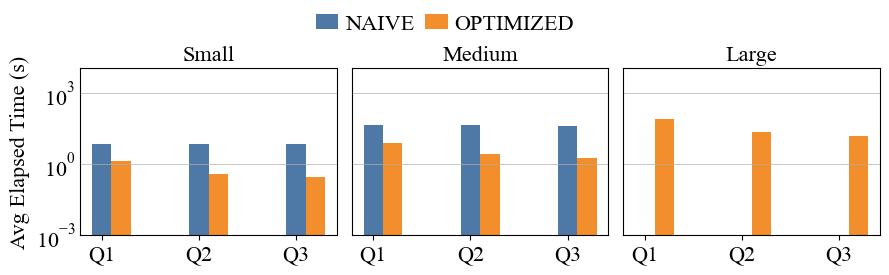

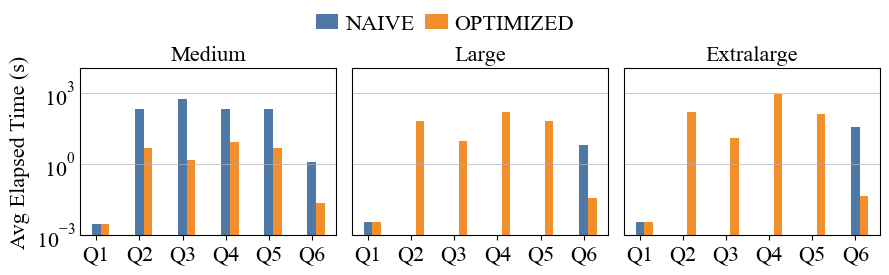

In [725]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


def plot_per_dataset(df_grouped, column="queryMode", title="opt", onlylast=False):
    datasets = df_grouped["dataset"].unique()
    print_latex(df_grouped.dropna().groupby(["dataset", "datasetSize", "queryid", column], observed=True)["elapsedTime"].mean().reset_index(), pivot=["dataset", "Size", column], columns="ID")
    for dataset in datasets:
        df_d = df_grouped[df_grouped["dataset"] == dataset]
        sizes = ["Small", "Medium", "Large", "Extralarge"]
        if title == "opt" and dataset == "smartbench":
            sizes = ["Medium", "Large", "Extralarge"]
        sizes = [s for s in sizes if s in df_d["datasetSize"].unique()]
        if onlylast:
            sizes = [sizes[-1]]
        query_ids = sorted(df_d["queryid"].unique())
        query_modes = sorted(df_d[column].unique())

        if onlylast:
            nrows, ncols = 1, 1
        else:
            nrows = 2 if len(sizes) > 3 else 1
            ncols = 3

        fig, axes = plt.subplots(
            nrows,
            ncols,
            figsize=(fig_x * ncols, fig_y * nrows),
            sharey=True
        )

        axes = np.atleast_1d(axes).flatten()

        for i in range(len(sizes), len(axes)):
            axes[i].set_visible(False)

        axes = axes[:len(sizes)]

        j = 0
        for ax, size in zip(axes, sizes):
            df_s = df_d[df_d["datasetSize"] == size]

            # pivot: rows=queryid, cols=queryMode
            pivot = df_s.pivot(
                index="queryid",
                columns=column,
                values="elapsedTime"
            ).reindex(query_ids)

            x = np.arange(len(query_ids))
            width = 0.2 # 0.8 / len(query_modes)

            for i, mode in enumerate(query_modes):
                values = pivot[mode] if mode in pivot else [0]*len(query_ids)

                bars = ax.bar(
                    x + i * width,
                    values,
                    width=width,
                    label=mode
                )
            ax.set_title(f"Size: {size}")
            ax.set_xticks(x + width * (len(query_modes) - 1) / 2)
            # --- X axis ---
            ax.set_xticks(x)
            ax.set_xticklabels(query_ids, fontsize=font)  # tick X più grandi

            # --- Y axis ---
            ax.set_yscale("log")
            ax.set_ylim(0.001, 11000)
            ax.tick_params(axis="y", which="major", labelsize=font)
            ax.tick_params(axis="y", which="both", length=0)
            ax.yaxis.grid(True, which='major', linestyle='-', linewidth=0.5)
            ax.set_title(size, fontsize=font)
            if (j % 3 == 0):
                ax.set_ylabel("Avg Elapsed Time (s)", fontsize=font)
            j += 1


        # shared legend
        handles, labels = axes[0].get_legend_handles_labels()
        fig.legend(handles, labels, ncol=len(query_modes), **legend_settings)
        # plt.suptitle(f"{dataset}")
        plt.tight_layout()  # margini ottimizzati
        plt.savefig(os.path.join(figures_path, f"query_{title}_{dataset}.pdf"), bbox_inches='tight')
        plt.show()

df_grouped = clean_df_stats(query_statistics.copy(deep=True), threads=1, numMachines=1, groupby_cols=["dataset", "datasetSize", "queryid", "queryMode"], queryid_exact_match=True, model="STGraph")
plot_per_dataset(df_grouped, title="opt", onlylast=False)

/tmp/ipykernel_1387/2614226497.py:72: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["elapsedTime"] = pd.to_numeric(df["elapsedTime"], errors="coerce") / 1000


\begin{tabular}{lllllllll}
\toprule
 &  & ID & Q1 & Q2 & Q3 & Q4 & Q5 & Q6 \\
dataset & Size & threads &  &  &  &  &  &  \\
\midrule
\multirow[t]{12}{*}{mimic} & \multirow[t]{4}{*}{S} & 1 & $1.3 \cdot 10^{0}$ & $4.0 \cdot 10^{-1}$ & $3.0 \cdot 10^{-1}$ & -- & -- & -- \\
 &  & 4 & $4.1 \cdot 10^{-1}$ & $1.2 \cdot 10^{-1}$ & $9.3 \cdot 10^{-2}$ & -- & -- & -- \\
 &  & 8 & $4.0 \cdot 10^{-1}$ & $1.0 \cdot 10^{-1}$ & $5.4 \cdot 10^{-2}$ & -- & -- & -- \\
 &  & 16 & $3.9 \cdot 10^{-1}$ & $9.7 \cdot 10^{-2}$ & $5.0 \cdot 10^{-2}$ & -- & -- & -- \\
\cline{2-9}
 & \multirow[t]{4}{*}{M} & 1 & $7.9 \cdot 10^{0}$ & $2.6 \cdot 10^{0}$ & $1.8 \cdot 10^{0}$ & -- & -- & -- \\
 &  & 4 & $2.1 \cdot 10^{0}$ & $7.0 \cdot 10^{-1}$ & $4.7 \cdot 10^{-1}$ & -- & -- & -- \\
 &  & 8 & $1.4 \cdot 10^{0}$ & $4.8 \cdot 10^{-1}$ & $3.2 \cdot 10^{-1}$ & -- & -- & -- \\
 &  & 16 & $1.2 \cdot 10^{0}$ & $4.0 \cdot 10^{-1}$ & $3.0 \cdot 10^{-1}$ & -- & -- & -- \\
\cline{2-9}
 & \multirow[t]{4}{*}{L} & 1 & $7.9 \cdot 10

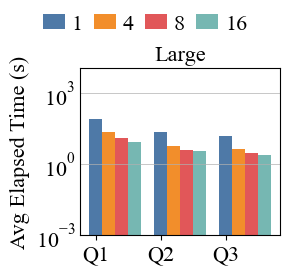

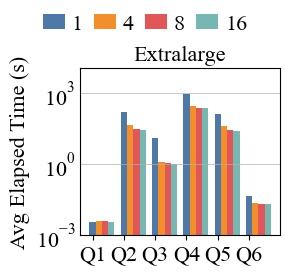

In [726]:
df_grouped = clean_df_stats(query_statistics.copy(deep=True), queryMode="OPTIMIZED", numMachines=1, groupby_cols=["dataset", "datasetSize", "queryid", "threads"], queryid_exact_match=True, model="STGraph")
plot_per_dataset(df_grouped, column="threads", title="threads", onlylast=True)

In [727]:
speed_up(df_grouped, column="threads", baseline=1, denominator=False)

\begin{tabular}{llrrr}
\toprule
 &  & 4 & 8 & 16 \\
dataset & Size &  &  &  \\
\midrule
\multirow[t]{3}{*}{mimic} & S & 3.2 & 3.8 & 4.1 \\
 & M & 3.7 & 5.5 & 6.5 \\
 & L & 3.6 & 5.6 & 6.5 \\
\cline{1-5}
\multirow[t]{4}{*}{smartbench} & S & 3.4 & 4.9 & 5.4 \\
 & M & 3.2 & 4.4 & 4.9 \\
 & L & 2.9 & 3.9 & 4.3 \\
 & -- & 3.3 & 4.5 & 4.9 \\
\cline{1-5}
\bottomrule
\end{tabular}



\begin{tabular}{lllllllll}
\toprule
 &  & ID & Q1 & Q2 & Q3 & Q4 & Q5 & Q6 \\
dataset & Size & numMachines &  &  &  &  &  &  \\
\midrule
\multirow[t]{9}{*}{mimic} & \multirow[t]{3}{*}{S} & 1 & $3.9 \cdot 10^{-1}$ & $9.7 \cdot 10^{-2}$ & $5.0 \cdot 10^{-2}$ & -- & -- & -- \\
 &  & 2 & $6.1 \cdot 10^{-1}$ & $3.3 \cdot 10^{-1}$ & $1.0 \cdot 10^{-1}$ & -- & -- & -- \\
 &  & 4 & $4.2 \cdot 10^{-1}$ & $8.5 \cdot 10^{-2}$ & $6.9 \cdot 10^{-2}$ & -- & -- & -- \\
\cline{2-9}
 & \multirow[t]{3}{*}{M} & 1 & $1.2 \cdot 10^{0}$ & $4.0 \cdot 10^{-1}$ & $3.0 \cdot 10^{-1}$ & -- & -- & -- \\
 &  & 2 & $1.3 \cdot 10^{0}$ & $4.0 \cdot 10^{-1}$ & $2.2 \cdot 10^{-1}$ & -- & -- & -- \\
 &  & 4 & $1.1 \cdot 10^{0}$ & $3.0 \cdot 10^{-1}$ & $2.5 \cdot 10^{-1}$ & -- & -- & -- \\
\cline{2-9}
 & \multirow[t]{3}{*}{L} & 1 & $8.8 \cdot 10^{0}$ & $3.5 \cdot 10^{0}$ & $2.4 \cdot 10^{0}$ & -- & -- & -- \\
 &  & 2 & $1.0 \cdot 10^{1}$ & $2.4 \cdot 10^{0}$ & $1.7 \cdot 10^{0}$ & -- & -- & -- \\
 &  & 4 & $9.7 \cdot 10^

/tmp/ipykernel_1387/2614226497.py:72: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["elapsedTime"] = pd.to_numeric(df["elapsedTime"], errors="coerce") / 1000


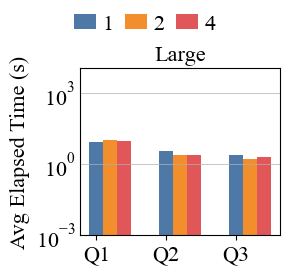

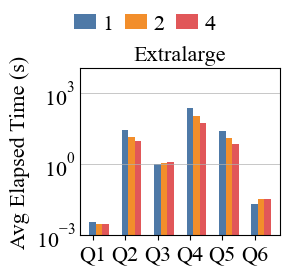

In [728]:
df_grouped = clean_df_stats(query_statistics.copy(deep=True), queryMode="OPTIMIZED", threads=16, groupby_cols=["dataset", "datasetSize", "queryid", "numMachines"], queryid_exact_match=True, model="STGraph")
plot_per_dataset(df_grouped, column="numMachines", title="numMachines", onlylast=True)

In [729]:
speed_up(df_grouped, column="numMachines", baseline=1, denominator=False)

\begin{tabular}{llrr}
\toprule
 &  & 2 & 4 \\
dataset & Size &  &  \\
\midrule
\multirow[t]{3}{*}{mimic} & S & 0.5 & 0.9 \\
 & M & 1.0 & 1.2 \\
 & L & 1.4 & 1.2 \\
\cline{1-4}
\multirow[t]{4}{*}{smartbench} & S & 0.9 & 0.9 \\
 & M & 1.1 & 1.0 \\
 & L & 1.1 & 1.2 \\
 & -- & 1.5 & 2.0 \\
\cline{1-4}
\bottomrule
\end{tabular}



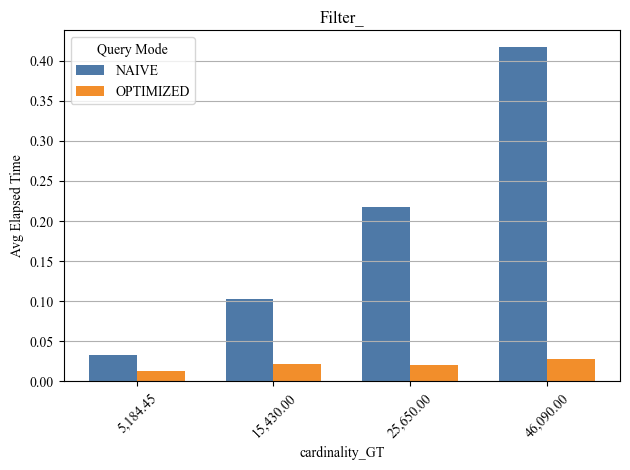

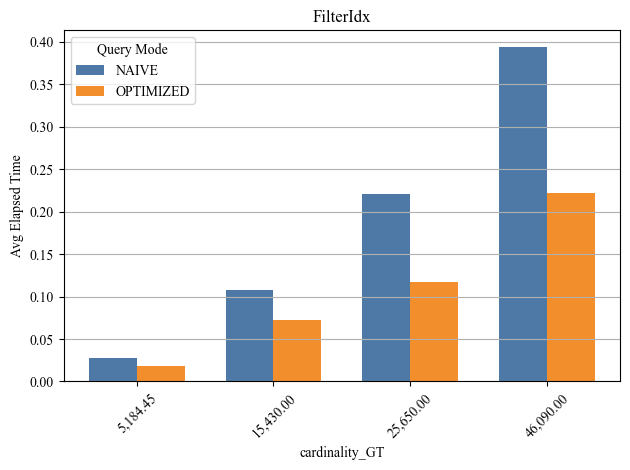

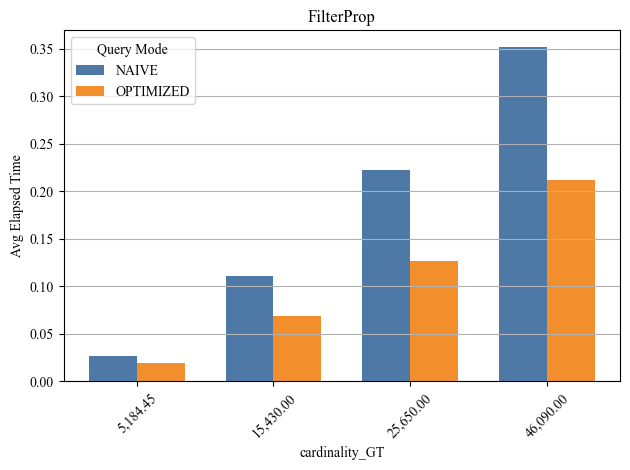

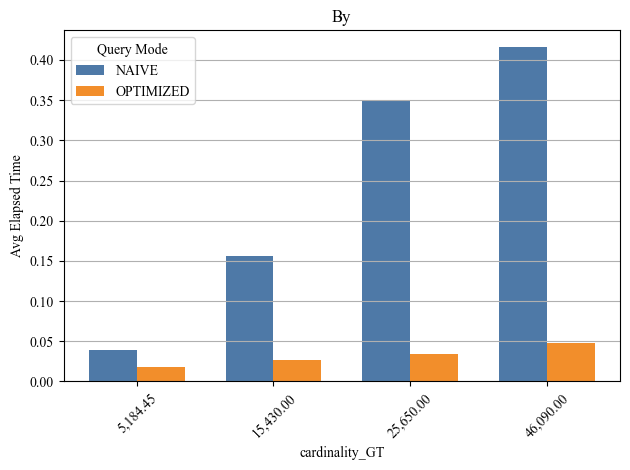

In [730]:
def plot_s(df_grouped, filter):
    for col in ["cardinality_GT"]: # , "cardinality_ratio", "cardinality"
        # --- parameters ---
        num_bins = 5

        df_grouped["card_bin"] = pd.cut(df_grouped[col], bins=num_bins)

        # df_grouped["card_bin"] = df_grouped[col]

        # aggregate
        agg = (
            df_grouped.groupby(["queryMode", "card_bin"], observed=True)
            .agg({
                "elapsedTime": "mean"
            })
            .reset_index()
        )

        # pivot → rows = bins, columns = queryModes
        pivot = agg.pivot(index="card_bin", columns="queryMode", values="elapsedTime")

        # use bin centers for labels (cleaner than intervals)
        bin_centers = [interval.mid for interval in pivot.index]

        # --- plotting ---
        x = np.arange(len(pivot))  # bin positions
        width = 0.35               # bar width

        plt.figure()

        for i, mode in enumerate(pivot.columns):
            plt.bar(
                x + i * width,
                pivot[mode],
                width=width,
                label=mode
            )

        plt.xticks(x + width * (len(pivot.columns) - 1) / 2, [f"{c:,.2f}" for c in bin_centers], rotation=45)
        plt.xlabel(col)
        plt.ylabel("Avg Elapsed Time")
        plt.title(filter)
        plt.legend(title="Query Mode")
        plt.grid(axis="y")

        plt.tight_layout()
        plt.show()

df_grouped = clean_df_stats(query_statistics.copy(deep=True), threads=1, numMachines=1, groupby_cols=["dataset", "datasetSize", "queryid", "queryMode"], queryid=["Filter_", "FilterIdx", "FilterProp", "By"])
df_grouped["cardinality_GT"] = df_grouped["queryid"].apply(lambda x: x.split("_")[2]).astype(int)
df_grouped["queryType"] = df_grouped["queryid"].apply(lambda x: x.split("_")[0])
df_grouped["cardinality_ratio"] = df_grouped["cardinality"] / df_grouped["cardinality_GT"]
df_grouped.to_csv(os.path.join(statistics_path, "query_statistics_filtered.csv"), index=False)

for filter in ["Filter_", "FilterIdx", "FilterProp", "By"]:
    df_grouped = clean_df_stats(query_statistics.copy(deep=True), threads=1, numMachines=1, groupby_cols=["dataset", "datasetSize", "queryid", "queryMode"], queryid=[filter])
    df_grouped["cardinality_GT"] = df_grouped["queryid"].apply(lambda x: x.split("_")[2]).astype(int)
    df_grouped["cardinality_ratio"] = df_grouped["cardinality"] / df_grouped["cardinality_GT"]
    plot_s(df_grouped, filter)

In [731]:
# Di nuovo tutti i dati (paper e rebuttal), e query_df come nella cella dei grafici delle query, per le celle seguenti
query_statistics, ingestion_statistics = all_query_statistics, all_ingestion_statistics
query_df = clean_df_stats(query_statistics.copy(deep=True), threads=1, numMachines=1, queryMode="OPTIMIZED", queryid=["Q1", "Q2", "Q3", "Q4", "Q5", "Q6", "Q7"], queryid_exact_match=True)

In [732]:
graphix_df = query_df.loc[(query_df["model"].str.contains("Graph")) & (query_df["dataset"] == "smartbench") & (query_df["model"] != "HyGraph")]
graphix_df

,test_id,model,dataset,datasetSize,threads,queryName,queryType,elapsedTime,numEntities,numMachines,querySelectivity,temporalRangeIndex,iteration,queryid,cardinality,queryMode,sortBy
2436,471fa8ee-86de-441a-adff-7074306b7f98,STGraph,smartbench,Extralarge,1,NaN,NaN,0.047,NaN,1,increased,NaN,NaN,Q6,1.0,OPTIMIZED,AgentHistory extralarge
2437,056a9ad9-2ee2-4df4-a74f-0d1dae0b4b48,STGraph,smartbench,Extralarge,1,NaN,NaN,0.046,NaN,1,increased,NaN,NaN,Q6,1.0,OPTIMIZED,AgentHistory extralarge
2447,6317c7d2-ebd2-44c2-b4a4-b7c8c555b456,STGraph,smartbench,Extralarge,1,NaN,NaN,0.041,NaN,1,increased,NaN,NaN,Q6,1.0,OPTIMIZED,AgentHistory extralarge
2448,b4e4648a-5c31-4f57-a22e-7cf131701b93,STGraph,smartbench,Extralarge,1,NaN,NaN,0.041,NaN,1,increased,NaN,NaN,Q6,1.0,OPTIMIZED,AgentHistory extralarge
2457,3756d7cb-99ae-4e63-8b57-85ed52f5200e,STGraph,smartbench,Large,1,NaN,NaN,0.039,NaN,1,increased,NaN,NaN,Q6,1.0,OPTIMIZED,AgentHistory large
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6876,f1d6921b-72c3-446c-96be-cd6e97924231,Graphix_3CPU_12GB,smartbench,Medium,1,NaN,NaN,13.291,NaN,1,increased,NaN,NaN,Q2,95.0,OPTIMIZED,9 increased 0
6877,44e38db5-184c-4f33-9ea0-faf4dda7dd33,Graphix_3CPU_12GB,smartbench,Medium,1,NaN,NaN,13.484,NaN,1,increased,NaN,NaN,Q3,200.0,OPTIMIZED,9 increased 0
6878,5397315a-b42f-486d-a868-b7fbf1dbe483,Graphix_3CPU_12GB,smartbench,Medium,1,NaN,NaN,15.788,NaN,1,increased,NaN,NaN,Q4,3.0,OPTIMIZED,9 increased 0
6879,ca6ba82b-9daf-48e9-8d24-bbc3c1d14a04,Graphix_3CPU_12GB,smartbench,Medium,1,NaN,NaN,16.571,NaN,1,increased,NaN,NaN,Q5,200.0,OPTIMIZED,9 increased 0


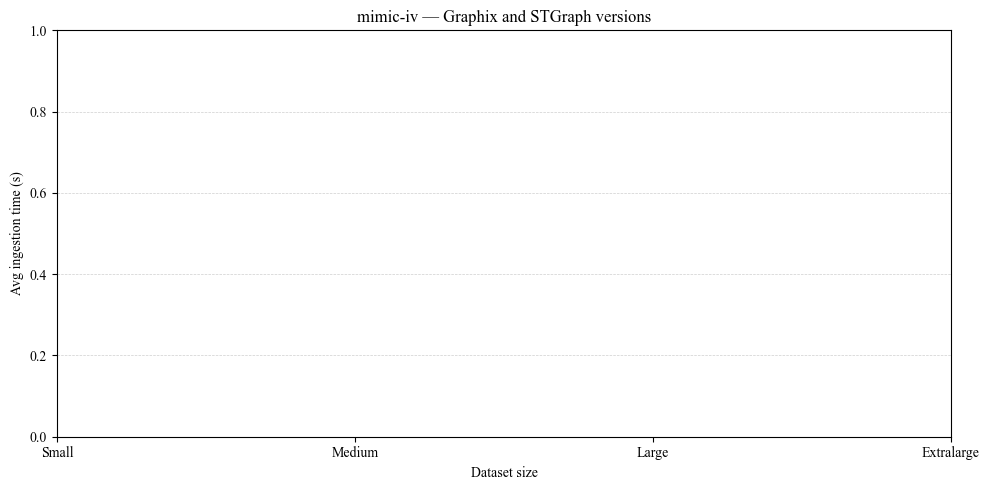

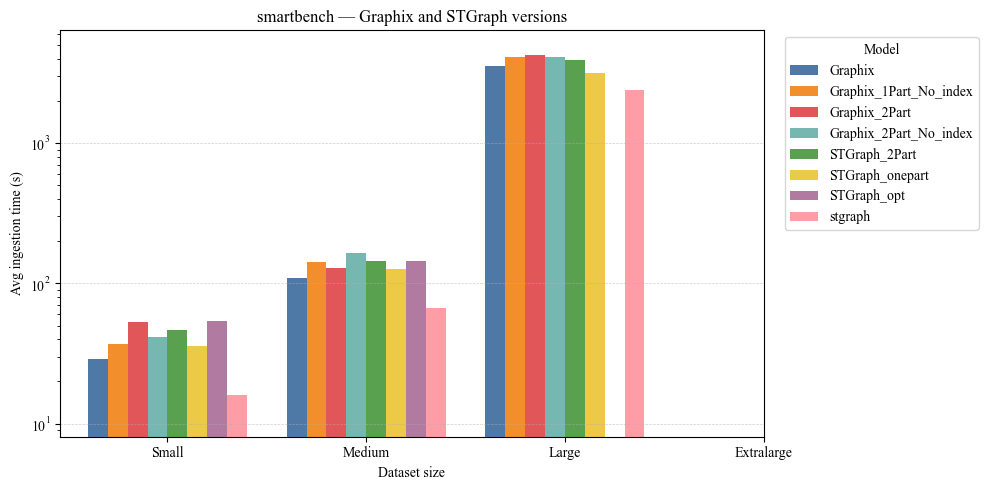

In [733]:
graphix_ingestion_versions = [
    "Graphix",
    "Graphix_2Part",
    "Graphix_2Part_No_index",
    "Graphix_1Part_No_index",
]
stgraph_ingestion_versions = [
    "STGraph",
    "STGraph_onepart",
    "STGraph_2Part",
    "STGraph_opt",
    "stgraph",
]

ingestion_compare = (
    ingestion_statistics[
        ingestion_statistics["model"].isin(graphix_ingestion_versions + stgraph_ingestion_versions)
    ].copy()
)
ingestion_compare["datasetSize"] = ingestion_compare["datasetSize"].astype(str)
if "tsElapsedTime" in ingestion_compare.columns:
    ingestion_compare["elapsedTime"] = pd.to_numeric(ingestion_compare["tsElapsedTime"], errors="coerce") / 1000
else:
    ingestion_compare["elapsedTime"] = pd.to_numeric(ingestion_compare["elapsedTime"], errors="coerce") / 1000

ingestion_summary = (
    ingestion_compare
    .groupby(["dataset", "datasetSize", "model"], as_index=False, observed=True)
    .agg(avg_ingestion_time_s=("elapsedTime", "mean"))
    .sort_values(["dataset", "datasetSize", "avg_ingestion_time_s"])
)

size_order = ["Small", "Medium", "Large", "Extralarge"]

for dataset in sorted(ingestion_summary["dataset"].unique()):
    subset = ingestion_summary[ingestion_summary["dataset"] == dataset].copy()
    subset["datasetSize"] = pd.Categorical(
        subset["datasetSize"],
        categories=size_order,
        ordered=True,
    )
    subset = subset.sort_values(["datasetSize", "model"])

    models = sorted(subset["model"].unique())
    x = np.arange(len(size_order))
    bar_width = 0.8 / max(len(models), 1)

    fig, ax = plt.subplots(figsize=(10, 5))
    all_positive = []
    for i, model in enumerate(models):
        model_data = subset[subset["model"] == model].sort_values("datasetSize")
        y = [
            float(model_data[model_data["datasetSize"] == size]["avg_ingestion_time_s"].mean())
            if size in model_data["datasetSize"].astype(str).values
            else np.nan
            for size in size_order
        ]
        positive = [val for val in y if np.isfinite(val) and val > 0]
        if not positive:
            continue
        all_positive.extend(positive)
        ax.bar(
            x + (i - (len(models) - 1) / 2) * bar_width,
            y,
            width=bar_width,
            label=model,
        )

    ax.set_title(f"{dataset} — Graphix and STGraph versions")
    ax.set_xlabel("Dataset size")
    ax.set_ylabel("Avg ingestion time (s)")
    ax.set_xticks(x)
    ax.set_xticklabels(size_order)
    if all_positive:
        ax.set_yscale("log")
        ax.set_ylim(min(all_positive) * 0.5, max(all_positive) * 1.5)
    ax.grid(axis="y", linestyle="--", linewidth=0.5, alpha=0.6)
    if ax.containers:
        ax.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()


## Configurazioni dei cluster

Le varianti di STGraph e Graphix contro STGraph del paper (model `stgraph`, che `clean_df` chiama `STGraph`), con i filtri del paper (smartbench, OPTIMIZED, 1 thread, 1 macchina) e lo speedup di `speed_up`: tempo della variante / tempo di STGraph, per le query la media troncata sulle sei query, per l'ingestion il tempo degli eventi (`tsElapsedTime`). Sopra 1 la variante è più lenta del paper.

`STGraph_onepart` (una partizione, 1 CPU, la conf del repo; query e ingestion) e `Graphix` sono la stessa configurazione.

AGTS come Neo4j: l'AGTS del paper come riferimento e le sue configurazioni (`AGTS_*`, nei file `PGAge_*`), solo query.

In [734]:
# Le configurazioni: tutte le varianti nei dati, riconosciute dal nome (STGraph_*, Graphix*, Neo4j_* e il Neo4J del
# paper, AGTS_* e l'AGTS del paper); nei grafici tutte tranne quelle di hidden_configurations (cella sotto), nelle tabelle tutte
# Il numero dei risultati: cardinality (STGraph, Graphix), numEntities (Neo4j, AGTS)
configurations_query_statistics = query_statistics.copy(deep=True)
configurations_query_statistics["cardinality"] = configurations_query_statistics["cardinality"].fillna(configurations_query_statistics["numEntities"])
configurations_query_df = clean_df_stats(configurations_query_statistics, numMachines=1, queryMode="OPTIMIZED", queryid=["Q1", "Q2", "Q3", "Q4", "Q5", "Q6"], queryid_exact_match=True)
configurations_query_df = configurations_query_df[
    (configurations_query_df["dataset"] == "smartbench") & configurations_query_df["datasetSize"].isin(dataset_order)
].copy()

configurations_ingestion_df = clean_df(ingestion_statistics.copy(deep=True), threads=1)
configurations_ingestion_df["model"] = configurations_ingestion_df["model"].replace({"STGraph_1Part": "STGraph_onepart"})
configurations_ingestion_df = configurations_ingestion_df[
    (configurations_ingestion_df["dataset"] == "smartbench") & configurations_ingestion_df["datasetSize"].isin(dataset_order)
].copy()

models = set(configurations_query_df["model"]) | set(configurations_ingestion_df["model"])
stgraph_configurations = sorted(m for m in models if m.startswith("STGraph_"))
graphix_configurations = sorted(m for m in models if m.startswith("Graphix"))
# Neo4J è il Neo4j del paper (riferimento), le altre sono le sue configurazioni
neo4j_configurations = ["Neo4J"] + sorted(m for m in models if m.startswith("Neo4j_"))
# AGTS è il PGAge del paper (riferimento), le altre (PGAge_* nei file) sono le sue configurazioni
agts_configurations = ["AGTS"] + sorted(m for m in models if m.startswith("AGTS_"))
configurations = stgraph_configurations + graphix_configurations + neo4j_configurations + agts_configurations

# Nei grafici e nelle tabelle tutte le configurazioni tranne queste (il controllo delle cardinalità in fondo le
# considera tutte)
hidden_configurations = [
    "STGraph_2Part", "STGraph_opt", "STGraph_1CPU_NoConf", "STGraph_2CPU_NoConf", "STGraph_4CPU_NoConf",
    "STGraph_Free_NoParall", "STGraph_1Part_1Cpu", "STGraph_1Part_1Cpu_Conf",
    "Graphix", "Graphix_2Part", "Graphix_opt", "Graphix_1CPU_NoConf", "Graphix_2CPU_NoConf", "Graphix_4CPU_NoConf",
    "Graphix_2Part_No_index", "Neo4j_3CPU_12GB_Plan"
]

# STGraph del paper con un thread; ogni configurazione con i suoi thread (es. 2 per STGraph_3CPU_2Threads)
configurations_query_df = configurations_query_df[
    (((configurations_query_df["model"] == "STGraph") & (configurations_query_df["threads"] == 1))
       | configurations_query_df["model"].isin(configurations))
    # Come nel paper, senza EnvironmentOutlier (Q4) di Neo4j: la sua query ha un'altra soglia
    & ~(configurations_query_df["model"].isin(neo4j_configurations) & (configurations_query_df["queryid"] == "Q4"))
].copy()
speed_up(configurations_query_df[~configurations_query_df["model"].isin(hidden_configurations)], denominator=True)

# STGraph del paper: la sua ingestion con numMachines -1, come nella tabella del paper. Neo4j e AGTS: solo query (la loro
# ingestion del paper è calcolata a parte, nella tabella del paper)
configurations_ingestion_df = configurations_ingestion_df[
    ((configurations_ingestion_df["model"] == "STGraph") & (configurations_ingestion_df["numMachines"] == -1))
    | configurations_ingestion_df["model"].isin(stgraph_configurations + graphix_configurations)
].copy()
speed_up(configurations_ingestion_df[~configurations_ingestion_df["model"].isin(hidden_configurations)], group_cols=["dataset", "datasetSize"], column="model", baseline="STGraph", denominator=True)

\begin{tabular}{llrrrrrrrrrrrrrr}
\toprule
 &  & AGTS & AGTS_1CPU & AGTS_3CPU_12GB & AGTS_Free & Graphix_3CPU_12GB & Graphix_Free & Neo4J & Neo4j_3CPU_12GB_Index & Neo4j_3CPU_12GB_NoIndex & STGraph_1Part_1CPU & STGraph_3CPU_2Threads & STGraph_3CPU_3Threads & STGraph_Free & STGraph_onepart \\
dataset & Size &  &  &  &  &  &  &  &  &  &  &  &  &  &  \\
\midrule
\multirow[t]{3}{*}{smartbench} & S & 4.3 & 2.0 & 1.9 & 8.4 & 3.2 & 1.2 & 1.8 & 0.6 & 3.7 & 1.5 & 1.2 & 1.2 & 1.2 & 2.3 \\
 & M & 7.7 & 2.3 & 3.1 & 2.6 & 6.2 & 1.7 & 2.1 & 0.9 & 2.5 & 1.2 & 1.0 & 0.9 & 1.2 & 2.0 \\
 & L & 4.8 & 6.2 & 13.1 & 10.5 & -- & 5.6 & 4.8 & 4.4 & -- & 1.4 & 1.0 & 0.7 & 1.2 & 1.4 \\
\cline{1-16}
\bottomrule
\end{tabular}

\begin{tabular}{llrrrrr}
\toprule
 &  & Graphix_1Part_No_index & Graphix_Free & STGraph_1Part_1CPU & STGraph_Free & STGraph_onepart \\
dataset & Size &  &  &  &  &  \\
\midrule
\multirow[t]{3}{*}{smartbench} & S & 2.9 & 0.5 & 1.8 & 0.7 & 2.8 \\
 & M & 2.7 & 0.6 & 1.4 & 0.6 & 2.4 \\
 & L & 2.

/tmp/ipykernel_1387/2614226497.py:72: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["elapsedTime"] = pd.to_numeric(df["elapsedTime"], errors="coerce") / 1000


datasetSize,Small,Medium,Large
model,,,
AGTS,4.34,7.68,4.84
AGTS_1CPU,1.97,2.29,6.21
AGTS_3CPU_12GB,1.92,3.10,13.12
AGTS_Free,8.42,2.61,10.48
Graphix_3CPU_12GB,3.22,6.21,NaN
Graphix_Free,1.19,1.72,5.63
Neo4J,1.76,2.09,4.79
Neo4j_3CPU_12GB_Index,0.57,0.89,4.35
Neo4j_3CPU_12GB_NoIndex,3.68,2.50,NaN


datasetSize,Small,Medium,Large
model,,,
Graphix_1Part_No_index,2.95,2.69,2.47
Graphix_Free,0.53,0.56,0.66
STGraph_1Part_1CPU,1.77,1.40,1.32
STGraph_Free,0.69,0.62,NaN
STGraph_onepart,2.82,2.37,1.92


Query, STGraph: nei grafici ['STGraph_1Part_1CPU', 'STGraph_3CPU_2Threads', 'STGraph_3CPU_3Threads', 'STGraph_Free', 'STGraph_onepart']; nascoste ['STGraph_1CPU_NoConf', 'STGraph_2CPU_NoConf', 'STGraph_2Part', 'STGraph_4CPU_NoConf', 'STGraph_Free_NoParall', 'STGraph_opt']
Query, Graphix: nei grafici ['Graphix_3CPU_12GB', 'Graphix_Free']; nascoste ['Graphix', 'Graphix_1CPU_NoConf', 'Graphix_2CPU_NoConf', 'Graphix_2Part', 'Graphix_2Part_No_index', 'Graphix_4CPU_NoConf', 'Graphix_opt']
Query, Neo4j: nei grafici ['Neo4J', 'Neo4j_3CPU_12GB_Index', 'Neo4j_3CPU_12GB_NoIndex']; nascoste ['Neo4j_3CPU_12GB_Plan']
Query, AGTS: nei grafici ['AGTS', 'AGTS_1CPU', 'AGTS_3CPU_12GB', 'AGTS_Free']; nascoste []


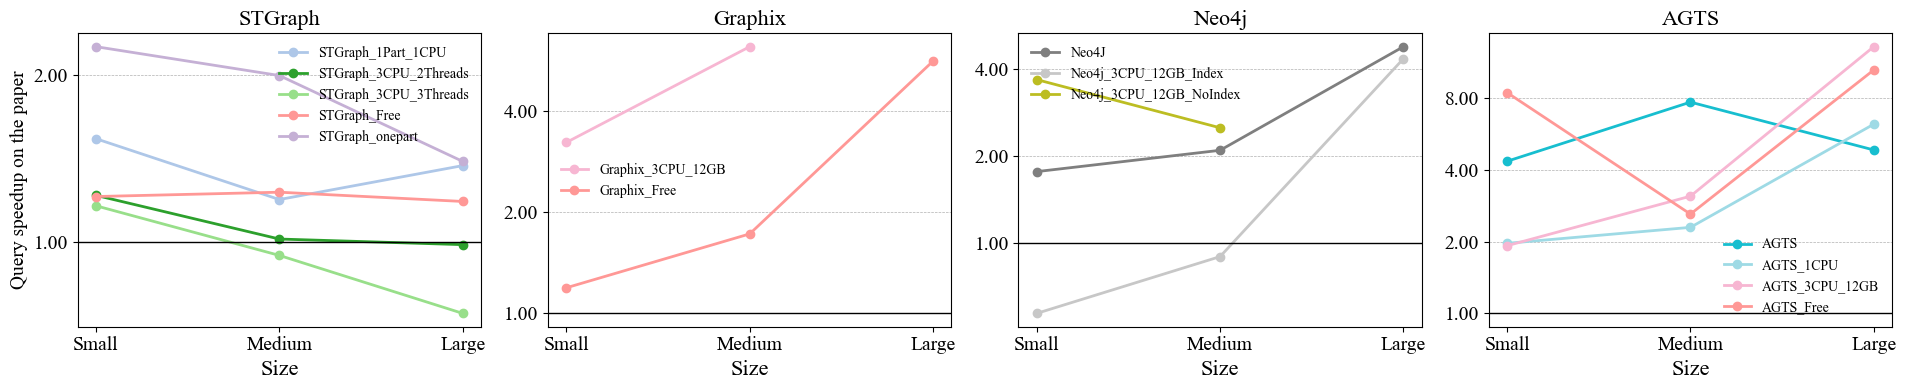

Ingestion, STGraph: nei grafici ['STGraph_1Part_1CPU', 'STGraph_Free', 'STGraph_onepart']; nascoste ['STGraph_1CPU_NoConf', 'STGraph_2CPU_NoConf', 'STGraph_2Part', 'STGraph_4CPU_NoConf', 'STGraph_opt']
Ingestion, Graphix: nei grafici ['Graphix_1Part_No_index', 'Graphix_Free']; nascoste ['Graphix', 'Graphix_1CPU_NoConf', 'Graphix_2CPU_NoConf', 'Graphix_2Part', 'Graphix_2Part_No_index', 'Graphix_4CPU_NoConf']
Ingestion, Neo4j: nei grafici []; nascoste []
Ingestion, AGTS: nei grafici []; nascoste []


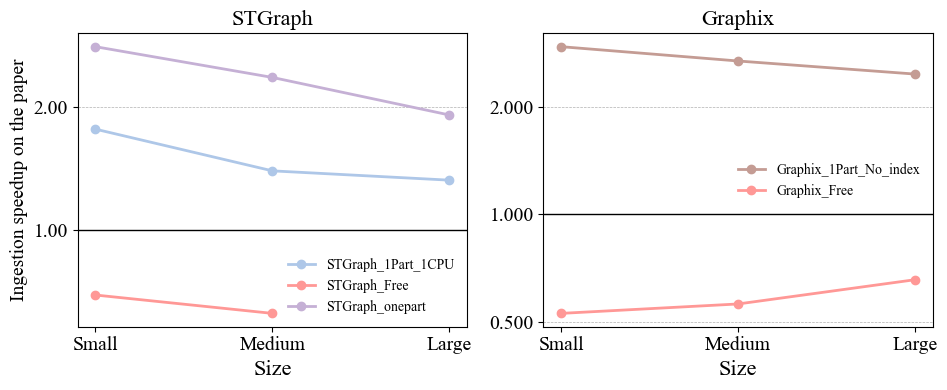

In [735]:
def trimmed_mean(s):
    # Come in speed_up: senza le due più basse e le due più alte (una sola se sono al più quattro)
    s = s.dropna().sort_values()
    if len(s) <= 2:
        return s.mean()
    boundary = 2 if len(s) > 4 else 1
    return s.iloc[boundary:-boundary].mean()

def speed_up_by_size(df, group_cols, baseline="STGraph", agg="mean"):
    """Gli speedup di speed_up come DataFrame: una riga per dimensione, una colonna per variante; agg: la media delle
    iterazioni (come speed_up) o la mediana"""
    avg = df.groupby(group_cols + ["model"], observed=True)["elapsedTime"].agg(agg).unstack("model")
    ratio = avg.drop(columns=baseline).div(avg[baseline], axis=0)
    result = ratio.groupby(level="datasetSize", observed=True).agg(trimmed_mean)
    result.index = result.index.astype(str)
    return result.reindex(dataset_order)

def configuration(model):
    """La configurazione del cluster di una variante, senza il sistema (Graphix è quella di STGraph_onepart)"""
    return model.split("_", 1)[1] if "_" in model else ("onepart" if model == "Graphix" else model)

# Stesso colore per la stessa configurazione nei sistemi (20 colori: le configurazioni sono più di 10)
configuration_palette = plt.get_cmap("tab20").colors
configuration_names = list(dict.fromkeys(configuration(m) for m in configurations))
configuration_colors = {m: configuration_palette[configuration_names.index(configuration(m)) % len(configuration_palette)]
                        for m in configurations}

query_speedup = speed_up_by_size(configurations_query_df, ["datasetSize", "queryid"])
ingestion_speedup = speed_up_by_size(configurations_ingestion_df, ["datasetSize"])
display(query_speedup.drop(columns=hidden_configurations, errors="ignore").T.round(2))
display(ingestion_speedup.drop(columns=hidden_configurations, errors="ignore").T.round(2))

for name, speedup in [("Query", query_speedup), ("Ingestion", ingestion_speedup)]:
    # Un pannello per sistema con almeno una variante da graficare (Neo4j e AGTS: solo query)
    panels = []
    for system, models in [("STGraph", stgraph_configurations), ("Graphix", graphix_configurations), ("Neo4j", neo4j_configurations), ("AGTS", agts_configurations)]:
        present = [m for m in models if m in speedup.columns and speedup[m].notna().any()]
        shown = [m for m in present if m not in hidden_configurations]
        print(f"{name}, {system}: nei grafici {shown}; nascoste {[m for m in present if m in hidden_configurations]}")
        if shown:
            panels.append((system, shown))
    fig, axes = plt.subplots(1, len(panels), figsize=(fig_x * 1.6 * len(panels), fig_y * 1.6), squeeze=False)
    for ax, (system, shown) in zip(axes[0], panels):
        for model in shown:
            ax.plot(dataset_order, speedup[model].values, marker="o", linewidth=2, color=configuration_colors[model], label=model)
        ax.axhline(1, color="black", linewidth=1)  # STGraph del paper
        ax.set_yscale("log", base=2)
        ax.yaxis.set_major_formatter(mticker.ScalarFormatter())
        ax.set_title(system, fontsize=font)
        ax.set_xlabel("Size", fontsize=font)
        ax.tick_params(labelsize=font - 2)
        ax.yaxis.grid(True, linestyle="--", linewidth=0.5, which="major")
        ax.legend(fontsize=font - 6, frameon=False)
    axes[0][0].set_ylabel(f"{name} speedup on the paper", fontsize=font - 2)
    plt.tight_layout()
    plt.show()

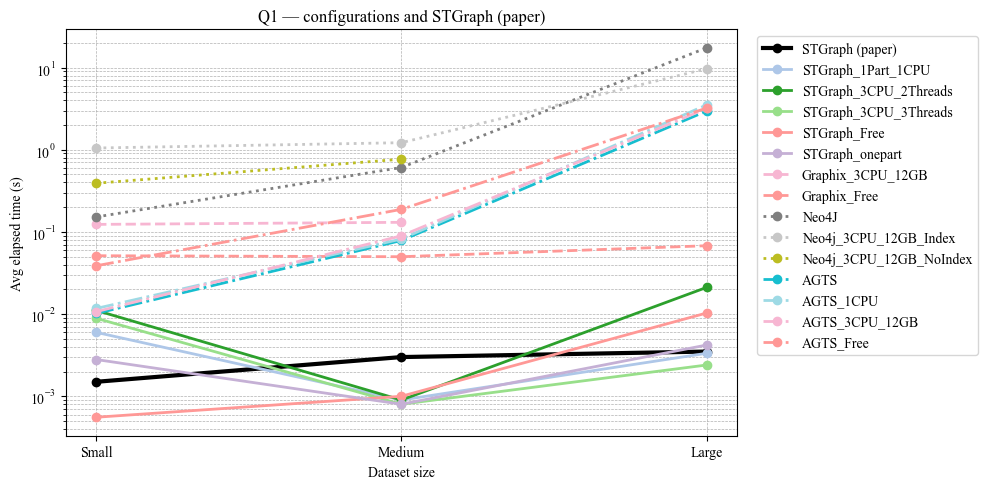

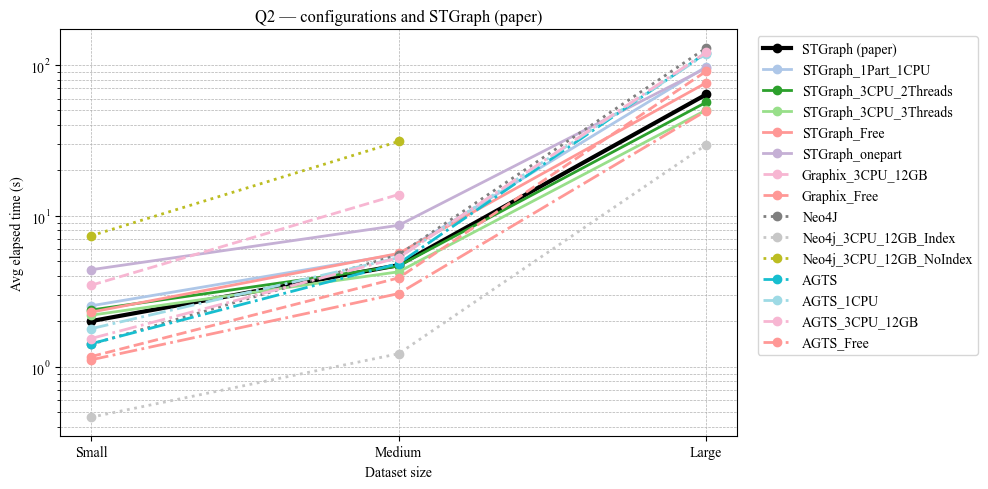

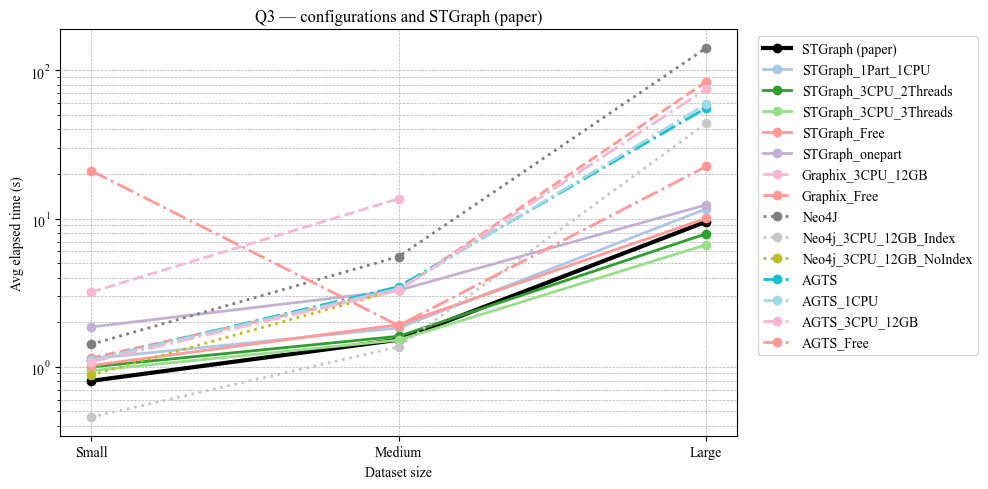

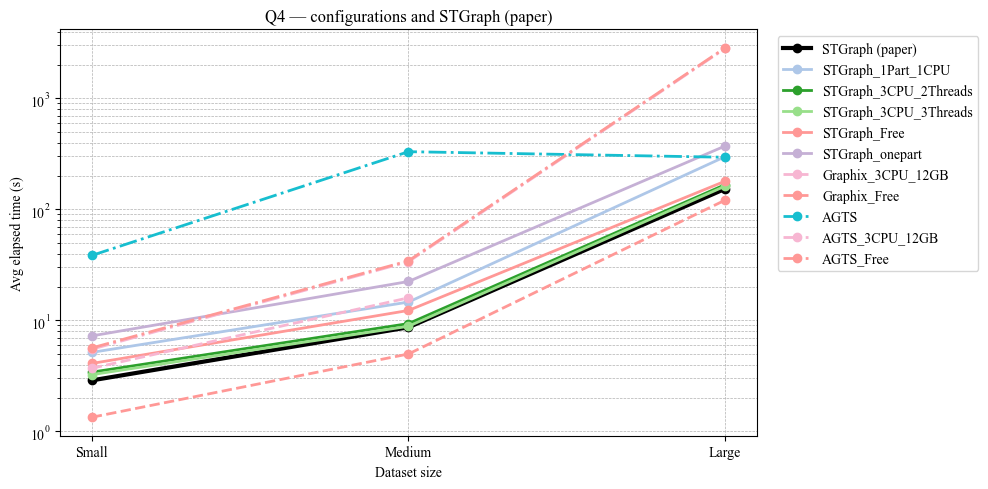

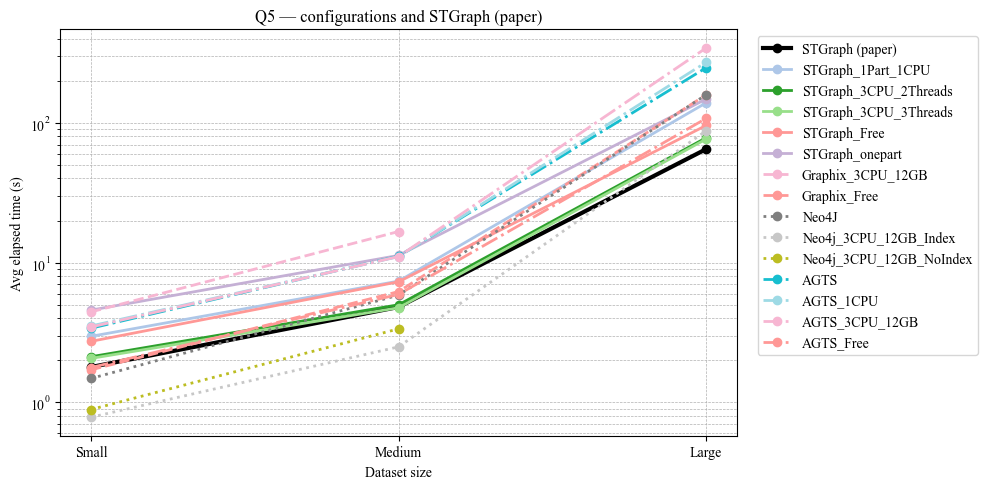

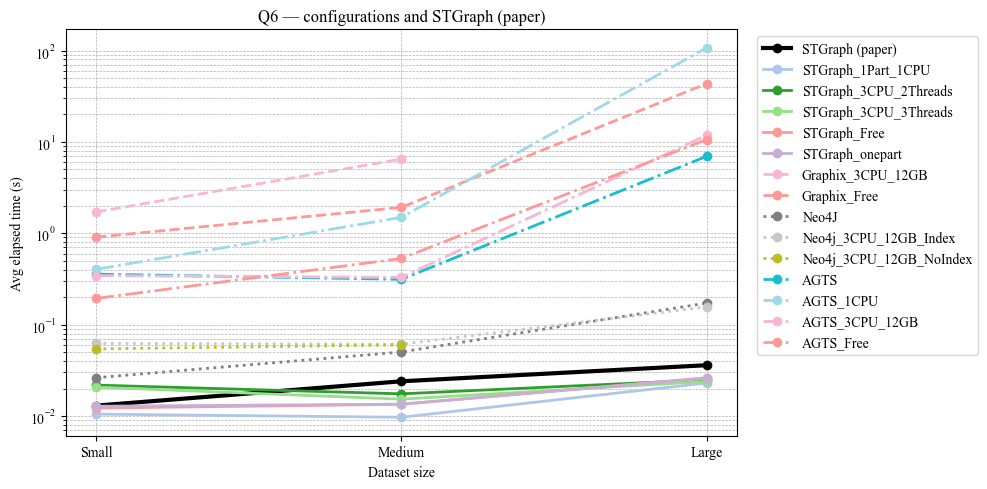

In [736]:
# Come i line chart delle versioni sopra: per ogni query il tempo medio per dimensione, con le configurazioni non
# nascoste (hidden_configurations) e STGraph del paper (nero). Stesso colore per la stessa configurazione: linea
# continua STGraph, tratteggiata Graphix, punteggiata Neo4j, tratto-punto AGTS
shown_configurations = [m for m in configurations if m in query_speedup.columns and m not in hidden_configurations]
avg_by_size = (
    configurations_query_df.assign(datasetSize=configurations_query_df["datasetSize"].astype(str))
    .groupby(["queryid", "datasetSize", "model"])["elapsedTime"].mean()
)
for query in sorted(configurations_query_df["queryid"].unique()):
    fig, ax = plt.subplots(figsize=(10, 5))
    for model in ["STGraph"] + shown_configurations:
        y = [avg_by_size.get((query, size, model), np.nan) for size in dataset_order]
        if np.all(np.isnan(y)):
            continue
        if model == "STGraph":
            ax.plot(dataset_order, y, marker="o", linewidth=3, color="black", label="STGraph (paper)")
        else:
            ax.plot(dataset_order, y, marker="o", linewidth=2, color=configuration_colors[model],
                    linestyle="-" if model.startswith("STGraph") else ("--" if model.startswith("Graphix")
                    else ("-." if model.startswith("AGTS") else ":")), label=model)
    ax.set_title(f"{query} — configurations and STGraph (paper)")
    ax.set_xlabel("Dataset size")
    ax.set_ylabel("Avg elapsed time (s)")
    ax.set_yscale("log")
    ax.grid(True, which="both", linestyle="--", linewidth=0.5)
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))
    plt.tight_layout()
    plt.show()

### Con la mediana delle iterazioni

Gli stessi grafici e la tabella per query con la mediana delle iterazioni al posto della media: robusta alle iterazioni lente a freddo (es. le prime di Neo4j su large). Solo query: l'ingestion ha una sola iterazione per configurazione.

datasetSize,Small,Medium,Large
model,,,
AGTS,4.11,7.32,4.84
AGTS_1CPU,1.95,2.29,6.20
AGTS_3CPU_12GB,1.90,3.09,12.44
AGTS_Free,8.36,2.60,10.50
Graphix_3CPU_12GB,3.19,6.19,NaN
Graphix_Free,1.18,1.71,5.65
Neo4J,1.71,2.09,4.66
Neo4j_3CPU_12GB_Index,0.51,0.86,4.48
Neo4j_3CPU_12GB_NoIndex,1.01,2.14,NaN


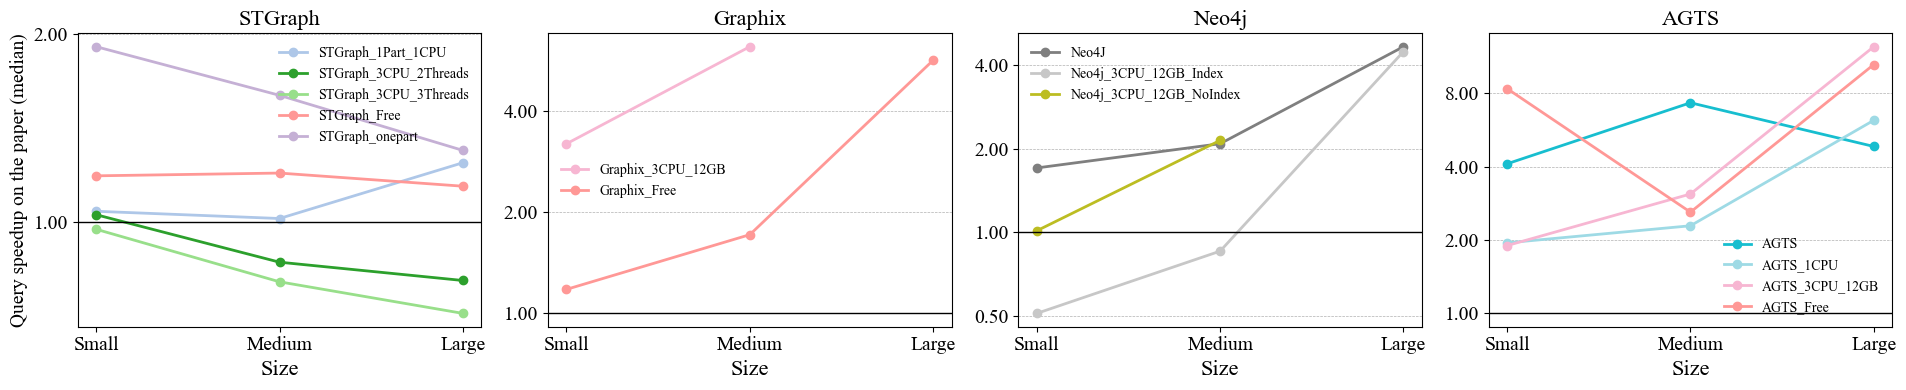

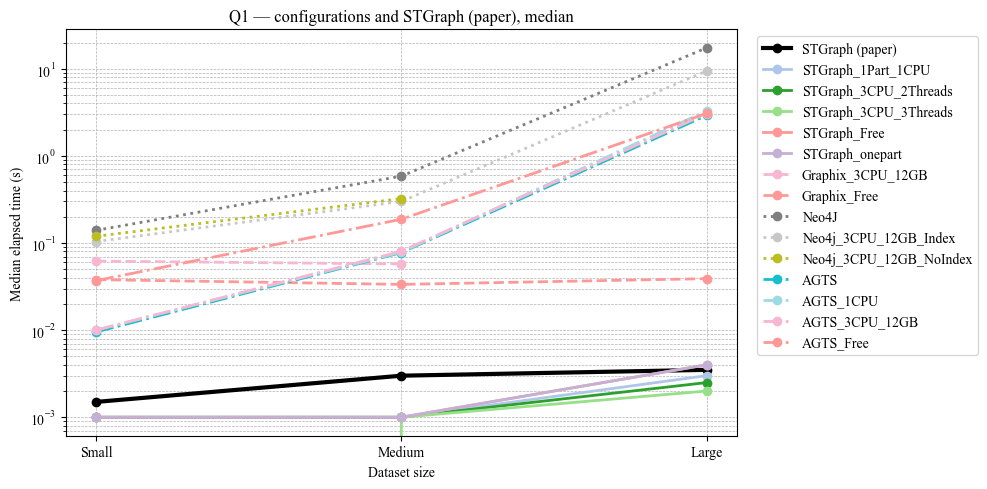

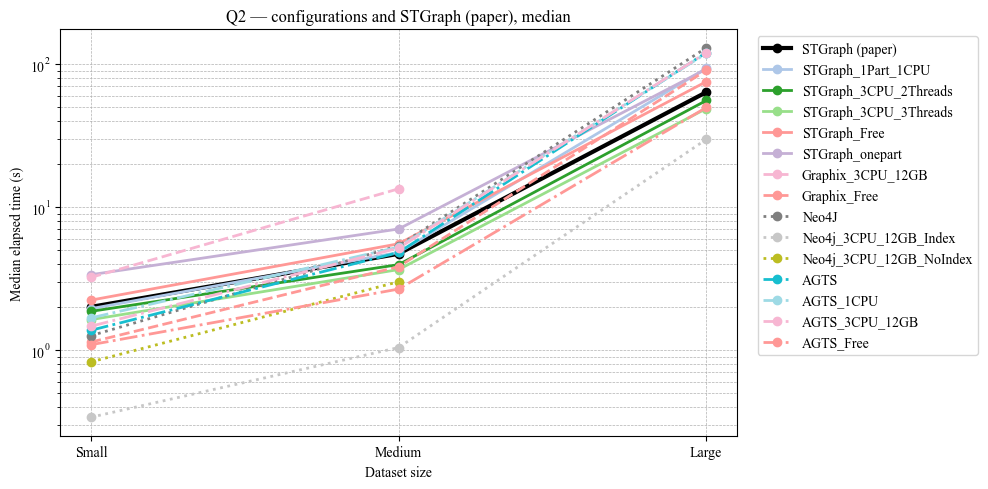

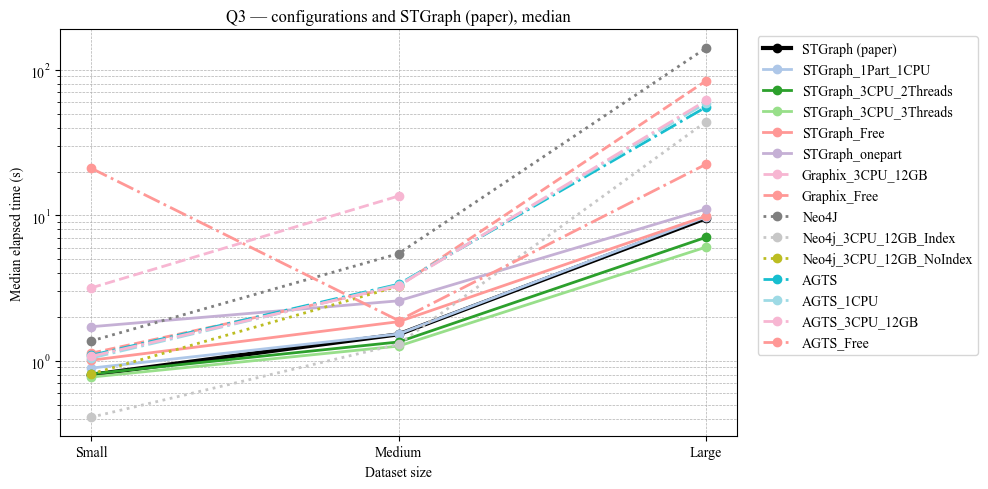

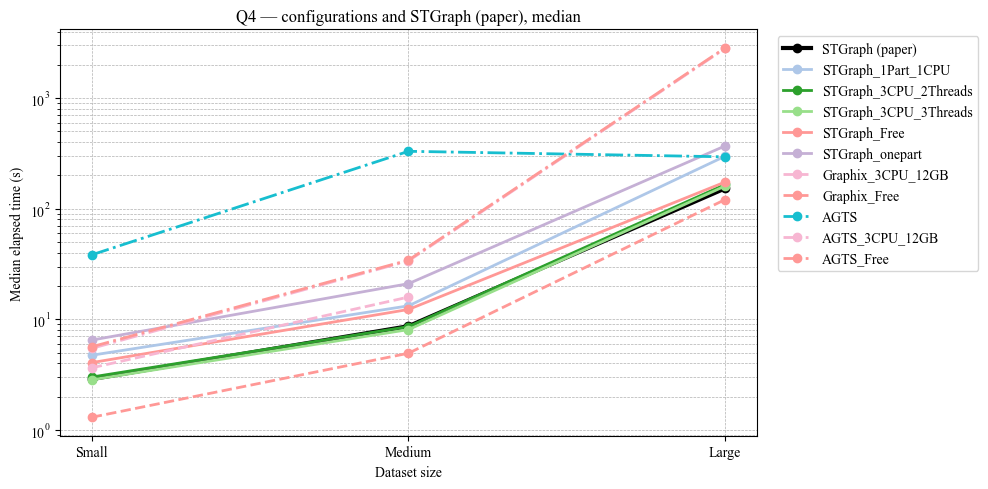

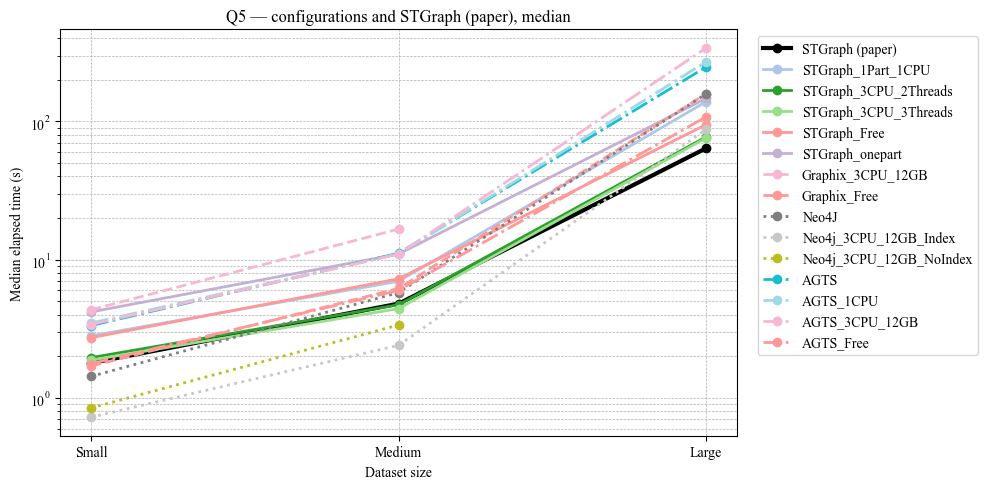

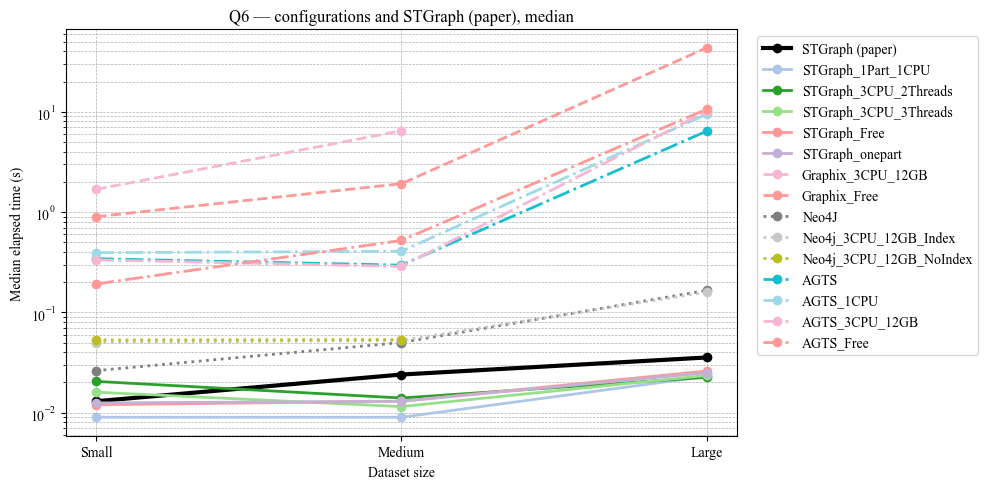

datasetSize              Small                                    Medium  \
queryid                     Q1    Q2     Q3     Q4    Q5      Q6      Q1   
model                                                                      
AGTS                      6.36  0.69   1.36  13.30  1.87   26.38   25.90   
AGTS_1CPU                 6.67  0.84   1.30    NaN  1.95   30.27   26.17   
AGTS_3CPU_12GB            6.67  0.73   1.34   1.90  1.90   25.69   26.83   
AGTS_Free                24.67  0.54  26.33   1.96  0.99   14.77   62.50   
Graphix_3CPU_12GB        41.33  1.61   3.95   1.26  2.43  129.58   19.17   
Graphix_Free             25.33  0.57   1.41   0.45  0.95   69.23   11.17   
Neo4J                    93.21  0.63   1.71    NaN  0.80    2.02  195.19   
Neo4j_3CPU_12GB_Index    69.33  0.17   0.51    NaN  0.41    3.85  100.00   
Neo4j_3CPU_12GB_NoIndex  79.67  0.41   1.01    NaN  0.47    4.08  107.83   
STGraph_1Part_1CPU        0.67  0.97   1.11   1.64  1.57    0.69    0.33   
STGraph_3CPU_2Threads     0.67  0.93   1.01   1.04  1.09    1.58    0.33   
STGraph_3CPU_3Threads     0.00  0.81   0.96   0.99  1.05    1.23    0.33   
STGraph_Free              0.67  1.12   1.26   1.41  1.53    0.92    0.33   
STGraph_onepart           0.67  1.68   2.14   2.25  2.34    0.96    0.33   

datasetSize                                                 Large        \
queryid                    Q2    Q3     Q4    Q5      Q6       Q1    Q2   
model                                                                     
AGTS                     1.02  2.21  38.18  2.32   12.32   833.68  1.89   
AGTS_1CPU                1.12  2.18    NaN  2.29   16.94   939.43  1.87   
AGTS_3CPU_12GB           1.10  2.16   3.90  2.28   11.96   872.00  1.89   
AGTS_Free                0.57  1.24   3.96  1.25   21.71   878.29  0.78   
Graphix_3CPU_12GB        2.85  8.92   1.83  3.47  269.42      NaN   NaN   
Graphix_Free             0.81  2.14   0.57  1.29   79.90    11.14  1.42   
Neo4J                    1.14  3.59    NaN  1.20    2.09  4968.46  2.04   
Neo4j_3CPU_12GB_Index    0.22  0.86    NaN  0.50    2.19  2700.00  0.47   
Neo4j_3CPU_12GB_NoIndex  0.64  2.14    NaN  0.70    2.23      NaN   NaN   
STGraph_1Part_1CPU       1.02  1.01   1.53  1.45    0.37     0.86  1.47   
STGraph_3CPU_2Threads    0.84  0.89   0.99  0.98    0.58     0.71  0.87   
STGraph_3CPU_3Threads    0.78  0.83   0.93  0.92    0.48     0.57  0.77   
STGraph_Free             1.18  1.22   1.42  1.51    0.54     1.14  1.19   
STGraph_onepart          1.49  1.70   2.42  2.28    0.54     1.14  1.45   

datasetSize                                           
queryid                     Q3     Q4    Q5       Q6  
model                                                 
AGTS                      5.81   1.93  3.87   180.45  
AGTS_1CPU                 6.20    NaN  4.23   265.32  
AGTS_3CPU_12GB            6.44  18.43  5.32   283.87  
AGTS_Free                 2.35  18.66  1.69   298.52  
Graphix_3CPU_12GB          NaN    NaN   NaN      NaN  
Graphix_Free              8.81   0.79  2.48  1221.87  
Neo4J                    14.80    NaN  2.48     4.66  
Neo4j_3CPU_12GB_Index     4.62    NaN  1.37     4.48  
Neo4j_3CPU_12GB_NoIndex    NaN    NaN   NaN      NaN  
STGraph_1Part_1CPU        1.02   1.95  2.17     0.65  
STGraph_3CPU_2Threads     0.74   1.08  1.21     0.63  
STGraph_3CPU_3Threads     0.63   1.05  1.19     0.66  
STGraph_Free              1.03   1.14  1.48     0.73  
STGraph_onepart           1.16   2.42  2.29     0.70

In [737]:
query_speedup_median = speed_up_by_size(configurations_query_df, ["datasetSize", "queryid"], agg="median")
display(query_speedup_median.drop(columns=hidden_configurations, errors="ignore").T.round(2))

panels = []
for system, models in [("STGraph", stgraph_configurations), ("Graphix", graphix_configurations), ("Neo4j", neo4j_configurations), ("AGTS", agts_configurations)]:
    shown = [m for m in models if m in query_speedup_median.columns and query_speedup_median[m].notna().any() and m not in hidden_configurations]
    if shown:
        panels.append((system, shown))
fig, axes = plt.subplots(1, len(panels), figsize=(fig_x * 1.6 * len(panels), fig_y * 1.6), squeeze=False)
for ax, (system, shown) in zip(axes[0], panels):
    for model in shown:
        ax.plot(dataset_order, query_speedup_median[model].values, marker="o", linewidth=2, color=configuration_colors[model], label=model)
    ax.axhline(1, color="black", linewidth=1)  # STGraph del paper
    ax.set_yscale("log", base=2)
    ax.yaxis.set_major_formatter(mticker.ScalarFormatter())
    ax.set_title(system, fontsize=font)
    ax.set_xlabel("Size", fontsize=font)
    ax.tick_params(labelsize=font - 2)
    ax.yaxis.grid(True, linestyle="--", linewidth=0.5, which="major")
    ax.legend(fontsize=font - 6, frameon=False)
axes[0][0].set_ylabel("Query speedup on the paper (median)", fontsize=font - 2)
plt.tight_layout()
plt.show()

# Per query: il tempo mediano per dimensione, come i line chart sopra
median_by_size = (
    configurations_query_df.assign(datasetSize=configurations_query_df["datasetSize"].astype(str))
    .groupby(["queryid", "datasetSize", "model"])["elapsedTime"].median()
)
for query in sorted(configurations_query_df["queryid"].unique()):
    fig, ax = plt.subplots(figsize=(10, 5))
    for model in ["STGraph"] + shown_configurations:
        y = [median_by_size.get((query, size, model), np.nan) for size in dataset_order]
        if np.all(np.isnan(y)):
            continue
        if model == "STGraph":
            ax.plot(dataset_order, y, marker="o", linewidth=3, color="black", label="STGraph (paper)")
        else:
            ax.plot(dataset_order, y, marker="o", linewidth=2, color=configuration_colors[model],
                    linestyle="-" if model.startswith("STGraph") else ("--" if model.startswith("Graphix")
                    else ("-." if model.startswith("AGTS") else ":")), label=model)
    ax.set_title(f"{query} — configurations and STGraph (paper), median")
    ax.set_xlabel("Dataset size")
    ax.set_ylabel("Median elapsed time (s)")
    ax.set_yscale("log")
    ax.grid(True, which="both", linestyle="--", linewidth=0.5)
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))
    plt.tight_layout()
    plt.show()

# Speedup per query con la mediana: ogni variante non nascosta / STGraph del paper
median = configurations_query_df.groupby(["datasetSize", "queryid", "model"], observed=True)["elapsedTime"].median().unstack("model")
display(median.drop(columns="STGraph").div(median["STGraph"], axis=0).drop(columns=hidden_configurations, errors="ignore").T.round(2))

### Line chart per query, versione zoomata

Gli stessi line chart per query (media e mediana), più leggibili: l'asse y tagliato tra il 10° e il 90° percentile dei tempi del grafico (i punti fuori dal taglio restano segnati al bordo, con una freccia e il loro valore), colori distinti tra le sole configurazioni graficate, un tratto e un marcatore per sistema (continuo e cerchio STGraph, tratteggiato e quadrato Graphix, punteggiato e triangolo Neo4j, tratto-punto e rombo AGTS) e le linee leggermente sfalsate in orizzontale.

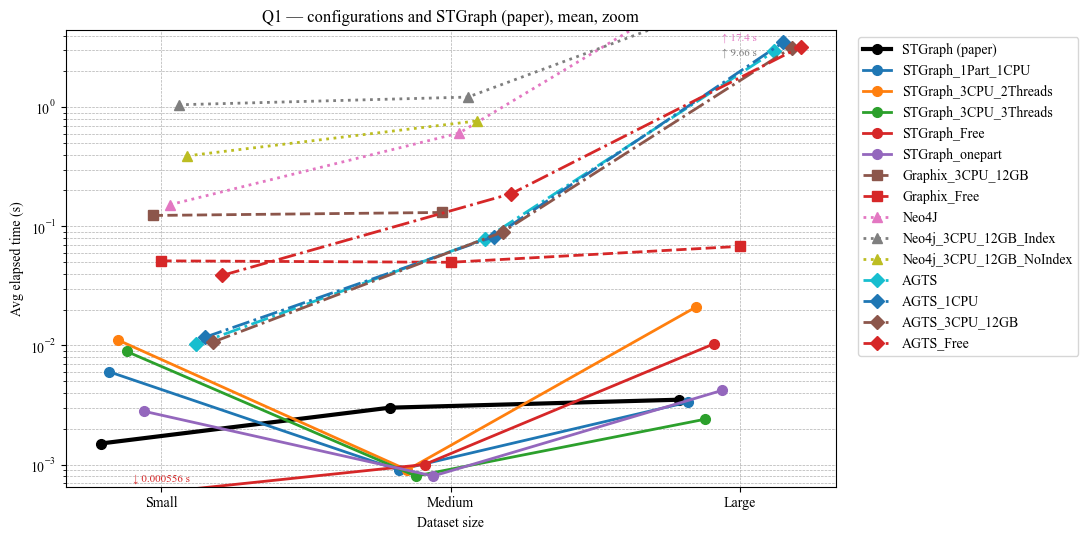

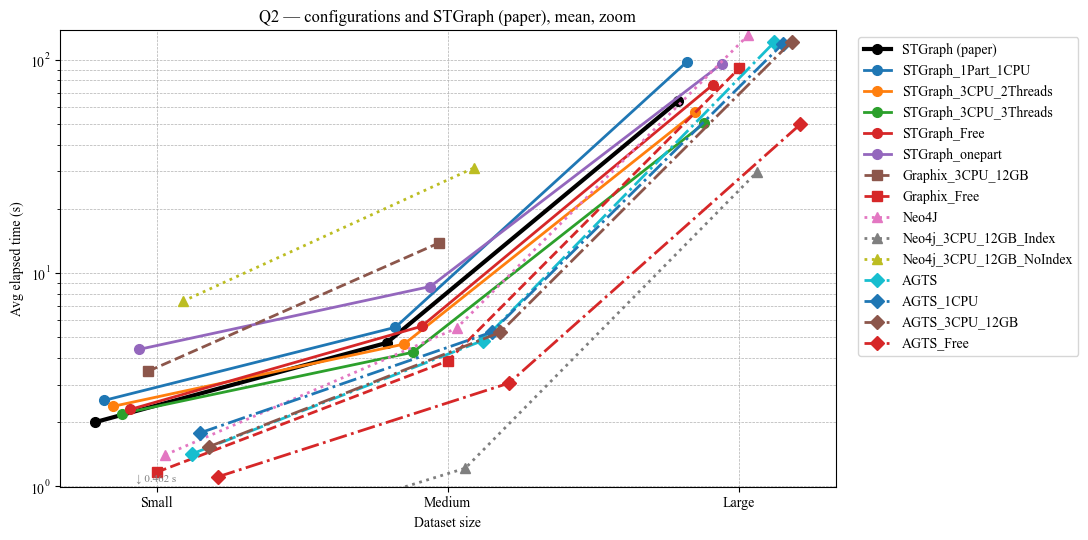

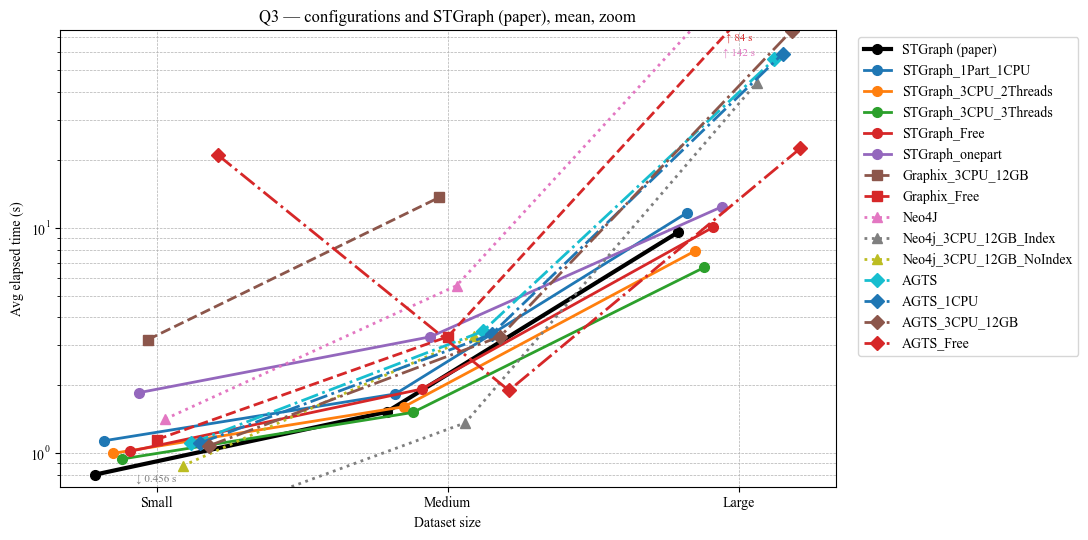

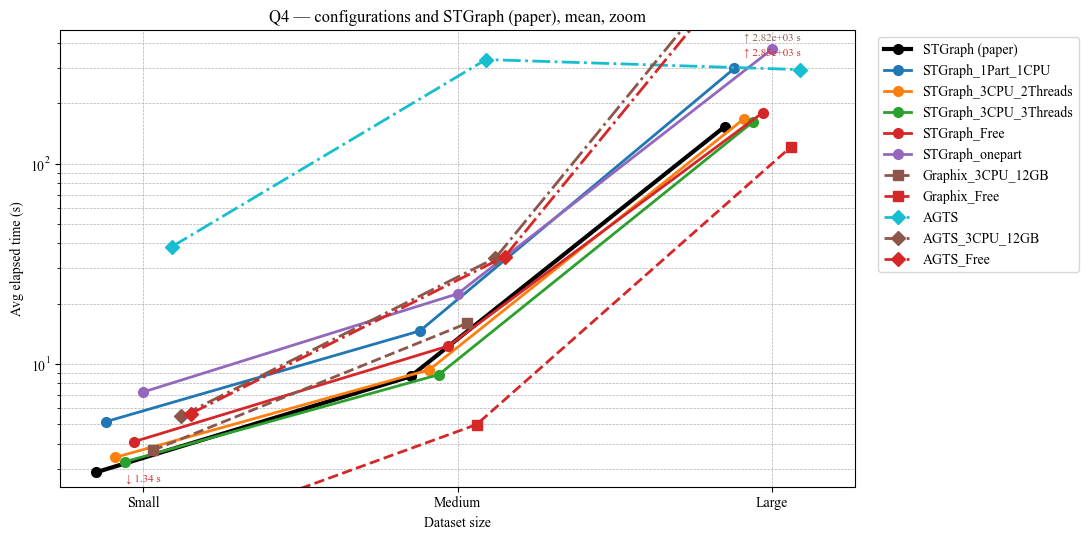

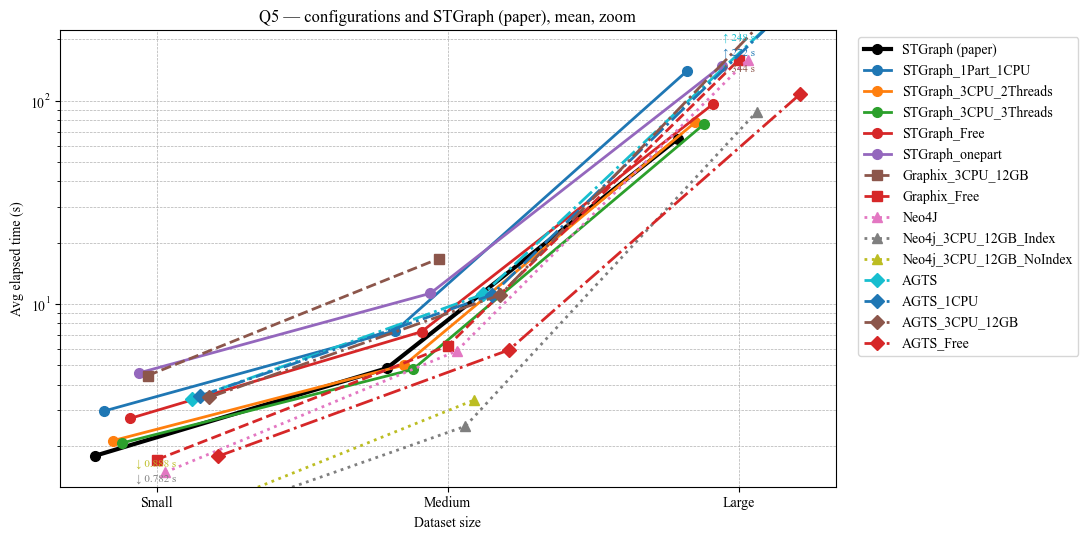

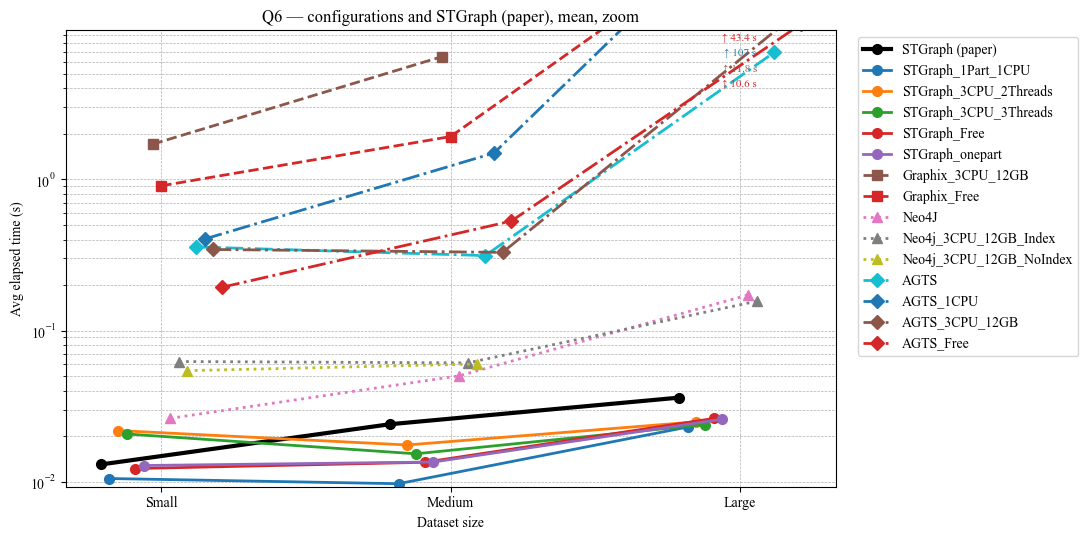

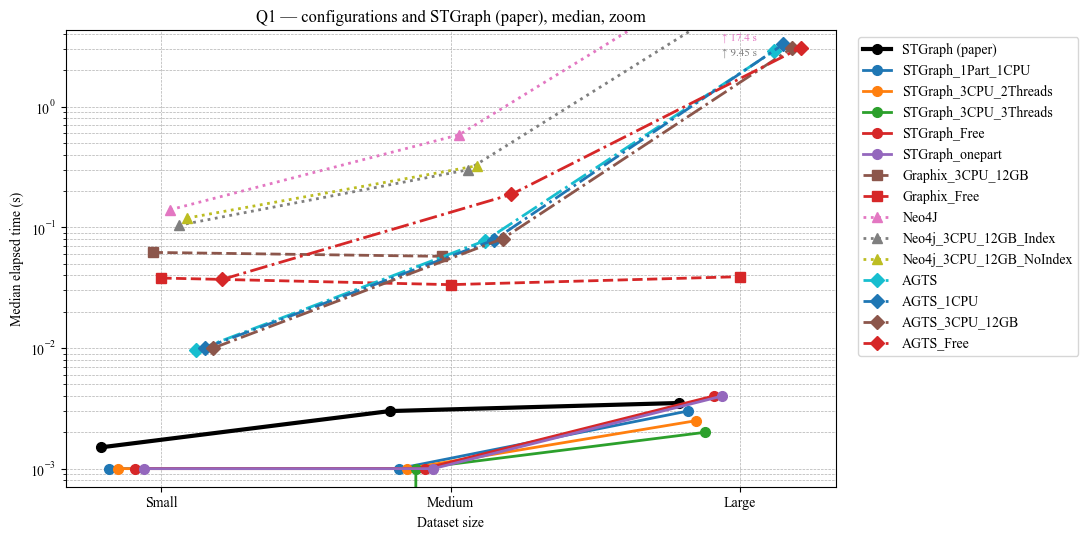

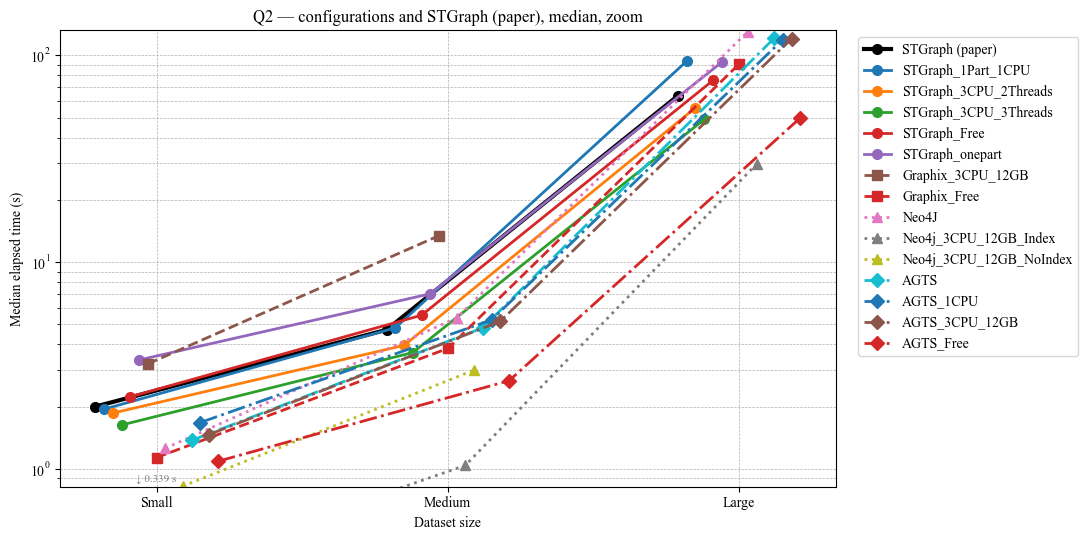

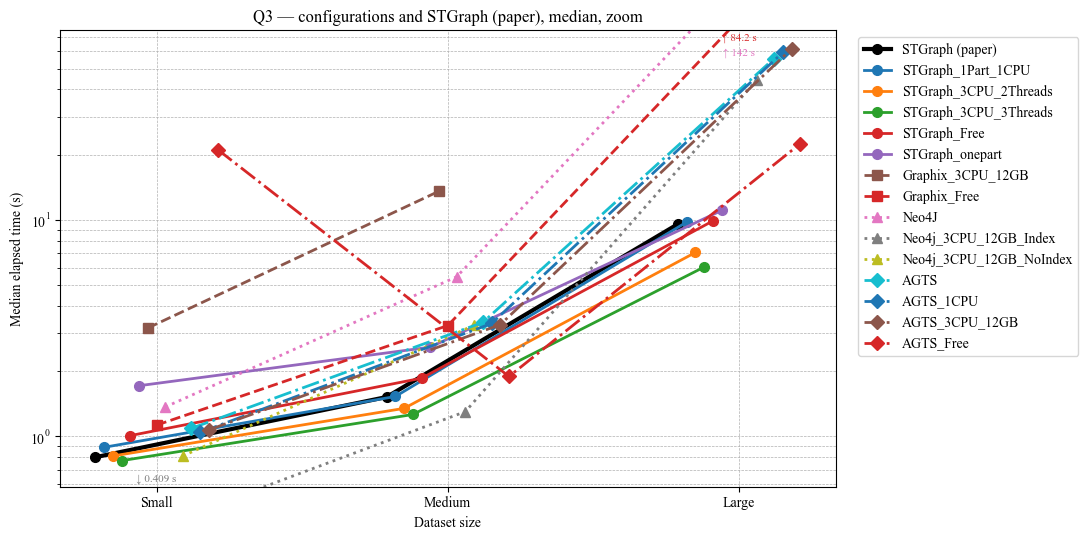

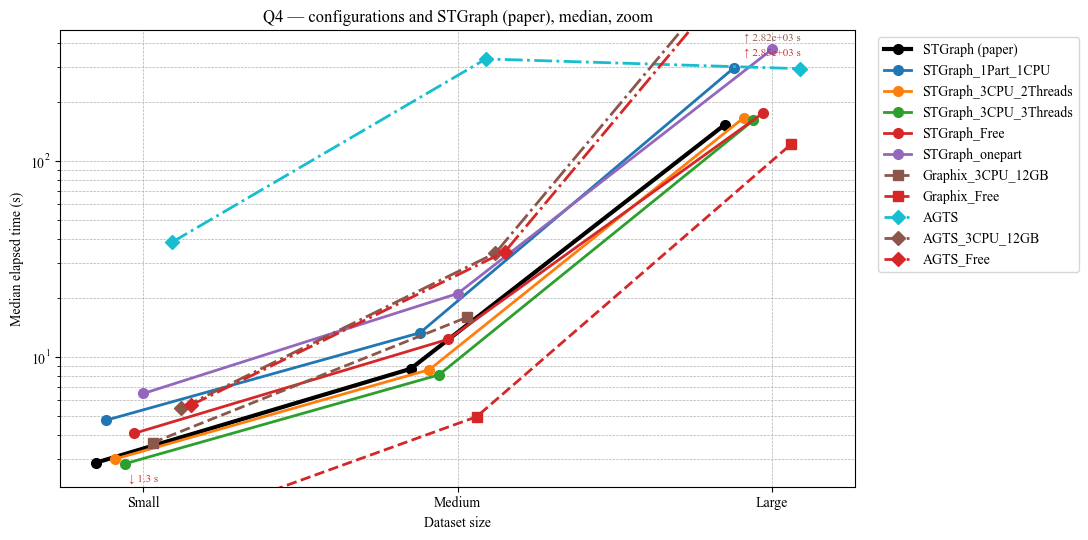

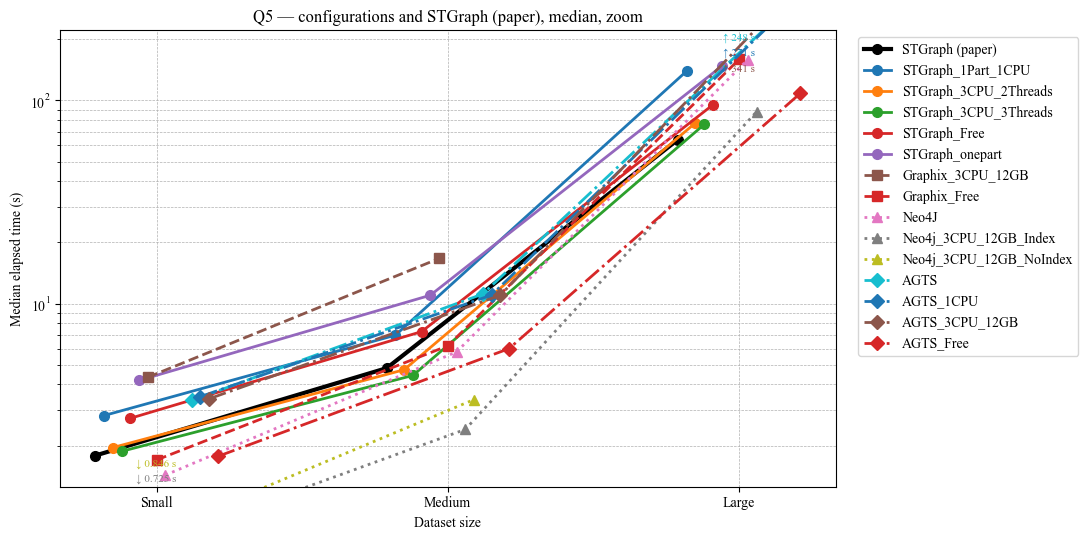

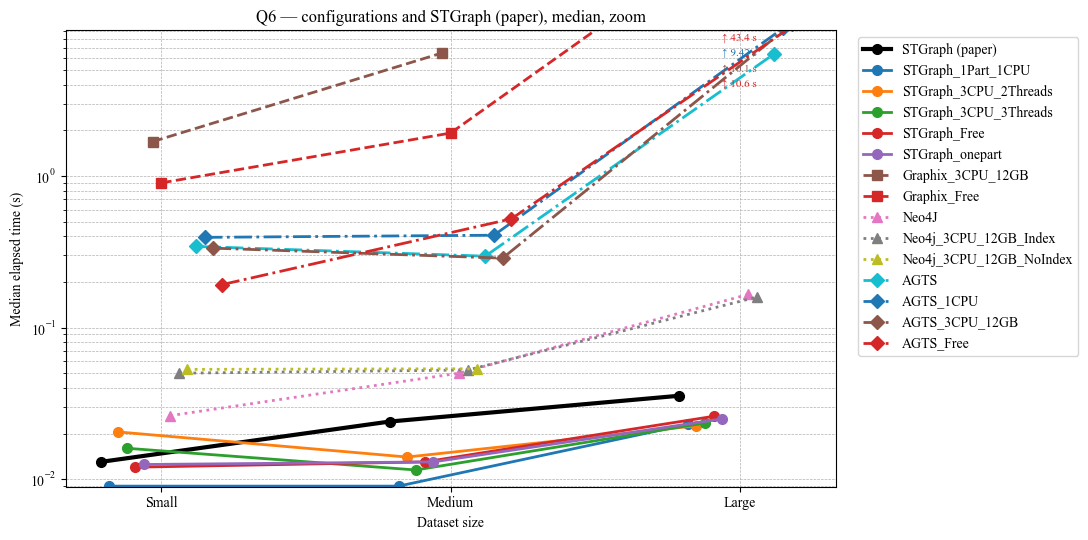

In [738]:
zoom_palette = plt.get_cmap("tab10").colors
zoom_names = list(dict.fromkeys(configuration(m) for m in shown_configurations))
zoom_colors = {m: zoom_palette[zoom_names.index(configuration(m)) % len(zoom_palette)] for m in shown_configurations}
zoom_colors["STGraph"] = "black"
zoom_styles = {"STGraph": ("-", "o"), "Graphix": ("--", "s"), "Neo4j": (":", "^"), "AGTS": ("-.", "D")}

def zoom_system(model):
    if model.startswith("AGTS"):
        return "AGTS"
    return "Graphix" if model.startswith("Graphix") else ("Neo4j" if model.lower().startswith("neo4j") else "STGraph")

def plot_query_lines_zoomed(values_by_size, what):
    """I line chart per query di values_by_size (query, dimensione, modello -> secondi), tagliati tra il 10° e il 90°
    percentile dei loro tempi"""
    x = np.arange(len(dataset_order))
    for query in sorted(configurations_query_df["queryid"].unique()):
        lines = {m: np.array([values_by_size.get((query, size, m), np.nan) for size in dataset_order]) for m in ["STGraph"] + shown_configurations}
        lines = {m: y for m, y in lines.items() if not np.all(np.isnan(y))}
        values = np.concatenate([y[~np.isnan(y)] for y in lines.values()])
        values = values[values > 0]
        low, high = np.percentile(np.log10(values), [10, 90])
        low, high = 10 ** (low - 0.15), 10 ** (high + 0.15)
        fig, ax = plt.subplots(figsize=(11, 5.5))
        clipped = {}  # le etichette già al bordo, per dimensione: le successive vanno sotto (sopra) le precedenti
        for i, (model, y) in enumerate(lines.items()):
            xs = x + (i - (len(lines) - 1) / 2) * 0.03
            linestyle, marker = zoom_styles[zoom_system(model)]
            ax.plot(xs, y, marker=marker, markersize=7, linewidth=3 if model == "STGraph" else 2, color=zoom_colors[model],
                    linestyle=linestyle, label="STGraph (paper)" if model == "STGraph" else model)
            for j, (xi, yi) in enumerate(zip(xs, y)):  # i punti fuori dal taglio: al bordo, con una freccia e il valore
                if yi > high or 0 < yi < low:
                    side = "top" if yi > high else "bottom"
                    k = clipped.get((j, side), 0)
                    clipped[(j, side)] = k + 1
                    ax.annotate(f"{chr(0x2191) if side == 'top' else chr(0x2193)} {yi:.3g} s", (x[j], high if side == "top" else low),
                                xytext=(0, -11 * k - 2 if side == "top" else 11 * k + 2), textcoords="offset points",
                                fontsize=8, color=zoom_colors[model], ha="center", va=side)
        ax.set_yscale("log")
        ax.set_ylim(low, high)
        ax.set_xticks(x, dataset_order)
        ax.set_title(f"{query} — configurations and STGraph (paper), {what}, zoom")
        ax.set_xlabel("Dataset size")
        ax.set_ylabel(f"{'Avg' if what == 'mean' else 'Median'} elapsed time (s)")
        ax.grid(True, which="both", linestyle="--", linewidth=0.5)
        ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))
        plt.tight_layout()
        plt.show()

plot_query_lines_zoomed(avg_by_size, "mean")
plot_query_lines_zoomed(median_by_size, "median")

In [739]:
# Speedup per query: ogni variante non nascosta, Graphix e Neo4j compresi, / STGraph del paper
avg = configurations_query_df.groupby(["datasetSize", "queryid", "model"], observed=True)["elapsedTime"].mean().unstack("model")
display(avg.drop(columns="STGraph").div(avg["STGraph"], axis=0).drop(columns=hidden_configurations, errors="ignore").T.round(2))

datasetSize               Small                                    Medium  \
queryid                      Q1    Q2     Q3     Q4    Q5      Q6      Q1   
model                                                                       
AGTS                       6.79  0.71   1.38  13.35  1.90   27.49   26.22   
AGTS_1CPU                  7.80  0.89   1.38    NaN  1.97   31.03   27.30   
AGTS_3CPU_12GB             7.13  0.77   1.34   1.91  1.93   26.45   29.87   
AGTS_Free                 25.80  0.55  26.27   1.96  0.99   14.88   62.70   
Graphix_3CPU_12GB         82.27  1.73   3.97   1.29  2.48  131.58   43.60   
Graphix_Free              34.20  0.58   1.43   0.47  0.95   69.79   16.63   
Neo4J                    101.31  0.70   1.76    NaN  0.83    2.02  202.52   
Neo4j_3CPU_12GB_Index    699.40  0.23   0.57    NaN  0.44    4.80  405.83   
Neo4j_3CPU_12GB_NoIndex  260.60  3.68   1.09    NaN  0.50    4.18  255.73   
STGraph_1Part_1CPU         4.00  1.26   1.41   1.79  1.66    0.81    0.30   
STGraph_3CPU_2Threads      7.40  1.18   1.24   1.19  1.19    1.68    0.30   
STGraph_3CPU_3Threads      5.93  1.09   1.17   1.13  1.15    1.59    0.27   
STGraph_Free               0.37  1.15   1.27   1.42  1.53    0.94    0.33   
STGraph_onepart            1.87  2.19   2.31   2.52  2.56    0.98    0.27   

datasetSize                                                 Large        \
queryid                    Q2    Q3     Q4    Q5      Q6       Q1    Q2   
model                                                                     
AGTS                     1.03  2.28  38.20  2.31   13.05   843.48  1.89   
AGTS_1CPU                1.12  2.21    NaN  2.29   62.27  1002.21  1.86   
AGTS_3CPU_12GB           1.12  2.16   3.90  2.30   13.71   907.14  1.90   
AGTS_Free                0.65  1.25   3.97  1.23   22.08   916.78  0.78   
Graphix_3CPU_12GB        2.94  8.96   1.84  3.47  270.29      NaN   NaN   
Graphix_Free             0.82  2.16   0.58  1.29   80.04    19.40  1.43   
Neo4J                    1.17  3.64    NaN  1.22    2.09  4957.67  2.04   
Neo4j_3CPU_12GB_Index    0.26  0.89    NaN  0.52    2.55  2759.43  0.46   
Neo4j_3CPU_12GB_NoIndex  6.61  2.18    NaN  0.70    2.50      NaN   NaN   
STGraph_1Part_1CPU       1.18  1.20   1.69  1.53    0.40     0.95  1.53   
STGraph_3CPU_2Threads    0.99  1.05   1.08  1.04    0.73     6.03  0.89   
STGraph_3CPU_3Threads    0.90  0.99   1.02  0.99    0.64     0.69  0.79   
STGraph_Free             1.20  1.26   1.42  1.51    0.56     2.94  1.20   
STGraph_onepart          1.84  2.16   2.59  2.34    0.56     1.20  1.50   

datasetSize                                           
queryid                     Q3     Q4    Q5       Q6  
model                                                 
AGTS                      5.85   1.92  3.83   192.95  
AGTS_1CPU                 6.21    NaN  4.18  2969.11  
AGTS_3CPU_12GB            7.86  18.38  5.30   328.25  
AGTS_Free                 2.36  18.61  1.66   294.34  
Graphix_3CPU_12GB          NaN    NaN   NaN      NaN  
Graphix_Free              8.81   0.79  2.45  1205.01  
Neo4J                    14.88    NaN  2.45     4.79  
Neo4j_3CPU_12GB_Index     4.61    NaN  1.35     4.35  
Neo4j_3CPU_12GB_NoIndex    NaN    NaN   NaN      NaN  
STGraph_1Part_1CPU        1.22   1.95  2.15     0.64  
STGraph_3CPU_2Threads     0.83   1.09  1.21     0.69  
STGraph_3CPU_3Threads     0.70   1.06  1.18     0.66  
STGraph_Free              1.05   1.17  1.48     0.73  
STGraph_onepart           1.30   2.43  2.28     0.72

### Le configurazioni a 3 CPU contro le baseline Free

Un line chart per query con le sole configurazioni a 3 CPU (tranne quelle di `hidden_configurations`) e la baseline Free del loro sistema, cioè senza limiti di risorse: il tempo medio per dimensione. Colore per sistema (STGraph in nero); linea continua e marcatore pieno a 3 CPU, tratteggiata e marcatore vuoto la Free. Solo STGraph e Graphix hanno un'esecuzione Free: Neo4j e AGTS compaiono solo a 3 CPU.

In [ ]:
cpu3_order = ["STGraph", "Graphix", "Neo4j", "AGTS"]

def cpu3_system(model):
    return model.split("_", 1)[0]

cpu3_models = sorted(
    [m for m in configurations if m.endswith("_Free")]
    + [m for m in configurations if "3CPU" in m and m not in hidden_configurations],
    key=lambda m: (cpu3_order.index(cpu3_system(m)), not m.endswith("_Free"), m))
cpu3_colors = {"STGraph": "black", "Graphix": tableau10[0], "Neo4j": tableau10[2], "AGTS": tableau10[1]}
cpu3_markers = {"STGraph_3CPU_2Threads": "o", "STGraph_3CPU_3Threads": "s", "Neo4j_3CPU_12GB_Index": "^",
                "Neo4j_3CPU_12GB_NoIndex": "v", "AGTS_3CPU_12GB": "D"}

cpu3_df = configurations_query_df[configurations_query_df["model"].isin(cpu3_models)]
print("Righe per configurazione e dimensione")
display(cpu3_df.groupby(["model", "datasetSize"], observed=True).size().unstack(fill_value=0)
        .reindex(index=cpu3_models, columns=dataset_order, fill_value=0))

cpu3_avg = (cpu3_df.assign(datasetSize=cpu3_df["datasetSize"].astype(str))
            .groupby(["queryid", "datasetSize", "model"])["elapsedTime"].mean())
cpu3_queries = sorted(cpu3_df["queryid"].unique())
fig, axes = plt.subplots(2, 3, figsize=(fig_x * 5, fig_y * 3.2), squeeze=False)
for ax, query in zip(axes.flat, cpu3_queries):
    for model in cpu3_models:
        y = [cpu3_avg.get((query, size, model), np.nan) for size in dataset_order]
        if np.all(np.isnan(y)):
            continue
        is_free = model.endswith("_Free")
        color = cpu3_colors[cpu3_system(model)]
        ax.plot(dataset_order, y, marker=cpu3_markers.get(model, "o"), markersize=7, linewidth=2, color=color,
                linestyle="--" if is_free else "-", markerfacecolor="white" if is_free else color, label=model)
    ax.set_yscale("log")
    ax.set_title(query, fontsize=font)
    ax.tick_params(labelsize=font - 2)
    ax.yaxis.grid(True, linestyle="--", linewidth=0.5, which="major")
for ax in axes.flat[len(cpu3_queries):]:
    ax.axis("off")
fig.supylabel("Avg Elapsed Time (s)", fontsize=font)
handles = {label: handle for ax in axes.flat for handle, label in zip(*ax.get_legend_handles_labels())}
fig.legend(handles.values(), handles.keys(), ncol=4, **legend_settings)
plt.tight_layout()
os.makedirs(os.path.join(figures_path, "3cpu_free"), exist_ok=True)
plt.savefig(os.path.join(figures_path, "3cpu_free", "query_lines_smartbench.pdf"), bbox_inches="tight")
plt.show()

Righe per configurazione e dimensione


datasetSize,Small,Medium,Large
model,,,
STGraph_Free,54,54,60
STGraph_3CPU_2Threads,60,60,60
STGraph_3CPU_3Threads,60,60,60
Graphix_Free,60,60,60
Graphix_3CPU_12GB,60,60,0
Neo4j_3CPU_12GB_Index,50,50,50
Neo4j_3CPU_12GB_NoIndex,50,50,0
AGTS_Free,60,60,39
AGTS_3CPU_12GB,60,60,27


In [ ]:
# Controlli: cardinalità diverse da quella della maggior parte delle esecuzioni (paper compreso), ed esecuzioni
# (test_id) registrate sotto due varianti
card = (configurations_query_df.groupby(["datasetSize", "queryid", "model"], observed=True)["cardinality"]
        .agg(lambda s: "/".join(str(int(v)) for v in sorted(s.unique()))).reset_index())
card["expected"] = card.groupby(["datasetSize", "queryid"], observed=True)["cardinality"].transform(lambda s: s.mode().iloc[0])
display(card[card["cardinality"] != card["expected"]])

for name, df in [("query", query_statistics), ("ingestion", ingestion_statistics)]:
    shared = df[df["dataset"] == "smartbench"].groupby("test_id")["model"].agg(lambda s: ", ".join(sorted(set(s))))
    print(name, shared[shared.str.contains(", ")].value_counts().to_dict())

,datasetSize,queryid,model,cardinality,expected
180,Medium,Q1,STGraph,20,22
208,Medium,Q2,STGraph,90,95
260,Medium,Q4,STGraph,5,3
334,Large,Q1,Graphix_2Part,22/131,131
357,Large,Q2,Graphix_2Part,0/112,112
380,Large,Q3,Graphix_2Part,200/1000,1000
403,Large,Q4,Graphix_2Part,3/5,5
423,Large,Q5,Graphix_2Part,200/1000,1000
450,Large,Q6,Neo4J,0,1


query {'STGraph_2Part, STGraph_opt': 60}
ingestion {'AeonG, HyGraph, Neo4J': 1, 'Graphix_1Part_No_index, Graphix_2Part_No_index': 1, 'STGraph_2Part, STGraph_opt': 1}


## Confronto con i sistemi del paper: STGraph su una partizione con 1 CPU

Le tabelle del paper (tempi di query e ingestion, rapporti sugli altri sistemi), un line chart per query e il grafico dell'ingestion del paper, con STGraph su una partizione con 1 CPU come riferimento (lo STGraph del paper resta per confronto, tratteggiato nei line chart), Graphix nella stessa configurazione e gli altri sistemi (Neo4J, AGTS, AeonG, HyGraph) con i valori del paper. Solo SmartBench: le configurazioni ci sono solo lì. Le figure vanno in `figures/<configurazione>/`, quelle del paper restano come sono.

Query, righe per sistema e dimensione


datasetSize,Small,Medium,Large
model,,,
AGTS,170,170,110
AeonG,475,467,0
Graphix,60,60,120
HyGraph,65,115,0
Neo4J,160,60,80
STGraph,60,60,62
STGraph (paper),12,12,36


Ingestion, esecuzioni per sistema e dimensione


datasetSize,Small,Medium,Large
model,,,
AGTS,21,2,3
AeonG,5,5,1
Graphix,2,2,2
HyGraph,5,6,1
Neo4J,1,1,1
STGraph,1,1,2
STGraph (paper),1,1,1


\begin{tabular}{llllllllll}
\toprule
 &  & Model & AGTS & AeonG & Graphix & HyGraph & Neo4J & STGraph & STGraph (paper) \\
dataset & Size & ID &  &  &  &  &  &  &  \\
\midrule
\multirow[t]{24}{*}{smartbench} & \multirow[t]{6}{*}{--} & Q1 & -- & -- & -- & -- & -- & -- & $3.5 \cdot 10^{-3}$ \\
 &  & Q2 & -- & -- & -- & -- & -- & -- & $1.6 \cdot 10^{2}$ \\
 &  & Q3 & -- & -- & -- & -- & -- & -- & $1.3 \cdot 10^{1}$ \\
 &  & Q4 & -- & -- & -- & -- & -- & -- & $9.5 \cdot 10^{2}$ \\
 &  & Q5 & -- & -- & -- & -- & -- & -- & $1.4 \cdot 10^{2}$ \\
 &  & Q6 & -- & -- & -- & -- & -- & -- & $4.4 \cdot 10^{-2}$ \\
\cline{2-10}
 & \multirow[t]{6}{*}{S} & Q1 & $1.0 \cdot 10^{-2}$ & $1.3 \cdot 10^{-2}$ & $1.2 \cdot 10^{-1}$ & $6.3 \cdot 10^{-2}$ & $1.5 \cdot 10^{-1}$ & $2.8 \cdot 10^{-3}$ & $1.5 \cdot 10^{-3}$ \\
 &  & Q2 & $1.4 \cdot 10^{0}$ & $8.0 \cdot 10^{1}$ & $4.0 \cdot 10^{0}$ & $7.2 \cdot 10^{2}$ & $1.4 \cdot 10^{0}$ & $4.4 \cdot 10^{0}$ & $2.0 \cdot 10^{0}$ \\
 &  & Q3 & $1.1 \cdot 10^{0}$ & 

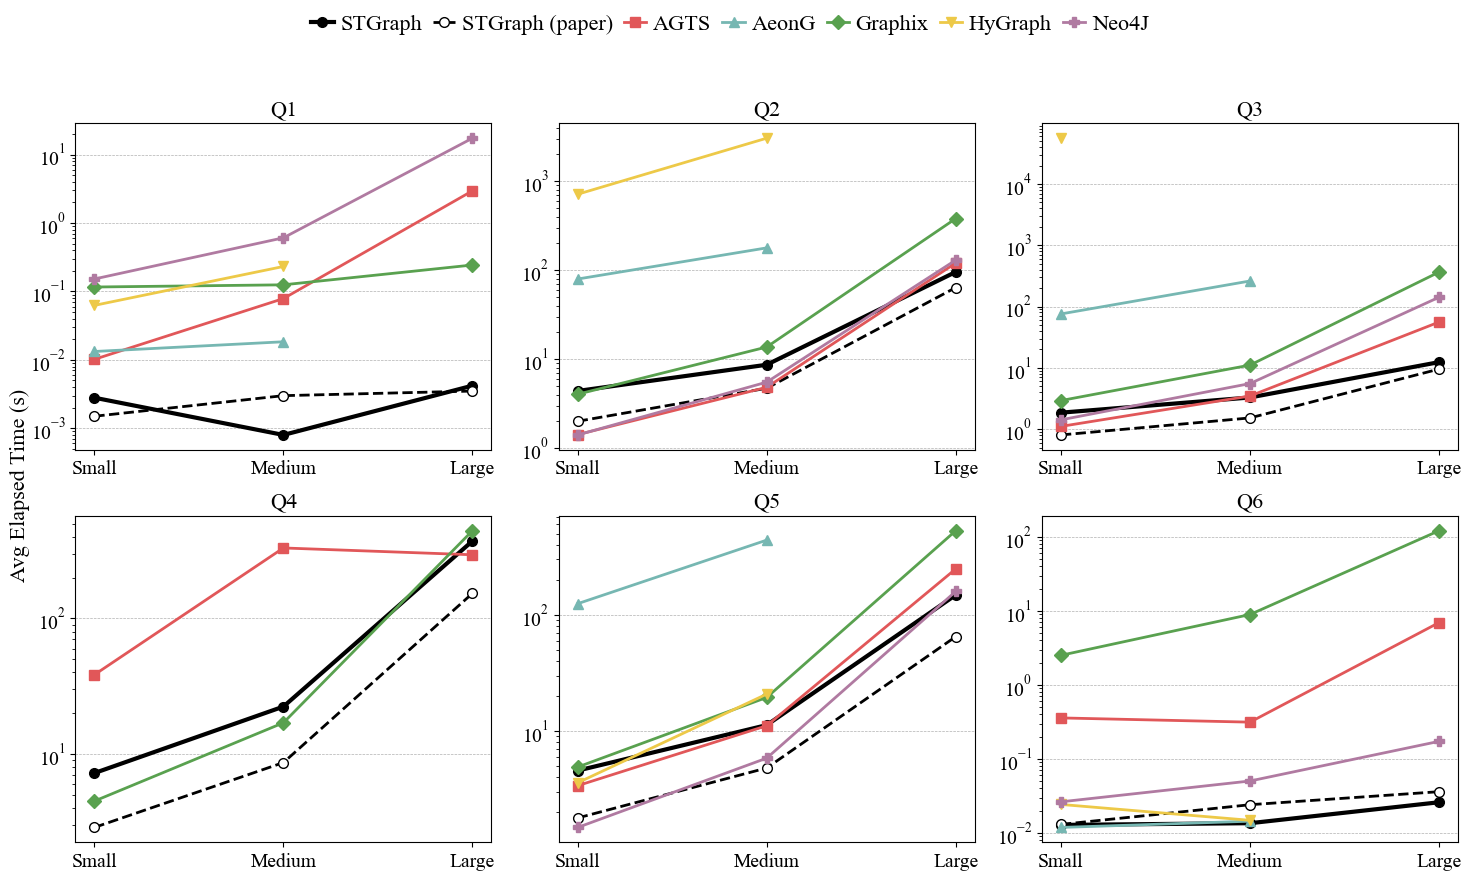

Query: tempo / STGraph, media troncata sulle query
\begin{tabular}{llrrrrrr}
\toprule
 &  & AGTS & AeonG & Graphix & HyGraph & Neo4J & STGraph (paper) \\
dataset & Size &  &  &  &  &  &  \\
\midrule
\multirow[t]{3}{*}{smartbench} & S & 2.2 & 18.1 & 1.3 & 22.3 & 0.8 & 0.4 \\
 & M & 7.9 & 23.0 & 2.6 & 145.6 & 1.7 & 0.5 \\
 & L & 3.1 & -- & 16.8 & -- & 6.7 & 0.7 \\
\cline{1-8}
\bottomrule
\end{tabular}

\begin{tabular}{lllllllll}
\toprule
 & Model & AGTS & AeonG & Graphix & HyGraph & Neo4J & STGraph & STGraph (paper) \\
dataset & Size &  &  &  &  &  &  &  \\
\midrule
\multirow[t]{3}{*}{smartbench} & S & $8.4 \cdot 10^{1}$ & $0$ & $2.9 \cdot 10^{1}$ & -- & $4.3 \cdot 10^{4}$ & $3.6 \cdot 10^{1}$ & $1.3 \cdot 10^{1}$ \\
 & M & $6.2 \cdot 10^{2}$ & $0$ & $1.1 \cdot 10^{2}$ & -- & -- & $1.3 \cdot 10^{2}$ & $5.3 \cdot 10^{1}$ \\
 & L & $1.2 \cdot 10^{5}$ & -- & $3.6 \cdot 10^{3}$ & -- & -- & $3.2 \cdot 10^{3}$ & $1.7 \cdot 10^{3}$ \\
\cline{1-9}
\bottomrule
\end{tabular}



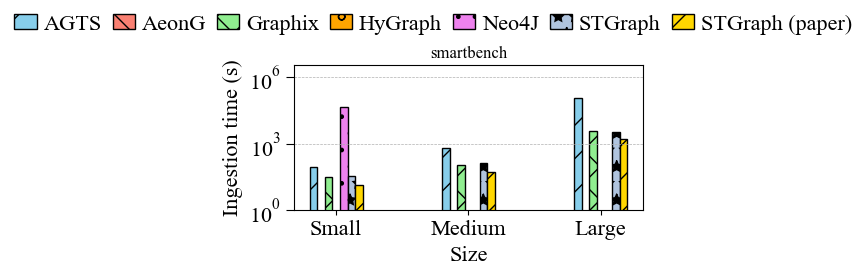

Ingestion: tempo / STGraph
\begin{tabular}{llrrrrrr}
\toprule
 &  & AGTS & AeonG & Graphix & HyGraph & Neo4J & STGraph (paper) \\
dataset & Size &  &  &  &  &  &  \\
\midrule
\multirow[t]{3}{*}{smartbench} & S & 2.4 & 0.0 & 0.8 & -0.0 & 1221.2 & 0.4 \\
 & M & 4.9 & 0.0 & 0.9 & -0.0 & -0.0 & 0.4 \\
 & L & 37.0 & -0.0 & 1.1 & -0.0 & -0.0 & 0.5 \\
\cline{1-8}
\bottomrule
\end{tabular}



In [ ]:
# STGraph su una partizione con 1 CPU e Graphix nella stessa configurazione, con la conf del repo (minimo parallelismo).
# STGraph_onepart: i run di STGraph su una partizione con 1 CPU, query e ingestion, sotto un solo nome nei file.
# Senza conf (senza limiti di parallelismo e worker) c'è solo 1 CPU, con le 2 partizioni dell'immagine e senza il
# large di STGraph: per usarla, le righe commentate
round_name = "onepart"
round_stgraph = {"query": ["STGraph_onepart"], "ingestion": ["STGraph_onepart"]}
round_graphix = {"query": ["Graphix"], "ingestion": ["Graphix"]}
# round_name = "1cpu_noconf"
# round_stgraph = {"query": ["STGraph_1CPU_NoConf"], "ingestion": ["STGraph_1CPU_NoConf"]}
# round_graphix = {"query": ["Graphix_1CPU_NoConf"], "ingestion": ["Graphix_1CPU_NoConf"]}
# Gli altri sistemi: i valori del paper
paper_systems = ["Neo4J", "AGTS", "AeonG", "HyGraph"]
# E lo STGraph del paper, per confronto
paper_stgraph = "STGraph (paper)"

def round_models(models, kind):
    """I modelli come nel confronto: STGraph e Graphix per le loro configurazioni, gli altri come sono"""
    return models.replace({**{m: "STGraph" for m in round_stgraph[kind]}, **{m: "Graphix" for m in round_graphix[kind]}})

# Query: come il grafico del paper (1 thread, 1 macchina, OPTIMIZED)
round_query_df = clean_df_stats(query_statistics.copy(deep=True), threads=1, numMachines=1, queryMode="OPTIMIZED",
                                queryid=["Q1", "Q2", "Q3", "Q4", "Q5", "Q6"], queryid_exact_match=True)
round_query_df = round_query_df[(round_query_df["dataset"] == "smartbench")
                                & round_query_df["model"].isin(round_stgraph["query"] + round_graphix["query"] + paper_systems + ["STGraph"])].copy()
round_query_df["model"] = round_models(round_query_df["model"].replace({"STGraph": paper_stgraph}), "query")

# Ingestion: le righe grezze, che print_ingestion_statistics pulisce. Gli altri sistemi e lo STGraph del paper con
# numMachines -1, come nel grafico del paper; STGraph e Graphix con numMachines -1 anche loro, perché print_ingestion_statistics tiene solo quelle
names = ingestion_statistics["model"].replace({"PGAge": "AGTS", "pgage": "AGTS", "stgraph": paper_stgraph})
round_ingestion = ingestion_statistics[
    (ingestion_statistics["dataset"] == "smartbench")
    & ((names.isin(paper_systems + [paper_stgraph]) & (ingestion_statistics["numMachines"] == -1))
       | names.isin(round_stgraph["ingestion"] + round_graphix["ingestion"]))
].copy()
round_ingestion["model"] = round_models(names[round_ingestion.index], "ingestion")
round_ingestion["numMachines"] = -1
# Le stesse esecuzioni una volta sola
round_ingestion = round_ingestion.drop_duplicates(subset=[c for c in round_ingestion.columns if c != "test_id"])

print("Query, righe per sistema e dimensione")
display(round_query_df.groupby(["model", "datasetSize"], observed=True).size().unstack(fill_value=0).reindex(columns=dataset_order, fill_value=0))
print("Ingestion, esecuzioni per sistema e dimensione")
display(round_ingestion.groupby(["model", "datasetSize"]).size().unstack(fill_value=0).reindex(columns=dataset_order, fill_value=0))

def plot_round_query_lines(df):
    """Un line chart per query: il tempo medio per dimensione di ogni sistema (STGraph in nero, quello del paper
    tratteggiato e con il marcatore vuoto)"""
    avg = df.assign(datasetSize=df["datasetSize"].astype(str)).groupby(["queryid", "datasetSize", "model"])["elapsedTime"].mean()
    systems = sorted(df["model"].unique(), key=lambda m: (m != "STGraph", m != paper_stgraph, m))
    markers = dict(zip(systems, ["o", "o", "s", "^", "D", "v", "P", "X"]))
    line_colors = {m: "black" if m in ("STGraph", paper_stgraph) else tableau10[i % len(tableau10)] for i, m in enumerate(systems)}
    queries = sorted(df["queryid"].unique())
    fig, axes = plt.subplots(2, 3, figsize=(fig_x * 5, fig_y * 3.2), squeeze=False)
    for ax, query in zip(axes.flat, queries):
        for model in systems:
            y = [avg.get((query, size, model), np.nan) for size in dataset_order]
            if np.all(np.isnan(y)):
                continue
            ax.plot(dataset_order, y, marker=markers[model], markersize=7, linewidth=3 if model == "STGraph" else 2,
                    color=line_colors[model], linestyle="--" if model == paper_stgraph else "-",
                    markerfacecolor="white" if model == paper_stgraph else line_colors[model], label=model)
        ax.set_yscale("log")
        ax.set_title(query, fontsize=font)
        ax.tick_params(labelsize=font - 2)
        ax.yaxis.grid(True, linestyle="--", linewidth=0.5, which="major")
    for ax in axes.flat[len(queries):]:
        ax.axis("off")
    fig.supylabel("Avg Elapsed Time (s)", fontsize=font)
    handles = {label: handle for ax in axes.flat for handle, label in zip(*ax.get_legend_handles_labels())}
    fig.legend(handles.values(), handles.keys(), ncol=len(handles), **legend_settings)
    plt.tight_layout()
    plt.savefig(os.path.join(figures_path, "query_lines_smartbench.pdf"), bbox_inches="tight")
    plt.show()

# Le figure in figures/<round_name>: le funzioni del paper salvano in figures_path
paper_figures_path = figures_path
figures_path = os.path.join(paper_figures_path, round_name)
os.makedirs(figures_path, exist_ok=True)
try:
    # I tempi delle query, come la tabella del grafico del paper, e un line chart per query
    print_latex(round_query_df.dropna(subset=["elapsedTime"]).groupby(["dataset", "datasetSize", "queryid", "model"], observed=True)["elapsedTime"].mean().reset_index(),
                pivot=["dataset", "Size", "ID"])
    plot_round_query_lines(round_query_df)
    print("Query: tempo / STGraph, media troncata sulle query")
    speed_up(round_query_df, denominator=True)
    print_ingestion_statistics(round_ingestion)
    print("Ingestion: tempo / STGraph")
    speed_up(clean_df(round_ingestion.copy(deep=True), threads=1), group_cols=["dataset", "datasetSize"], column="model", baseline="STGraph", denominator=True)
finally:
    figures_path = paper_figures_path

## Gruppi del rebuttal

Le query di SmartBench come nel paper (OPTIMIZED, una macchina, Q1-Q6, selettività increased; senza Q4 per Neo4j, AeonG e HyGraph, come nel paper), con la **mediana** delle iterazioni: un line chart per query (tempo mediano per dimensione, scala logaritmica) e la tabella dei rapporti sulla baseline (mediana / mediana della baseline, per query, e la loro mediana per dimensione; sopra 1 più lento della baseline). STGraph in nero, un colore per sistema, un tratto e un marcatore per variante; sopra ogni grafico le righe per configurazione e dimensione. Su Large (ed Extralarge, dove c'è), a destra di ogni linea, quante volte è più lenta della baseline (es. x4.5; sotto 1 più veloce). Le figure vanno in `figures/<archivio>/<gruppo>/`.

**Per cambiare un gruppo**: nella sua cella, un nome per riga in `models` (togli una variante commentando la riga, aggiungine una con il suo nome dalla tabella *Varianti disponibili*); `threads` per una variante con più di un thread. Per un gruppo nuovo, una cella con `plot_group("<nome>", models=[...])`. Una variante senza righe (nome sbagliato o thread diversi) viene segnalata sopra il grafico.

In [ ]:
group_system_colors = {"STGraph": "black", "Graphix": tableau10[0], "Neo4j": tableau10[2], "AGTS": tableau10[1],
                       "AeonG": tableau10[4], "HyGraph": tableau10[6]}
group_variant_styles = [("-", "o"), ("--", "s"), (":", "^"), ("-.", "D")]

# Le dimensioni dei line chart: quelle del paper più Extralarge, dove una configurazione l'ha
group_dataset_order = dataset_order + ["Extralarge"]

def group_system(model):
    return "Neo4j" if model.lower().startswith("neo4j") else model.split("_", 1)[0]

def group_query_df(models, threads=None, rename=None):
    """Le query di SmartBench di models (i nomi dopo clean_df_stats), come nel paper; threads: i thread di un modello
    (default 1); rename: i nomi di una stessa configurazione"""
    df = query_statistics.copy(deep=True)
    df = clean_df_stats(df, numMachines=1, queryMode="OPTIMIZED", queryid=["Q1", "Q2", "Q3", "Q4", "Q5", "Q6"], queryid_exact_match=True)
    df["model"] = df["model"].replace(rename or {})
    df = df[(df["dataset"] == "smartbench") & df["model"].isin(models) & df["datasetSize"].isin(group_dataset_order)].copy()
    df = df[df["threads"] == df["model"].map(lambda m: (threads or {}).get(m, 1))]
    # Come nel paper, senza EnvironmentOutlier (Q4) di Neo4j (le sue varianti comprese): la sua query ha un'altra soglia
    return df[~((df["model"].map(group_system) == "Neo4j") & (df["queryid"] == "Q4"))]

def label_large_ratios(ax, median, query, models, baseline, size="Large"):
    """Su size (Large, Extralarge), a destra di ogni linea (non della baseline), quante volte è più lenta della baseline
    (es. x4.5; sotto 1 più veloce): un'etichetta del colore della linea, distanziate in verticale perché non si
    sovrappongano"""
    large = group_dataset_order.index(size)
    base = median.get((query, size, baseline), np.nan)
    if not base > 0:
        return
    labels = []
    for model in models:
        value = median.get((query, size, model), np.nan)
        if model != baseline and value > 0:
            ratio = value / base
            labels.append([np.log10(value), f"x{ratio:.0f}" if ratio >= 10 else f"x{ratio:.1f}", group_system_colors.get(group_system(model), "gray")])
    if not labels:
        return
    low, high = np.log10(ax.get_ylim())
    gap = 0.07 * (high - low)
    labels.sort(key=lambda label: label[0])
    for previous, label in zip(labels, labels[1:]):
        label[0] = max(label[0], previous[0] + gap)
    for y, text, color in labels:
        ax.annotate(text, (large + 0.1, 10 ** y), fontsize=font - 5, color=color, ha="left", va="center", annotation_clip=False,
                    bbox=dict(boxstyle="square,pad=0.05", facecolor="white", edgecolor="none", alpha=0.8))
    ax.set_xlim(-0.15, max(ax.get_xlim()[1], large + 0.55))

def show_group(df, models, baseline, name):
    """Righe per configurazione e dimensione, un line chart per query (mediane), rapporti sulla baseline"""
    print("Righe per configurazione e dimensione")
    display(df.assign(datasetSize=df["datasetSize"].astype(str)).groupby(["model", "datasetSize"]).size().unstack(fill_value=0)
            .reindex(index=models, columns=group_dataset_order, fill_value=0))
    median = df.assign(datasetSize=df["datasetSize"].astype(str)).groupby(["queryid", "datasetSize", "model"])["elapsedTime"].median()
    variant = {m: [x for x in models if group_system(x) == group_system(m)].index(m) for m in models}
    queries = sorted(df["queryid"].unique())
    # Extralarge sull'asse solo se qualche configurazione l'ha
    sizes = [s for s in group_dataset_order if s != "Extralarge" or (df["datasetSize"].astype(str) == s).any()]
    fig, axes = plt.subplots(2, 3, figsize=(fig_x * 5, fig_y * 3.2), squeeze=False)
    for ax, query in zip(axes.flat, queries):
        for model in models:
            y = [median.get((query, size, model), np.nan) for size in sizes]
            if np.all(np.isnan(y)):
                continue
            linestyle, marker = group_variant_styles[variant[model] % len(group_variant_styles)]
            ax.plot(sizes, y, marker=marker, markersize=7, linewidth=3 if model == baseline else 2, linestyle=linestyle,
                    color=group_system_colors.get(group_system(model), "gray"), label=model + (" (baseline)" if model == baseline else ""))
        ax.set_yscale("log")
        for size in sizes[sizes.index("Large"):]:
            label_large_ratios(ax, median, query, models, baseline, size)
        ax.set_title(query, fontsize=font)
        ax.tick_params(labelsize=font - 2)
        ax.yaxis.grid(True, linestyle="--", linewidth=0.5, which="major")
    for ax in axes.flat[len(queries):]:
        ax.axis("off")
    fig.supylabel("Median Elapsed Time (s)", fontsize=font)
    handles = {label: handle for ax in axes.flat for handle, label in zip(*ax.get_legend_handles_labels())}
    fig.legend(handles.values(), handles.keys(), ncol=min(len(handles), 4), **legend_settings)
    plt.tight_layout()
    os.makedirs(os.path.join(figures_path, name), exist_ok=True)
    plt.savefig(os.path.join(figures_path, name, "query_lines_smartbench.pdf"), bbox_inches="tight")
    plt.show()
    by_query = df.assign(datasetSize=df["datasetSize"].astype(str)).groupby(["datasetSize", "queryid", "model"])["elapsedTime"].median().unstack("model")
    others = [m for m in models if m != baseline and m in by_query.columns]
    # Una baseline di 0 ms (sotto la risoluzione del millisecondo): nessun rapporto
    ratio = by_query[others].div(by_query[baseline].where(by_query[baseline] > 0), axis=0)
    ratio = ratio.reindex([(s, q) for s in sizes for q in queries if (s, q) in ratio.index])
    print(f"Rapporti per query: mediana / mediana di {baseline}")
    display(ratio.T.round(2))
    print(f"Mediana dei rapporti sulle query, per dimensione")
    display(ratio.groupby(level="datasetSize").median().reindex([s for s in sizes if s in ratio.index.get_level_values(0)]).T.round(2))

def available_models():
    """I nomi delle configurazioni nei dati, da usare nei gruppi: righe per thread e dimensione (SmartBench, OPTIMIZED,
    una macchina, Q1-Q6, selettività increased)"""
    df = clean_df_stats(query_statistics.copy(deep=True), numMachines=1, queryMode="OPTIMIZED", queryid=["Q1", "Q2", "Q3", "Q4", "Q5", "Q6"], queryid_exact_match=True)
    df = df[df["dataset"] == "smartbench"]
    table = df.assign(datasetSize=df["datasetSize"].astype(str)).groupby(["model", "threads", "datasetSize"]).size().unstack(fill_value=0)
    with pd.option_context("display.max_rows", None):
        display(table.reindex(columns=[s for s in group_dataset_order if s in table.columns], fill_value=0))

def plot_group(name, models, baseline="STGraph", threads=None, rename=None):
    """Un gruppo: models (i nomi di available_models; i colori per sistema, il primo di un sistema a linea continua e gli
    altri tratteggiati, nell'ordine), la baseline, threads (i thread di una variante, se non 1: es.
    {"STGraph_3CPU_3Threads": 3}), rename (i nomi di una stessa configurazione). Figure in figures/<archivio>/<name>/"""
    df = group_query_df(models, threads=threads, rename=rename)
    missing = [m for m in models if m not in set(df["model"])]
    if missing:
        print(f"Senza righe (il nome, o i thread se non 1: vedi available_models()): {missing}")
    show_group(df, models, baseline=baseline, name=name)

### Varianti disponibili

Le configurazioni nei dati, con i thread e le righe per dimensione: i nomi da mettere nei gruppi qui sotto.

In [ ]:
available_models()

/tmp/ipykernel_1387/2614226497.py:72: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["elapsedTime"] = pd.to_numeric(df["elapsedTime"], errors="coerce") / 1000


datasetSize                      Small  Medium  Large  Extralarge
model                   threads                                  
AGTS                    1          170     170    110           0
AGTS_3CPU_12GB          1           60      60     27           0
AGTS_Free               1           60      60     39           0
AeonG                   1          475     467      0           0
                        2          100     100      0           0
                        4          100     100      0           0
                        8          100     100      0           0
                        12         100     100      0           0
                        16         100     100      0           0
                        20         100     100      0           0
Graphix                 1           60      60    120           0
Graphix_1CPU_NoConf     1           60      60     60           0
Graphix_2CPU_NoConf     1           60      60     60           0
Graphix_2Part           1          120     120    120           0
Graphix_2Part_No_index  1          120     120     60           0
Graphix_3CPU_12GB       1           60      60      0           0
Graphix_4CPU_NoConf     1           60      60     60           0
Graphix_Free            1           60      60     60           0
Graphix_opt             1           60      60      0           0
HyGraph                 1           65     115      0           0
Neo4J                   1          160      60     80           0
Neo4J_1CPU_NoIndex      1           60      60      0           0
Neo4J_Index             1            0       0      0          60
Neo4j_3CPU_12GB_Index   1           60      60     60           0
Neo4j_3CPU_12GB_NoIndex 1           60      60      0           0
Neo4j_3CPU_12GB_Plan    1           60      60     60           0
STGraph                 1           12      12     36          24
                        4            6       6     18          12
                        8            6       6     18          12
                        16           6       6     18          12
STGraph_1CPU_NoConf     1           60      60      0           0
STGraph_1Part_1CPU      1           61      60     15          81
STGraph_2CPU_NoConf     1           60      60     60           0
STGraph_2Part           1           60      60     60           0
STGraph_3CPU_2Threads   2           60      60     60           0
STGraph_3CPU_3Threads   3           60      60     60           0
STGraph_4CPU_NoConf     1           60      60     60           0
STGraph_Free            1           54      54     60           0
STGraph_Free_NoParall   1           54      54     55           0
STGraph_onepart         1           60      60     62           0
STGraph_opt             1           60      60      0           0

## 2. Configurazioni a 3 CPU

Il budget di 3 CPU e 12 GB (`conf-3cpu-12g`): STGraph con 3 thread, Graphix, Neo4j con e senza l'indice sui timestamp, AGTS; la baseline è STGraph del paper.

Righe per configurazione e dimensione


/tmp/ipykernel_1387/2614226497.py:72: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["elapsedTime"] = pd.to_numeric(df["elapsedTime"], errors="coerce") / 1000


datasetSize,Small,Medium,Large,Extralarge
model,,,,
STGraph,12,12,36,24
STGraph_3CPU_3Threads,60,60,60,0
Graphix_3CPU_12GB,60,60,0,0
Neo4j_3CPU_12GB_Index,50,50,50,0
Neo4j_3CPU_12GB_NoIndex,50,50,0,0
AGTS_3CPU_12GB,60,60,27,0


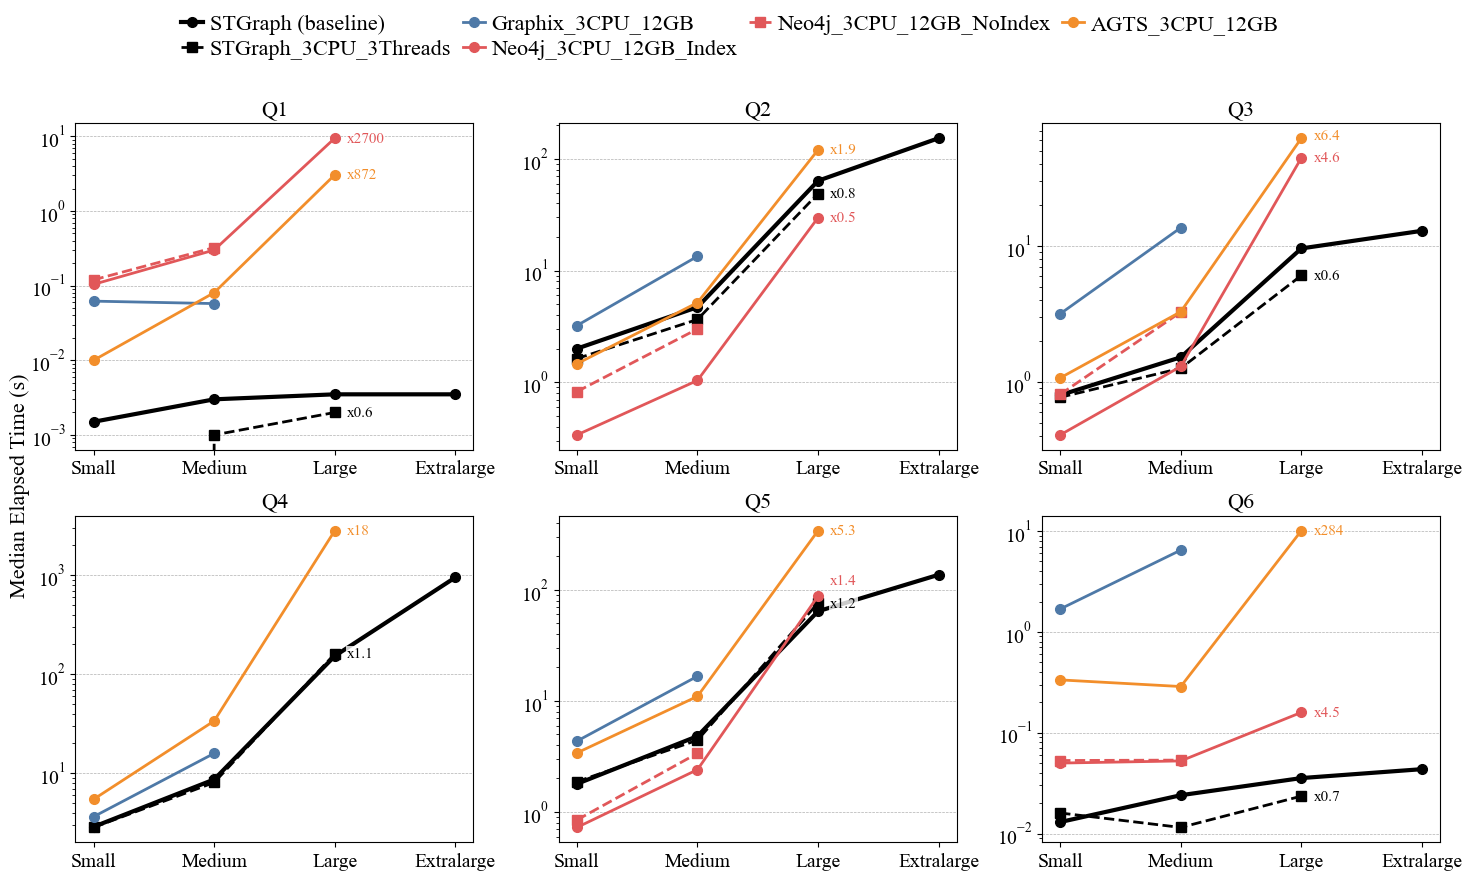

Rapporti per query: mediana / mediana di STGraph


datasetSize              Small                                  Medium        \
queryid                     Q1    Q2    Q3    Q4    Q5      Q6      Q1    Q2   
model                                                                          
STGraph_3CPU_3Threads     0.00  0.81  0.96  0.99  1.05    1.23    0.33  0.78   
Graphix_3CPU_12GB        41.33  1.61  3.95  1.26  2.43  129.58   19.17  2.85   
Neo4j_3CPU_12GB_Index    69.33  0.17  0.51   NaN  0.41    3.85  100.00  0.22   
Neo4j_3CPU_12GB_NoIndex  79.67  0.41  1.01   NaN  0.47    4.08  107.83  0.64   
AGTS_3CPU_12GB            6.67  0.73  1.34  1.90  1.90   25.69   26.83  1.10   

datasetSize                          ... Large                       \
queryid                    Q3    Q4  ...    Q3     Q4    Q5      Q6   
model                                ...                              
STGraph_3CPU_3Threads    0.83  0.93  ...  0.63   1.05  1.19    0.66   
Graphix_3CPU_12GB        8.92  1.83  ...   NaN    NaN   NaN     NaN   
Neo4j_3CPU_12GB_Index    0.86   NaN  ...  4.62    NaN  1.37    4.48   
Neo4j_3CPU_12GB_NoIndex  2.14   NaN  ...   NaN    NaN   NaN     NaN   
AGTS_3CPU_12GB           2.16  3.90  ...  6.44  18.43  5.32  283.87   

datasetSize             Extralarge                      
queryid                         Q1  Q2  Q3  Q4  Q5  Q6  
model                                                   
STGraph_3CPU_3Threads          NaN NaN NaN NaN NaN NaN  
Graphix_3CPU_12GB              NaN NaN NaN NaN NaN NaN  
Neo4j_3CPU_12GB_Index          NaN NaN NaN NaN NaN NaN  
Neo4j_3CPU_12GB_NoIndex        NaN NaN NaN NaN NaN NaN  
AGTS_3CPU_12GB                 NaN NaN NaN NaN NaN NaN  

[5 rows x 24 columns]

Mediana dei rapporti sulle query, per dimensione


datasetSize,Small,Medium,Large,Extralarge
model,,,,
STGraph_3CPU_3Threads,0.97,0.80,0.72,NaN
Graphix_3CPU_12GB,3.19,6.19,NaN,NaN
Neo4j_3CPU_12GB_Index,0.51,0.86,4.48,NaN
Neo4j_3CPU_12GB_NoIndex,1.01,2.14,NaN,NaN
AGTS_3CPU_12GB,1.90,3.09,12.44,NaN


In [ ]:
plot_group("3cpu", baseline="STGraph", threads={"STGraph_3CPU_3Threads": 3}, models=[
    "STGraph",
    "STGraph_3CPU_3Threads",
    "Graphix_3CPU_12GB",
    "Neo4j_3CPU_12GB_Index",
    "Neo4j_3CPU_12GB_NoIndex",
    "AGTS_3CPU_12GB",
])

## 3. Tutto limitato

Ogni sistema limitato a un core, con STGraph del paper come baseline: STGraph e Graphix su una partizione con 1 CPU e il minimo parallelismo (`STGraph_onepart`, `STGraph_1Part_1CPU`, i run rifatti, e `Graphix`); Neo4J, AGTS, AeonG e HyGraph con i valori del paper; `Neo4J_Index`: Neo4j limitato con l'indice sui timestamp (i run del paper sono senza).

Senza righe (il nome, o i thread se non 1: vedi available_models()): ['AGTS_1CPU']
Righe per configurazione e dimensione


/tmp/ipykernel_1387/2614226497.py:72: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["elapsedTime"] = pd.to_numeric(df["elapsedTime"], errors="coerce") / 1000


datasetSize,Small,Medium,Large,Extralarge
model,,,,
STGraph,12,12,36,24
STGraph_1Part_1CPU,61,60,15,81
Graphix,60,60,120,0
Neo4J_1CPU_NoIndex,50,50,0,0
AGTS_1CPU,0,0,0,0
Neo4J,160,60,80,0


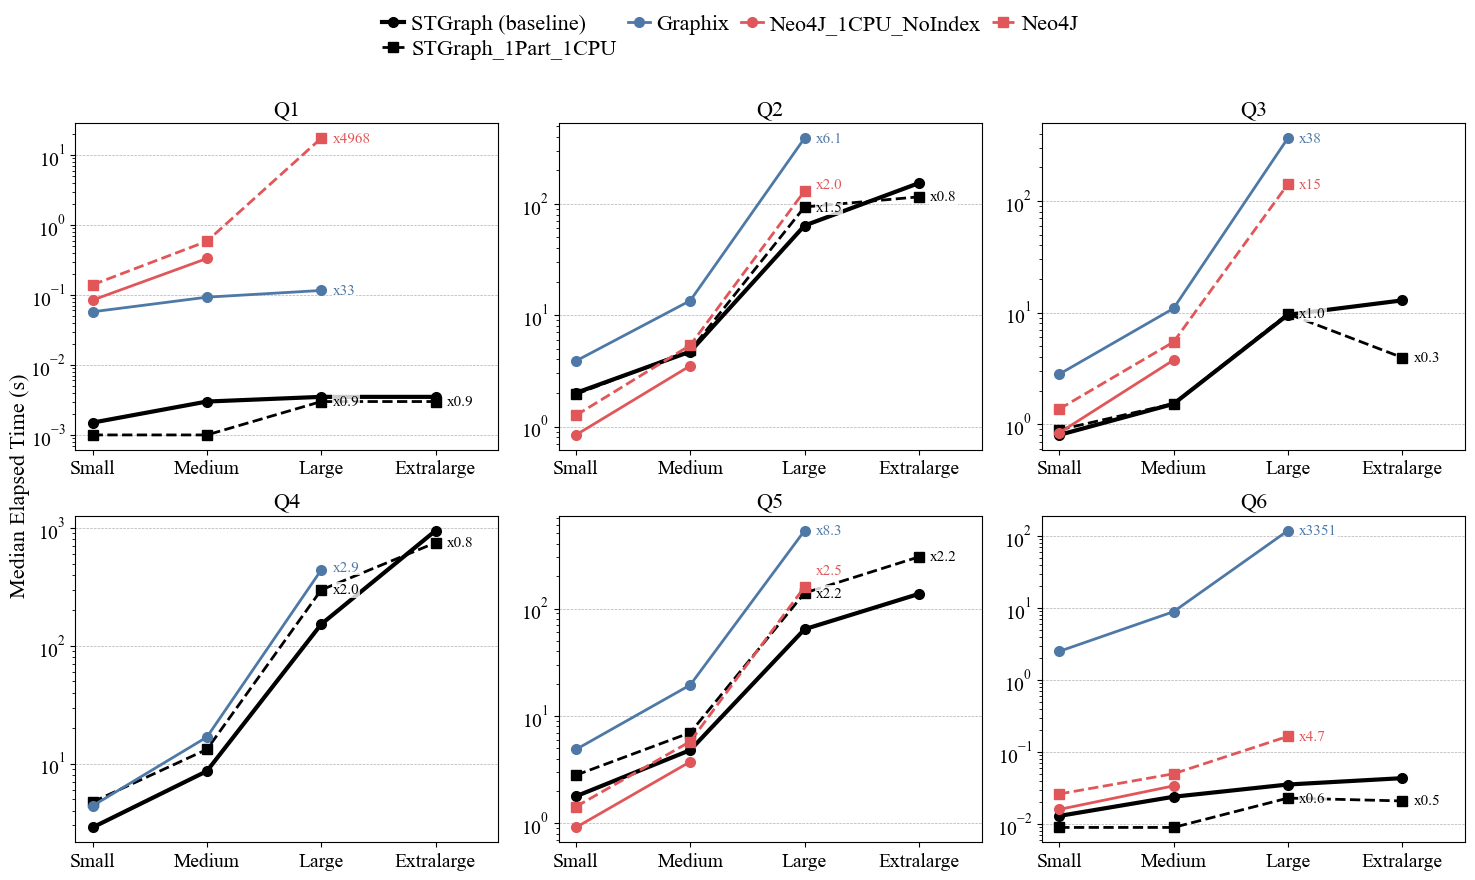

Rapporti per query: mediana / mediana di STGraph


datasetSize         Small                                  Medium              \
queryid                Q1    Q2    Q3    Q4    Q5      Q6      Q1    Q2    Q3   
model                                                                           
STGraph_1Part_1CPU   0.67  0.97  1.11  1.64  1.57    0.69    0.33  1.02  1.01   
Graphix             38.33  1.94  3.50  1.53  2.73  192.96   31.00  2.86  7.17   
Neo4J_1CPU_NoIndex  56.33  0.42  1.04   NaN  0.51    1.23  110.67  0.75  2.47   
Neo4J               93.21  0.63  1.71   NaN  0.80    2.02  195.19  1.14  3.59   

datasetSize               ...  Large                      Extralarge        \
queryid               Q4  ...     Q3    Q4    Q5       Q6         Q1    Q2   
model                     ...                                                
STGraph_1Part_1CPU  1.53  ...   1.02  1.95  2.17     0.65       0.86  0.75   
Graphix             1.94  ...  38.28  2.89  8.27  3350.99        NaN   NaN   
Neo4J_1CPU_NoIndex   NaN  ...    NaN   NaN   NaN      NaN        NaN   NaN   
Neo4J                NaN  ...  14.80   NaN  2.48     4.66        NaN   NaN   

datasetSize                                 
queryid               Q3    Q4    Q5    Q6  
model                                       
STGraph_1Part_1CPU  0.31  0.79  2.21  0.48  
Graphix              NaN   NaN   NaN   NaN  
Neo4J_1CPU_NoIndex   NaN   NaN   NaN   NaN  
Neo4J                NaN   NaN   NaN   NaN  

[4 rows x 24 columns]

Mediana dei rapporti sulle query, per dimensione


datasetSize,Small,Medium,Large,Extralarge
model,,,,
STGraph_1Part_1CPU,1.04,1.01,1.25,0.77
Graphix,3.12,5.61,20.70,NaN
Neo4J_1CPU_NoIndex,1.04,1.42,NaN,NaN
Neo4J,1.71,2.09,4.66,NaN


In [ ]:
plot_group("limited", baseline="STGraph", models=[
    "STGraph",
    "STGraph_1Part_1CPU",
    "Graphix",
    "Neo4J_1CPU_NoIndex",
    "AGTS_1CPU",
    "Neo4J"
])

## 4. STGraph Free ai diversi thread

Lo stesso AsterixDB (`conf-free`, 20 core) interrogato con più thread: sono i thread del client, che leggono in parallelo le serie temporali. Un line chart per query, una linea per numero di thread, con la **mediana** delle iterazioni; i rapporti sono sul primo numero di thread (sotto 1 più veloce). Per cambiare i thread, la lista in `threads`.

Righe per configurazione e dimensione


datasetSize,Small,Medium,Large,Extralarge
model,,,,
4 threads,60,60,60,39
8 threads,60,60,60,39
16 threads,60,60,60,40


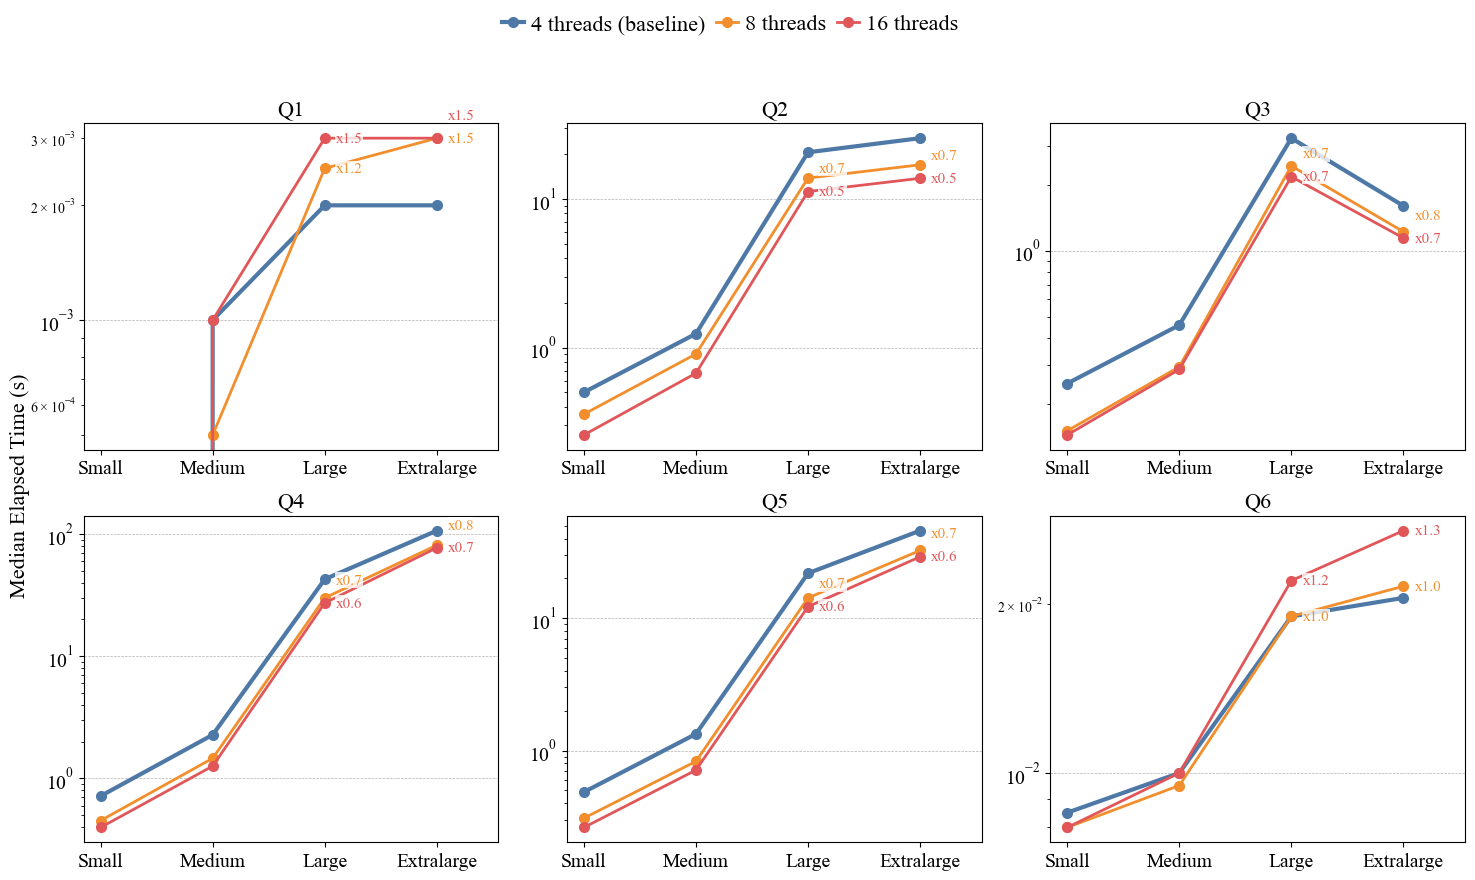

Rapporti per query: mediana / mediana di 4 threads


datasetSize Small                               Medium                    ...  \
queryid        Q1    Q2    Q3    Q4    Q5    Q6     Q1    Q2    Q3    Q4  ...   
model                                                                     ...   
8 threads     NaN  0.71  0.61  0.63  0.64  0.94    0.5  0.73  0.65  0.64  ...   
16 threads    NaN  0.52  0.58  0.55  0.54  0.94    1.0  0.54  0.63  0.55  ...   

datasetSize Large                   Extralarge                                
queryid        Q3    Q4    Q5    Q6         Q1    Q2    Q3    Q4    Q5    Q6  
model                                                                         
8 threads    0.75  0.70  0.65  1.00        1.5  0.66  0.76  0.76  0.71  1.05  
16 threads   0.67  0.64  0.56  1.16        1.5  0.54  0.71  0.72  0.63  1.32  

[2 rows x 24 columns]

Mediana dei rapporti sulle query, per dimensione


datasetSize,Small,Medium,Large,Extralarge
model,,,,
8 threads,0.64,0.64,0.73,0.76
16 threads,0.55,0.59,0.65,0.72


In [34]:
def plot_threads(name, model, threads):
    """model ai diversi threads: come plot_group, una linea per numero di thread, rapporti sul primo. Figura in figures/<archivio>/<name>/"""
    labels = {t: f"{t} threads" for t in threads}
    group_system_colors.update({label: tableau10[i] for i, label in enumerate(labels.values())})
    df = pd.concat([group_query_df([model], threads={model: t}).assign(model=labels[t]) for t in threads], ignore_index=True)
    missing = [label for label in labels.values() if label not in set(df["model"])]
    if missing:
        print(f"Senza righe: {missing}")
    show_group(df, list(labels.values()), baseline=labels[threads[0]], name=name)

plot_threads("Free_threads", model="STGraph_Free", threads=[4, 8, 16])

## 5. Tutto free

Tutti i sistemi nella configurazione free (20 core, `conf-free`, nessun limite di memoria), con `STGraph` del paper come baseline. `STGraph_Free` è a 16 thread, il valore più alto misurato: per un altro confronto cambia `threads` (4, 8 o 16). Gli altri sistemi sono a un thread.

Righe per configurazione e dimensione


datasetSize,Small,Medium,Large,Extralarge
model,,,,
STGraph,12,12,36,24
STGraph_Free,60,60,60,40
Graphix_Free,60,60,60,0
Neo4j_Free,50,50,28,0
AGTS_Free,60,60,39,0


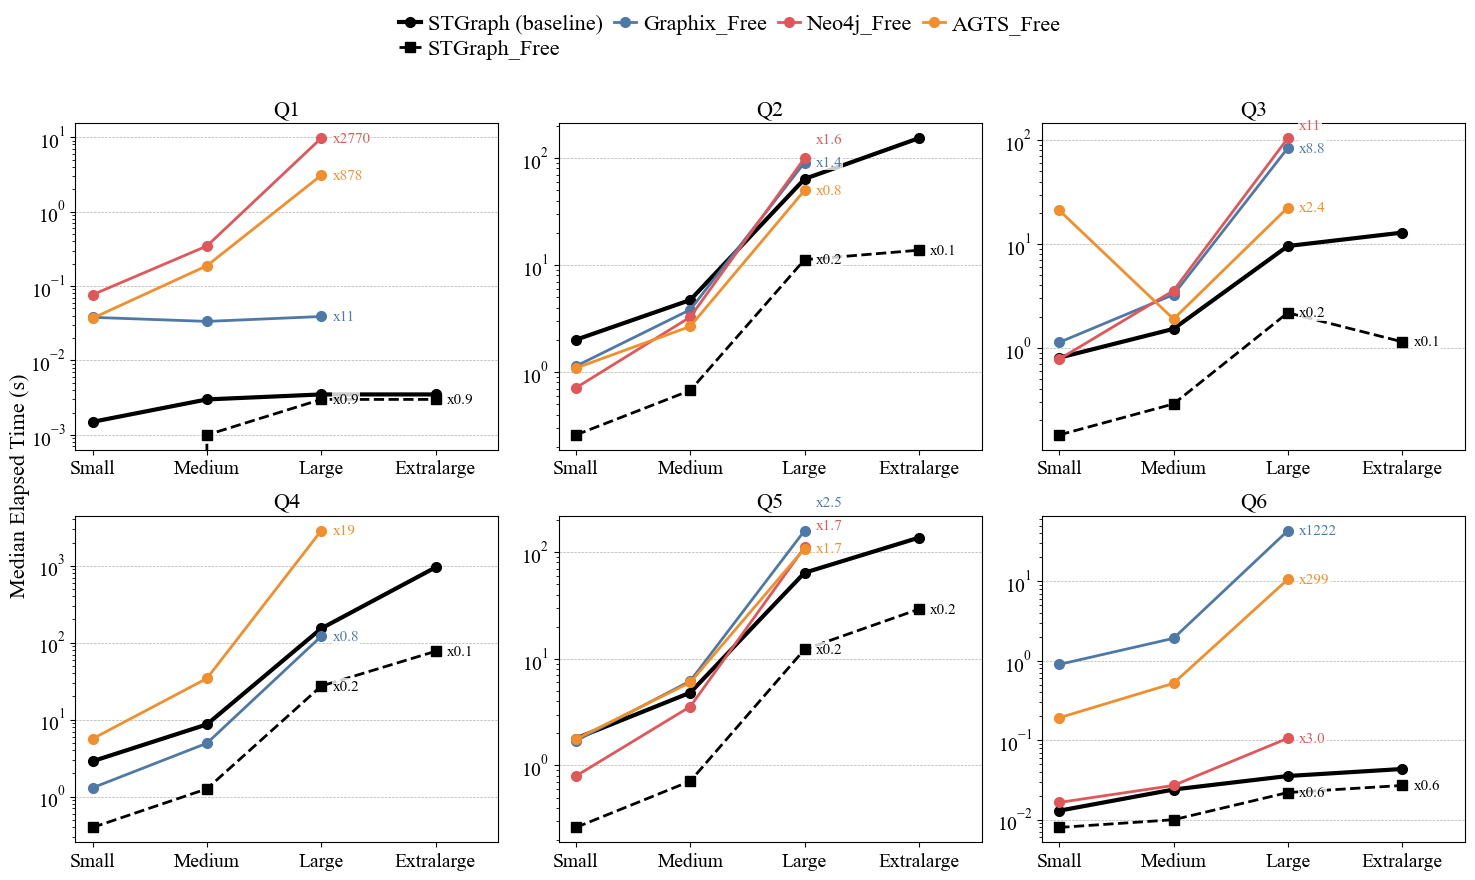

Rapporti per query: mediana / mediana di STGraph


datasetSize   Small                                  Medium                    \
queryid          Q1    Q2     Q3    Q4    Q5     Q6      Q1    Q2    Q3    Q4   
model                                                                           
STGraph_Free   0.00  0.13   0.18  0.14  0.15   0.62    0.33  0.14  0.19  0.15   
Graphix_Free  25.33  0.57   1.41  0.45  0.95  69.23   11.17  0.81  2.14  0.57   
Neo4j_Free    51.00  0.36   0.97   NaN  0.45   1.27  115.17  0.69  2.34   NaN   
AGTS_Free     24.67  0.54  26.33  1.96  0.99  14.77   62.50  0.57  1.24  3.96   

datasetSize   ...  Large                       Extralarge                    \
queryid       ...     Q3     Q4    Q5       Q6         Q1    Q2    Q3    Q4   
model         ...                                                             
STGraph_Free  ...   0.23   0.18  0.19     0.62       0.86  0.09  0.09  0.08   
Graphix_Free  ...   8.81   0.79  2.48  1221.87        NaN   NaN   NaN   NaN   
Neo4j_Free    ...  10.95    NaN  1.73     2.99        NaN   NaN   NaN   NaN   
AGTS_Free     ...   2.35  18.66  1.69   298.52        NaN   NaN   NaN   NaN   

datasetSize               
queryid         Q5    Q6  
model                     
STGraph_Free  0.21  0.62  
Graphix_Free   NaN   NaN  
Neo4j_Free     NaN   NaN  
AGTS_Free      NaN   NaN  

[4 rows x 24 columns]

Mediana dei rapporti sulle query, per dimensione


datasetSize,Small,Medium,Large,Extralarge
model,,,,
STGraph_Free,0.14,0.17,0.21,0.15
Graphix_Free,1.18,1.71,5.65,NaN
Neo4j_Free,0.97,1.12,2.99,NaN
AGTS_Free,8.36,2.60,10.50,NaN


In [35]:
plot_group("Free", baseline="STGraph", threads={"STGraph_Free": 16}, models=[
    "STGraph",
    "STGraph_Free",
    "Graphix_Free",
    "Neo4j_Free",
    "AGTS_Free",
])

## 6. Free contro limitato, per sistema

Una figura per sistema: la configurazione limitata (un core) come baseline e quella free (20 core, `conf-free`, nessun limite di memoria). I rapporti dicono quante volte free è più lento del limitato (sotto 1 è più veloce). `STGraph_Free` è a 16 thread, come nella sezione 5: per un altro confronto cambia `threads` (4, 8 o 16). Gli altri sistemi sono a un thread.

STGraph
Righe per configurazione e dimensione


datasetSize,Small,Medium,Large,Extralarge
model,,,,
STGraph_1Part_1CPU,61,60,15,81
STGraph_Free,60,60,60,40


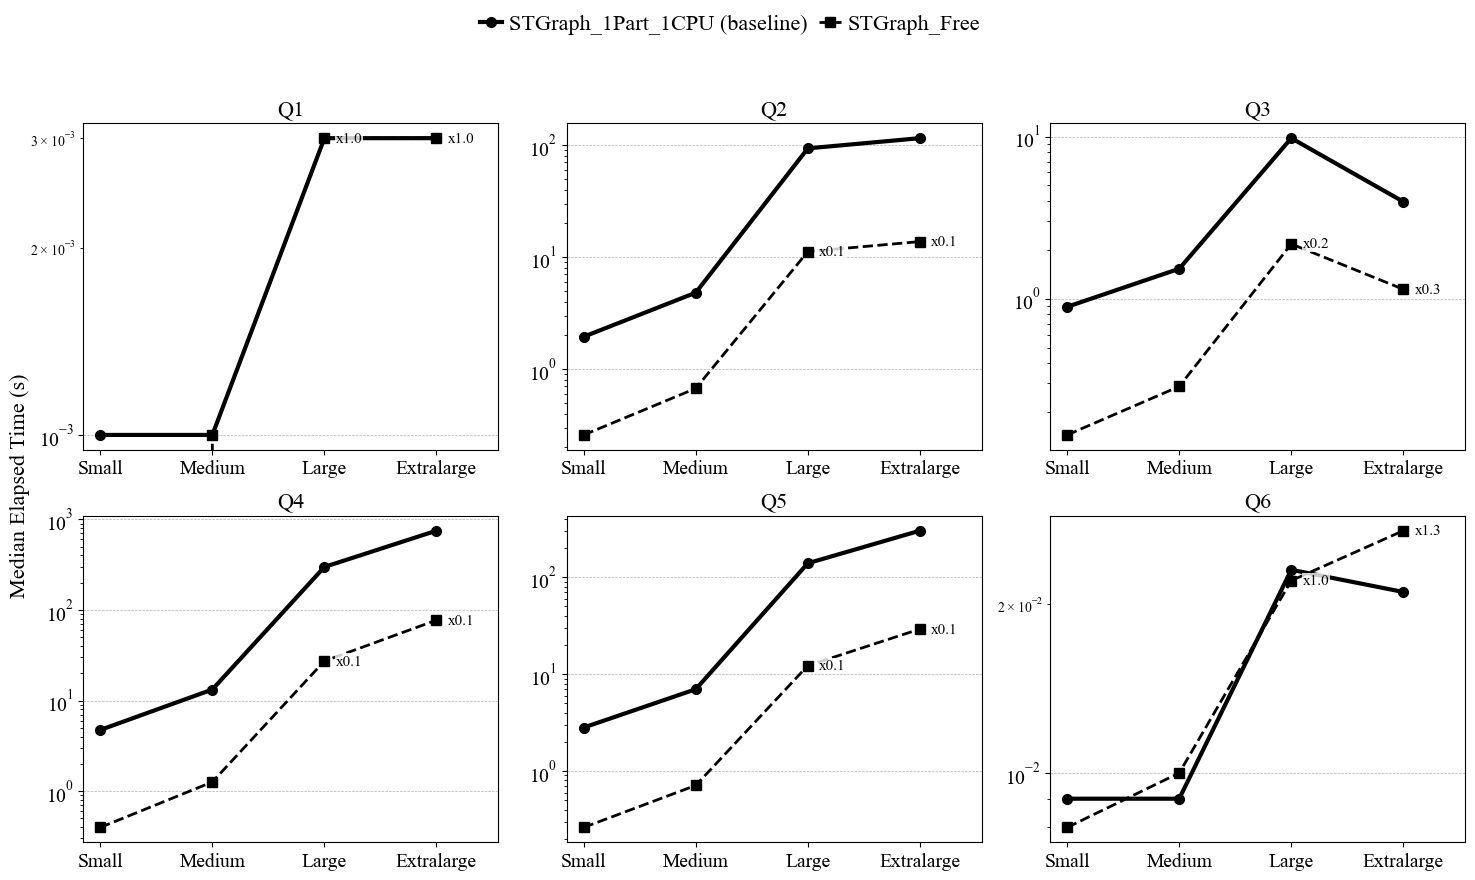

Rapporti per query: mediana / mediana di STGraph_1Part_1CPU


datasetSize  Small                               Medium                   ...  \
queryid         Q1    Q2    Q3    Q4    Q5    Q6     Q1    Q2    Q3   Q4  ...   
model                                                                     ...   
STGraph_Free   0.0  0.13  0.16  0.08  0.09  0.89    1.0  0.14  0.19  0.1  ...   

datasetSize  Large                   Extralarge                              
queryid         Q3    Q4    Q5    Q6         Q1    Q2    Q3   Q4   Q5    Q6  
model                                                                        
STGraph_Free  0.22  0.09  0.09  0.96        1.0  0.12  0.29  0.1  0.1  1.29  

[1 rows x 24 columns]

Mediana dei rapporti sulle query, per dimensione


datasetSize,Small,Medium,Large,Extralarge
model,,,,
STGraph_Free,0.11,0.16,0.17,0.2


Graphix
Righe per configurazione e dimensione


datasetSize,Small,Medium,Large,Extralarge
model,,,,
Graphix_1CPU,60,120,60,60
Graphix_Free,60,60,60,0


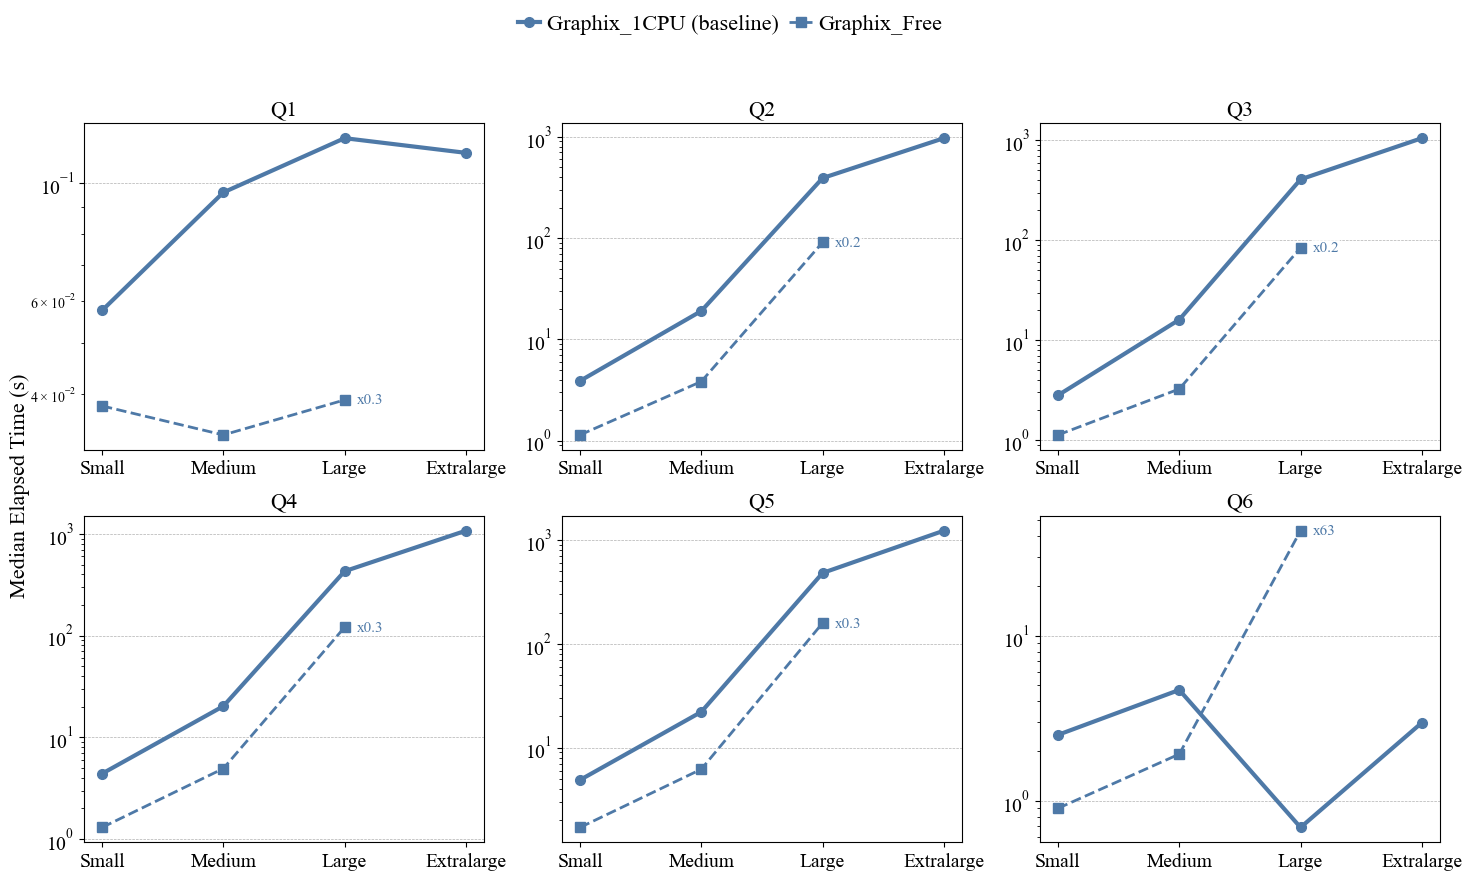

Rapporti per query: mediana / mediana di Graphix_1CPU


datasetSize  Small                             Medium                  ...  \
queryid         Q1    Q2   Q3   Q4    Q5    Q6     Q1   Q2   Q3    Q4  ...   
model                                                                  ...   
Graphix_Free  0.66  0.29  0.4  0.3  0.35  0.36   0.35  0.2  0.2  0.24  ...   

datasetSize  Large                    Extralarge                      
queryid         Q3    Q4    Q5     Q6         Q1  Q2  Q3  Q4  Q5  Q6  
model                                                                 
Graphix_Free  0.21  0.28  0.33  62.96        NaN NaN NaN NaN NaN NaN  

[1 rows x 24 columns]

Mediana dei rapporti sulle query, per dimensione


datasetSize,Small,Medium,Large,Extralarge
model,,,,
Graphix_Free,0.35,0.26,0.3,NaN


Neo4j
Righe per configurazione e dimensione


datasetSize,Small,Medium,Large,Extralarge
model,,,,
Neo4J_1CPU_NoIndex,50,50,50,50
Neo4j_Free,50,50,28,22


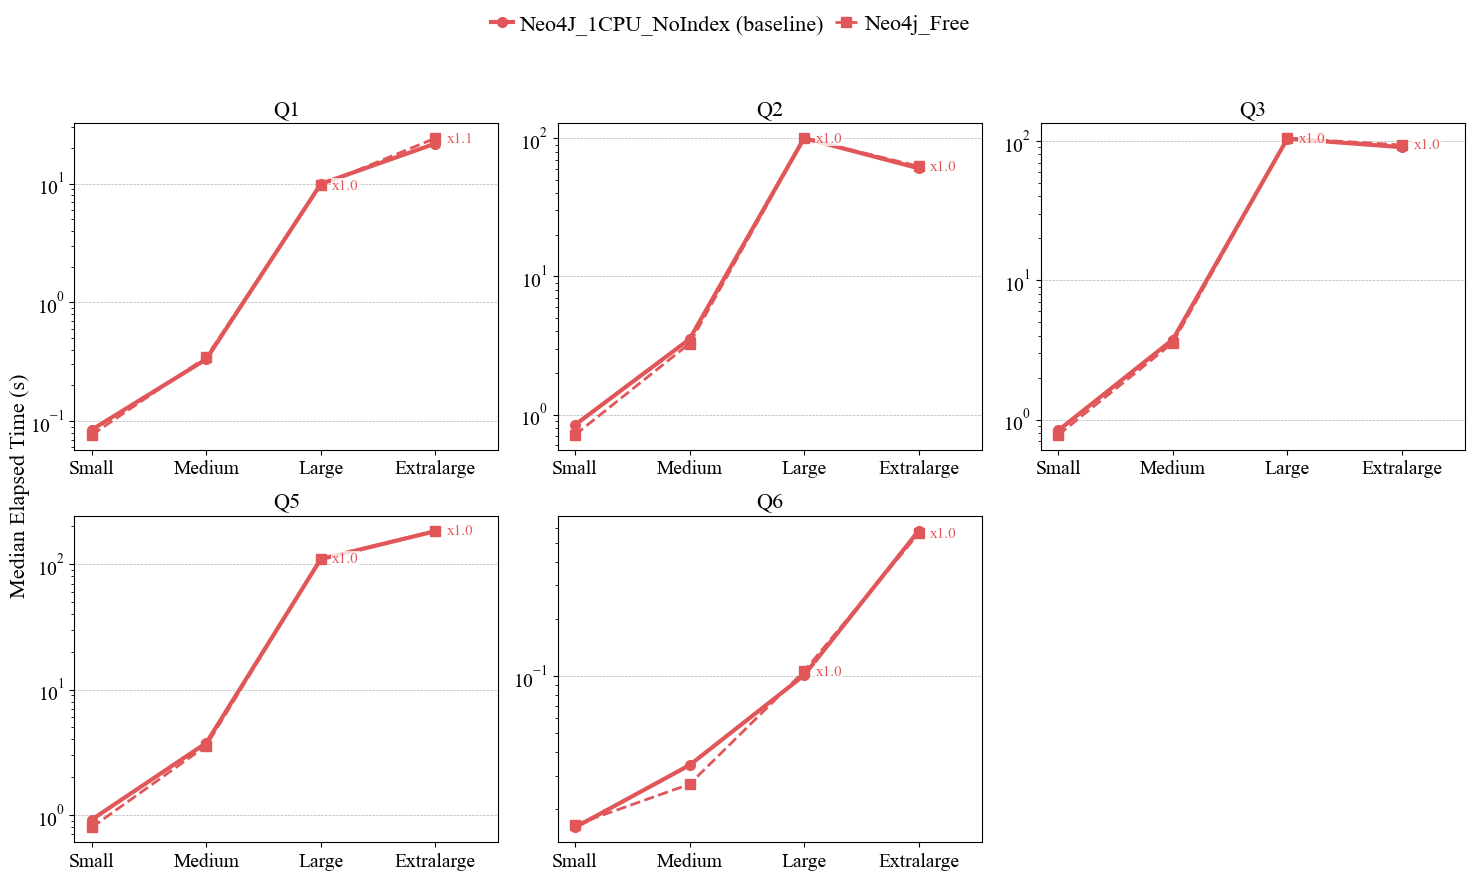

Rapporti per query: mediana / mediana di Neo4J_1CPU_NoIndex


datasetSize Small                         Medium                          \
queryid        Q1    Q2    Q3    Q5    Q6     Q1    Q2    Q3    Q5    Q6   
model                                                                      
Neo4j_Free   0.91  0.85  0.93  0.87  1.03   1.04  0.93  0.95  0.95  0.79   

datasetSize Large                        Extralarge                          
queryid        Q1   Q2    Q3    Q5    Q6         Q1    Q2    Q3    Q5    Q6  
model                                                                        
Neo4j_Free   0.97  1.0  1.01  1.01  1.05       1.11  1.03  1.04  1.01  0.97

Mediana dei rapporti sulle query, per dimensione


datasetSize,Small,Medium,Large,Extralarge
model,,,,
Neo4j_Free,0.91,0.95,1.01,1.03


AGTS
Righe per configurazione e dimensione


datasetSize,Small,Medium,Large,Extralarge
model,,,,
AGTS_1CPU,60,60,28,10
AGTS_Free,120,120,99,57


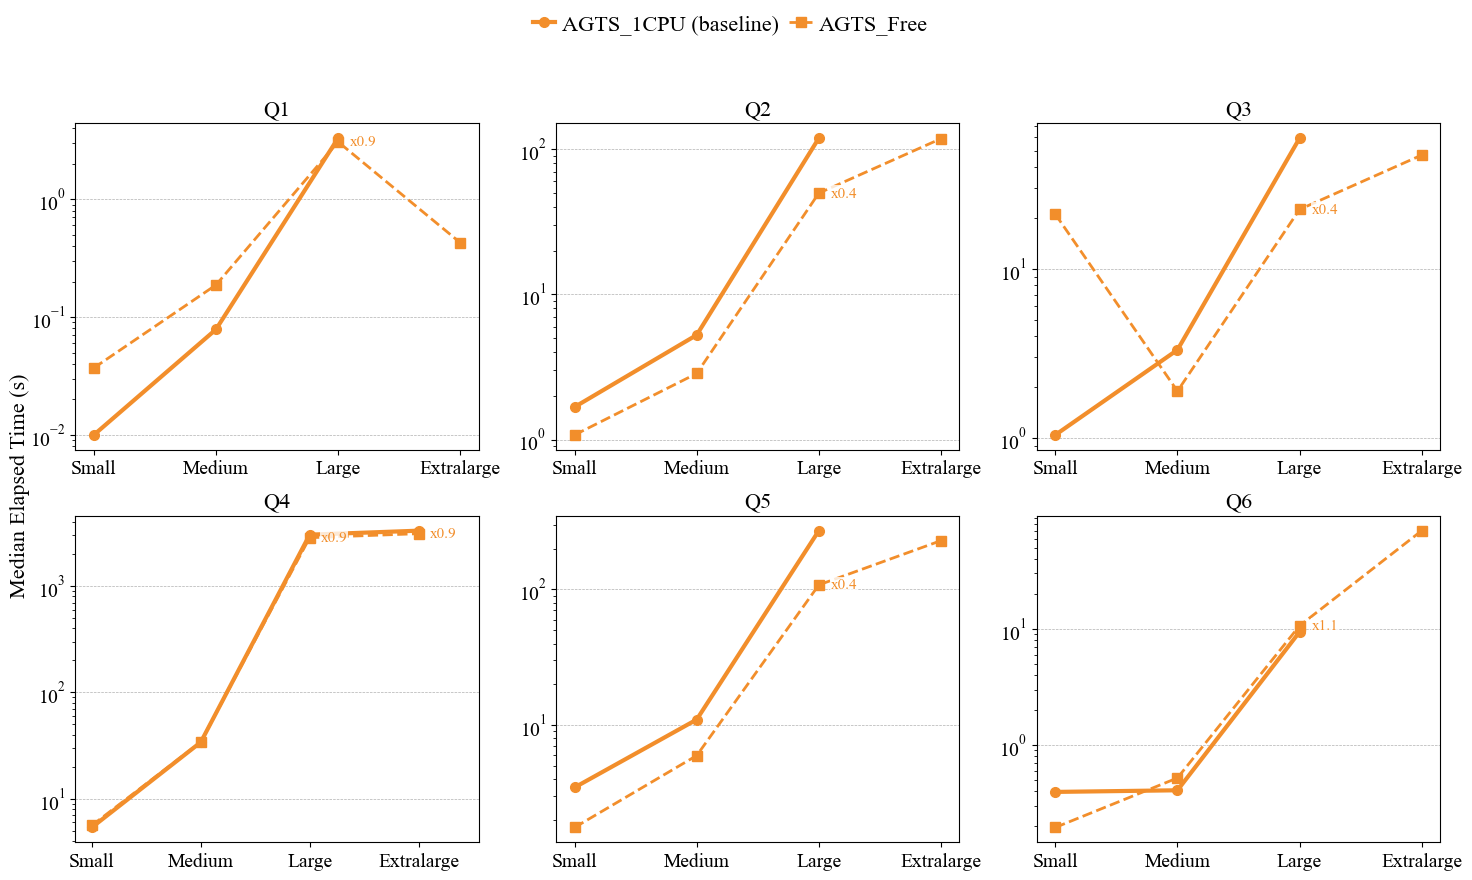

Rapporti per query: mediana / mediana di AGTS_1CPU


datasetSize Small                                Medium                    \
queryid        Q1    Q2     Q3    Q4    Q5    Q6     Q1    Q2    Q3    Q4   
model                                                                       
AGTS_Free     3.7  0.64  20.18  1.04  0.51  0.49   2.38  0.54  0.57  1.01   

datasetSize  ... Large                  Extralarge                        
queryid      ...    Q3    Q4   Q5    Q6         Q1  Q2  Q3    Q4  Q5  Q6  
model        ...                                                          
AGTS_Free    ...  0.38  0.94  0.4  1.13        NaN NaN NaN  0.94 NaN NaN  

[1 rows x 24 columns]

Mediana dei rapporti sulle query, per dimensione


datasetSize,Small,Medium,Large,Extralarge
model,,,,
AGTS_Free,0.84,0.79,0.67,0.94


In [36]:
def plot_free_vs_limited(system, limited, free, threads=None):
    """Un sistema: la configurazione limitata (baseline) e quella free. Figura in figures/<archivio>/Free_vs_limited/<system>/"""
    print(system)
    plot_group(f"Free_vs_limited/{system}", models=[limited, free], baseline=limited, threads=threads)

plot_free_vs_limited("STGraph", "STGraph_1Part_1CPU", "STGraph_Free", threads={"STGraph_Free": 16})
plot_free_vs_limited("Graphix", "Graphix_1CPU", "Graphix_Free")
plot_free_vs_limited("Neo4j", "Neo4J_1CPU_NoIndex", "Neo4j_Free")
plot_free_vs_limited("AGTS", "AGTS_1CPU", "AGTS_Free")

## Ingestion dei gruppi

L'ingestion di SmartBench dei gruppi, con i colori e gli stili delle query: la **mediana** delle esecuzioni, un line chart per fase (totale, eventi, indice) e, a destra dei punti su Large ed Extralarge, quante volte è più lenta di `STGraph` (il paper, `numMachines` -1).

Come per le query: un nome per riga in `models`. `Total` è grafo + eventi + indice; il grafico dell'ingestion del paper usa solo gli eventi. AGTS e Neo4j non hanno l'indice misurato a parte, quindi nel loro totale non compare.

Le varianti `AGTS_*` e `Neo4J_*`/`Neo4j_*` non hanno righe di ingestion: sono caricate con i fast load, che non sono cronometrati. Di AGTS c'è solo il paper. `Neo4J` è commentato: ha una sola riga valida (Small), e il suo `tsElapsedTime` (43379 s) è 10 volte la durata tra i suoi timestamp (4344 s).

In [ ]:
ingestion_phases = ["Total", "Events", "Index"]

def group_ingestion_df(models):
    """L'ingestion di SmartBench di models, con i tempi delle fasi in secondi; STGraph è quello del paper (numMachines -1)"""
    df = clean_df(ingestion_statistics.copy(deep=True), threads=1)
    df = df[(df["dataset"] == "smartbench") & df["model"].isin(models)].copy()
    df = df[(df["model"] != "STGraph") | (df["numMachines"] == -1)]
    # Senza un tempo valido (-1) l'ingestion non è stata misurata
    df = df[df["tsElapsedTime"] > 0].copy()
    df["Events"] = df["tsElapsedTime"]
    df["Index"] = pd.to_numeric(df["indexTime"], errors="coerce") / 1000
    df["Total"] = df["graphElapsedTime"] + df["Events"] + df["Index"].fillna(0)
    df["Index"] = df["Index"].where(df["Index"] > 0)
    df["datasetSize"] = df["datasetSize"].astype(str)
    return df

def plot_ingestion_group(name, models, baseline="STGraph"):
    """Un gruppo: models (come plot_group) e la baseline. Righe per configurazione e dimensione, un line chart per fase
    (mediane), rapporti del totale sulla baseline. Figura in figures/<archivio>/<name>/"""
    df = group_ingestion_df(models)
    missing = [m for m in models if m not in set(df["model"])]
    if missing:
        print(f"Senza righe di ingestion: {missing}")
    print("Righe per configurazione e dimensione")
    display(df.groupby(["model", "datasetSize"]).size().unstack(fill_value=0)
            .reindex(index=models, columns=group_dataset_order, fill_value=0))
    times = df.melt(id_vars=["model", "datasetSize"], value_vars=ingestion_phases, var_name="phase", value_name="time").dropna(subset=["time"])
    median = times.groupby(["phase", "datasetSize", "model"])["time"].median()
    variant = {m: [x for x in models if group_system(x) == group_system(m)].index(m) for m in models}
    sizes = [s for s in group_dataset_order if s != "Extralarge" or (df["datasetSize"] == s).any()]
    fig, axes = plt.subplots(1, len(ingestion_phases), figsize=(fig_x * 5, fig_y * 1.7), squeeze=False)
    for ax, phase in zip(axes.flat, ingestion_phases):
        for model in models:
            y = [median.get((phase, size, model), np.nan) for size in sizes]
            if np.all(np.isnan(y)):
                continue
            linestyle, marker = group_variant_styles[variant[model] % len(group_variant_styles)]
            ax.plot(sizes, y, marker=marker, markersize=7, linewidth=3 if model == baseline else 2, linestyle=linestyle,
                    color=group_system_colors.get(group_system(model), "gray"), label=model + (" (baseline)" if model == baseline else ""))
        ax.set_yscale("log")
        for size in sizes[sizes.index("Large"):]:
            label_large_ratios(ax, median, phase, models, baseline, size)
        ax.set_title(phase, fontsize=font)
        ax.tick_params(labelsize=font - 2)
        ax.yaxis.grid(True, linestyle="--", linewidth=0.5, which="major")
    fig.supylabel("Median Ingestion Time (s)", fontsize=font)
    handles = {label: handle for ax in axes.flat for handle, label in zip(*ax.get_legend_handles_labels())}
    fig.legend(handles.values(), handles.keys(), ncol=min(len(handles), 4), **legend_settings)
    plt.tight_layout()
    os.makedirs(os.path.join(figures_path, name), exist_ok=True)
    plt.savefig(os.path.join(figures_path, name, "ingestion_lines_smartbench.pdf"), bbox_inches="tight")
    plt.show()
    print("Mediana per fase (s)")
    display(median.unstack("datasetSize").reindex(columns=sizes).round(1))
    total = median.loc["Total"].unstack("model").reindex(sizes)
    print(f"Totale: mediana / mediana di {baseline}")
    display(total.drop(columns=baseline).div(total[baseline], axis=0).T.round(2))

Righe per configurazione e dimensione


datasetSize,Small,Medium,Large,Extralarge
model,,,,
STGraph,1,1,1,0
STGraph_Free,1,1,0,0
Graphix_Free,1,1,1,0


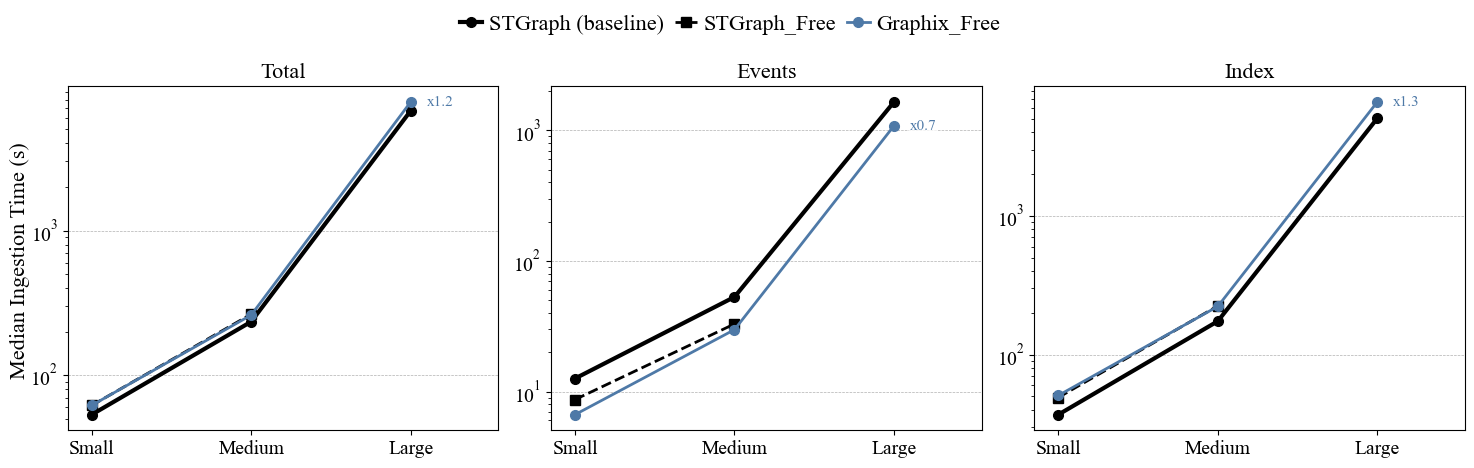

Mediana per fase (s)


datasetSize          Small  Medium   Large
phase  model                              
Events Graphix_Free    6.7    29.8  1086.2
       STGraph        12.6    53.0  1653.6
       STGraph_Free    8.7    33.0     NaN
Index  Graphix_Free   50.7   222.3  6622.3
       STGraph        36.9   174.0  5047.1
       STGraph_Free   49.0   224.2     NaN
Total  Graphix_Free   61.8   260.2  7740.0
       STGraph        53.3   234.2  6727.8
       STGraph_Free   61.7   264.1     NaN

Totale: mediana / mediana di STGraph


datasetSize,Small,Medium,Large
model,,,
Graphix_Free,1.16,1.11,1.15
STGraph_Free,1.16,1.13,NaN


In [ ]:
plot_ingestion_group("Free", models=[
    "STGraph",
    "STGraph_Free",
    "Graphix_Free",
])

Righe per configurazione e dimensione


datasetSize,Small,Medium,Large,Extralarge
model,,,,
STGraph,1,1,1,0
STGraph_1Part_1CPU,1,1,1,1
Graphix,2,2,2,0
AGTS,21,2,3,0


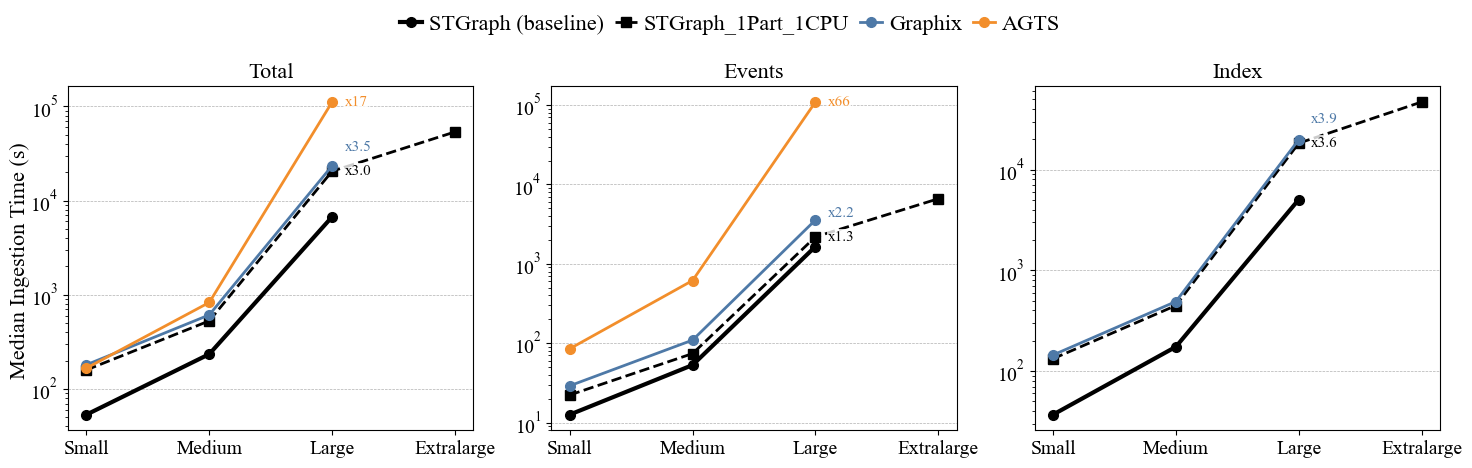

Mediana per fase (s)


datasetSize                Small  Medium     Large  Extralarge
phase  model                                                  
Events AGTS                 85.1   616.5  109561.0         NaN
       Graphix              29.1   109.4    3569.6         NaN
       STGraph              12.6    53.0    1653.6         NaN
       STGraph_1Part_1CPU   22.2    74.0    2188.5      6613.6
Index  Graphix             144.3   489.7   19815.7         NaN
       STGraph              36.9   174.0    5047.1         NaN
       STGraph_1Part_1CPU  132.4   446.9   18299.0     46945.1
Total  AGTS                166.2   828.1  111410.4         NaN
       Graphix             180.5   610.9   23424.0         NaN
       STGraph              53.3   234.2    6727.8         NaN
       STGraph_1Part_1CPU  159.0   528.0   20515.1     53595.2

Totale: mediana / mediana di STGraph


datasetSize,Small,Medium,Large,Extralarge
model,,,,
AGTS,3.12,3.54,16.56,NaN
Graphix,3.39,2.61,3.48,NaN
STGraph_1Part_1CPU,2.98,2.25,3.05,NaN


In [ ]:
plot_ingestion_group("limited", models=[
    "STGraph",
    "STGraph_1Part_1CPU",
    "Graphix",
    "AGTS",
    # "Neo4J",
])